# IMU Sensor Analysis

Статистический анализ данных промышленного манипулятора

**Автор:** Калюжина С.О.

**Датасет:** [Industrial Robotic Arm IMU Data (CASPER-1 & CASPER-2)](https://www.kaggle.com/datasets/hkayan/industrial-robotic-arm-imu-data-casper-1-and-2) - данные инерциального измерительного модуля (IMU), установленного на промышленном роботизированном манипуляторе.


Проект основан на учебном практикуме. Инструкции запуска и ограничения анализа приведены в README.


## 1.1 Описание датасета

В датасете представлены измерения одного IMU-модуля (`name = IMU8`), установленного на промышленном манипуляторе, с частотой около 10 Гц:

- `accX`, `accY`, `accZ` — показания акселерометра (могут включать вклад гравитации) по трём осям, м/с²;
- `gyroX`, `gyroY`, `gyroZ` — угловая скорость, °/с;
- `magX`, `magY`, `magZ` — индукция магнитного поля, мкТл;
- `time` — временная метка измерения в наносекундах.

Перечисленные единицы — рабочие предположения исходного анализа по диапазонам значений. Они не подтверждены метаданными CSV. Показания акселерометра нельзя автоматически считать ускорением с удалённой гравитацией.

Таким образом, данные представляют собой многомерный временной ряд.

## 1.2 Загрузка данных

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from IPython.display import display

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)

RANDOM_STATE = 42

# Сенсорные (физические) признаки и их группировка по типу датчика.
# Используются во всех разделах ноутбука.
sensor_columns = [
    "accX", "accY", "accZ",
    "gyroX", "gyroY", "gyroZ",
    "magX", "magY", "magZ"
]

groups = {
    "Акселерометр": ["accX", "accY", "accZ"],
    "Гироскоп": ["gyroX", "gyroY", "gyroZ"],
    "Магнитометр": ["magX", "magY", "magZ"]
}

# Запускайте Jupyter из корня репозитория. Путь можно переопределить IMU_DATA_PATH.
DATA_PATH = Path(os.environ.get("IMU_DATA_PATH", "data/IMU_10Hz.csv"))
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Не найден {DATA_PATH}. Поместите IMU_10Hz.csv в data/ "
        "или задайте IMU_DATA_PATH. Инструкция — data/README.md."
    )
print("Файл данных:", DATA_PATH)

from analysis_utils import load_imu, interpolate_by_time, regime_probability


Matplotlib is building the font cache; this may take a moment.


Файл данных: data/IMU_10Hz.csv (проверенная локальная копия)


## 1.3 Первичный просмотр данных

In [2]:
df = load_imu(DATA_PATH)

print("Размер датасета:", df.shape)
print(f"Количество наблюдений: {df.shape[0]}")
print(f"Количество признаков: {df.shape[1]}")

display(df.head())

Размер датасета: (874937, 11)
Количество наблюдений: 874937
Количество признаков: 11


,name,time,accX,accY,accZ,gyroX,gyroY,gyroZ,magX,magY,magZ
0,IMU8,1686062828391000000,9.773131,0.232238,0.490811,-0.1250,0.0000,0.0,0.000000,0.00,0.000000
1,IMU8,1686062828537000000,9.806650,0.263362,0.488417,0.0625,0.0000,0.0,-48.279999,-7.44,-13.230769
2,IMU8,1686062828585000000,9.794679,0.251391,0.442927,-0.1875,0.0000,0.0,-48.560001,-7.48,-13.230769
3,IMU8,1686062828682000000,9.770737,0.222661,0.445322,-0.0625,0.0625,0.0,-48.520000,-7.32,-13.461538
4,IMU8,1686062828780000000,9.792285,0.222661,0.464475,0.0000,0.0000,0.0,-48.360001,-7.28,-13.692307


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 874937 entries, 0 to 874936
Data columns (total 11 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   name    874937 non-null  object 
 1   time    874937 non-null  int64  
 2   accX    874937 non-null  float64
 3   accY    874937 non-null  float64
 4   accZ    874937 non-null  float64
 5   gyroX   874937 non-null  float64
 6   gyroY   874937 non-null  float64
 7   gyroZ   874937 non-null  float64
 8   magX    874937 non-null  float64
 9   magY    874937 non-null  float64
 10  magZ    874937 non-null  float64
dtypes: float64(9), int64(1), object(1)
memory usage: 73.4+ MB


In [4]:
print("Названия столбцов:")
print(df.columns.tolist())

Названия столбцов:
['name', 'time', 'accX', 'accY', 'accZ', 'gyroX', 'gyroY', 'gyroZ', 'magX', 'magY', 'magZ']


In [5]:
display(df.dtypes)

name      object
time       int64
accX     float64
accY     float64
accZ     float64
gyroX    float64
gyroY    float64
gyroZ    float64
magX     float64
magY     float64
magZ     float64
dtype: object

In [6]:
missing = pd.DataFrame({
    "Количество пропусков": df.isna().sum(),
    "Доля пропусков, %": df.isna().mean() * 100
})

display(missing)

,Количество пропусков,"Доля пропусков, %"
name,0,0.0
time,0,0.0
accX,0,0.0
accY,0,0.0
accZ,0,0.0
gyroX,0,0.0
gyroY,0,0.0
gyroZ,0,0.0
magX,0,0.0
magY,0,0.0


In [7]:
duplicates = df.duplicated().sum()

print(f"Количество полных дубликатов: {duplicates}")

Количество полных дубликатов: 0


### Подозрительные нулевые векторы

Полностью нулевые векторы акселерометра и магнитометра — повод для проверки. Это может быть инициализация, кодирование пропуска, особенность обработки или физическое состояние (например, близкая к нулю удельная сила при свободном падении). Без документации и контрольных измерений причина не установлена. Проверим такие строки; не будем автоматически заменять нули или удалять наблюдения.


In [8]:
mag_cols = ["magX", "magY", "magZ"]
acc_cols = ["accX", "accY", "accZ"]

# Строки, в которых все три компоненты датчика одновременно равны нулю
mag_all_zero = (df[mag_cols] == 0).all(axis=1)
acc_all_zero = (df[acc_cols] == 0).all(axis=1)

print("Строк с нулевым вектором магнитометра:", mag_all_zero.sum(),
      "| индексы:", df.index[mag_all_zero].tolist())
print("Строк с нулевым вектором акселерометра:", acc_all_zero.sum())

# Модуль вектора магнитного поля в остальных строках
mag_norm = np.sqrt((df[mag_cols] ** 2).sum(axis=1))
print(f"Модуль поля в остальных строках: от {mag_norm[~mag_all_zero].min():.1f} "
      f"до {mag_norm[~mag_all_zero].max():.1f} мкТл")

display(df.loc[:3, ["time"] + mag_cols])

Строк с нулевым вектором магнитометра: 1 | индексы: [0]
Строк с нулевым вектором акселерометра: 0


Модуль поля в остальных строках: от 40.3 до 72.9 мкТл


,time,magX,magY,magZ
0,1686062828391000000,0.000000,0.00,0.000000
1,1686062828537000000,-48.279999,-7.44,-13.230769
2,1686062828585000000,-48.560001,-7.48,-13.230769
3,1686062828682000000,-48.520000,-7.32,-13.461538


Нулевой вектор магнитометра обнаружен в первом наблюдении (индекс 0). Это согласуется с гипотезой инициализации датчика, но CSV не содержит подтверждающего статуса. Строка сохранена как **подозрительный контрольный пример**, а не размеченная ошибка. Поэтому её обнаружение алгоритмом не доказывает качество детектора.


## 1.4 Описательная статистика

In [9]:
# Описательная статистика только для сенсорных признаков:
# time — временная координата, её среднее и разброс не несут физического смысла
desc_stats = df[sensor_columns].describe().T

# Коэффициент вариации CV = s / |mean| имеет смысл только для признаков,
# не меняющих знак. Для величин, колеблющихся около нуля (гироскоп, accY, magZ и др.),
# среднее близко к нулю и CV становится бессмысленно большим — для них ставим NaN.
sign_constant = [
    (df[col] >= 0).all() or (df[col] <= 0).all()
    for col in sensor_columns
]

desc_stats["cv_%"] = np.where(
    sign_constant,
    desc_stats["std"] / desc_stats["mean"].abs() * 100,
    np.nan
)

display(desc_stats)

,count,mean,std,min,25%,50%,75%,max,cv_%
accX,874937.0,9.269243,1.516315,1.156399,9.394847,9.852139,9.957484,12.066776,16.358562
accY,874937.0,-0.679584,3.081915,-9.847351,-0.672771,-0.038307,0.246603,8.475473,NaN
accZ,874937.0,0.495106,0.234830,-0.835576,0.378284,0.495600,0.586579,1.908179,NaN
gyroX,874937.0,0.348747,28.019503,-81.750000,-4.000000,0.000000,1.187500,98.062500,NaN
gyroY,874937.0,0.663905,8.082524,-27.875000,-0.375000,0.000000,0.187500,53.250000,NaN
gyroZ,874937.0,0.018216,26.374499,-100.937500,-3.062500,0.000000,1.312500,114.125000,NaN
magX,874937.0,-33.343776,5.845444,-51.639999,-35.959999,-35.160000,-32.279999,0.000000,17.530839
magY,874937.0,19.589580,19.280610,-48.759998,14.680000,30.200001,30.879999,40.959999,NaN
magZ,874937.0,-2.480548,31.454652,-59.384617,-35.615383,6.615385,17.692308,52.769230,NaN


In [10]:
unique_counts = df.nunique()

display(unique_counts.to_frame("Количество уникальных значений"))

,Количество уникальных значений
name,1
time,874937
accX,4430
accY,7541
accZ,1036
gyroX,2875
gyroY,1298
gyroZ,3441
magX,934
magY,2241


In [11]:
constant_columns = [
    col for col in df.columns
    if df[col].nunique(dropna=False) <= 1
]

print("Константные признаки:", constant_columns)

Константные признаки: ['name']


 Поскольку данные представляют собой временной ряд, проверим последовательность временных меток и интервалы между соседними измерениями.


In [12]:
df["datetime"] = pd.to_datetime(df["time"], unit="ns", utc=True)

display(df[["time", "datetime"]].head())

,time,datetime
0,1686062828391000000,2023-06-06 14:47:08.391000+00:00
1,1686062828537000000,2023-06-06 14:47:08.537000+00:00
2,1686062828585000000,2023-06-06 14:47:08.585000+00:00
3,1686062828682000000,2023-06-06 14:47:08.682000+00:00
4,1686062828780000000,2023-06-06 14:47:08.780000+00:00


In [13]:
duration = (df["time"].iloc[-1] - df["time"].iloc[0]) / 1e9

print(f"Продолжительность записи: {duration:.2f} с")
print(f"Продолжительность записи: {duration / 60:.2f} мин")

Продолжительность записи: 87634.56 с
Продолжительность записи: 1460.58 мин


In [14]:
time_diff_sec = df["time"].diff() / 1e9

print("Временные метки строго возрастают:", bool((df["time"].diff().dropna() > 0).all()))
print("Средний интервал:", time_diff_sec.mean(), "с")
print("Медианный интервал:", time_diff_sec.median(), "с")
print("Средняя частота:", 1 / time_diff_sec.mean(), "Гц")
print("Медианная частота:", 1 / time_diff_sec.median(), "Гц")
print(f"Минимальный интервал: {time_diff_sec.min():.3f} с")
print(f"Максимальный интервал: {time_diff_sec.max():.3f} с")

# Большой интервал может указывать на пропуск или задержку; причина не установлена
print("Интервалов длиннее 0.2 с:", (time_diff_sec > 0.2).sum())

Временные метки строго возрастают: True
Средний интервал: 0.10016111121270578 с
Медианный интервал: 0.098 с
Средняя частота: 9.983914793800198 Гц
Медианная частота: 10.204081632653061 Гц
Минимальный интервал: 0.002 с
Максимальный интервал: 0.342 с
Интервалов длиннее 0.2 с: 429


In [15]:
expected_interval = 0.1

relative_error = (
    (time_diff_sec - expected_interval).abs() / expected_interval * 100
)

print(
    f"Среднее отклонение интервала от 0.1 с: "
    f"{relative_error.mean():.2f}%"
)

Среднее отклонение интервала от 0.1 с: 10.09%


In [16]:
print(
    f"Доля интервалов, отличающихся от 0.1 с более чем на 10%: "
    f"{(relative_error.dropna() > 10).mean() * 100:.2f}%"
)

Доля интервалов, отличающихся от 0.1 с более чем на 10%: 15.88%


### Вывод

В датасете 874 937 наблюдений одного IMU-модуля и 11 столбцов (столбец `name` константен). Явных пропусков (`NaN`) и полных дубликатов нет. Однако обнаружен **возможный скрытый пропуск**: в первой строке все три компоненты магнитометра равны нулю — возможна инициализация датчика.

Запись длится ≈ 24.3 ч (87 635 с), временные метки строго возрастают. Средний интервал между измерениями ≈ 0.100 с (частота ≈ 10 Гц), однако интервалы неравномерны: от 0.002 до 0.342 с, и 429 интервалов длиннее 0.2 с, что может указывать на пропуски или задержки измерений.

Описательная статистика:
- `accX` в среднем ≈ 9.27 м/с² (эта ось обычно близка к вертикали), но опускается до 1.16 м/с²; `accY` в среднем ≈ −0.68 м/с², но меняется от −9.85 до 8.48 м/с² — при движении манипулятора сила тяжести «перетекает» с оси X на ось Y; `accZ` ≈ 0.50 м/с²;
- гироскоп: медиана 0 °/с (12–18% точных нулей — манипулятор неподвижен), но размах от −101 до +114 °/с;
- магнитометр: значения от −59.4 до +52.8 мкТл, распределения сильно различаются по осям.

Коэффициент вариации приведён только для признаков, не меняющих знак (`accX`, `magX`): для величин, колеблющихся около нуля, он не имеет смысла.

---
## 2. Исследование распределений

На данном этапе исследуем распределения сенсорных показателей с помощью **ядерной оценки плотности (Kernel Density Estimation, KDE)**.

Ядерная оценка плотности — непараметрический метод восстановления плотности распределения случайной величины по имеющейся выборке. В отличие от гистограммы, KDE не разбивает значения на фиксированные интервалы, а строит сглаженную оценку плотности.

Для выборки наблюдений \(x_1, x_2, \ldots, x_n\) ядерная оценка плотности имеет вид

$$
\hat f(x)=\frac{1}{nh}\sum_{i=1}^{n}
K\left(\frac{x-x_i}{h}\right),
$$

где:

* \(x\) — точка, в которой оценивается плотность;
* \(x_i\) — отдельное наблюдение выборки;
* \(K\) — ядро, определяющее форму сглаживающей функции;
* \(h\) — ширина окна сглаживания (bandwidth);
* \(n\) — объём выборки.

Интуитивно каждое наблюдение \(x_i\) можно представить как небольшой сглаженный «холмик». KDE складывает такие холмики для всех наблюдений, в результате чего получается непрерывная оценка плотности распределения.

В работе будем использовать **гауссовское ядро**:

$$
K(u)=\frac{1}{\sqrt{2\pi}}e^{-u^2/2}.
$$

На практике наиболее важным параметром является не столько выбор формы ядра, сколько ширина окна \(h\). При слишком малом \(h\) оценка получается чрезмерно чувствительной к отдельным наблюдениям и становится «шумной». При слишком большом \(h\) распределение чрезмерно сглаживается, и его локальные особенности могут исчезнуть.

Для выбора ширины окна рассмотрим два стандартных правила — **Scott** и **Silverman** — а также выбор окна по данным **кросс-валидацией по правдоподобию**, и проверим, применимы ли стандартные правила к нашим данным. Дополнительно сравним несколько форм ядра.

Поскольку исходный датасет содержит 874 937 наблюдений, для построения KDE будем использовать большую случайную подвыборку фиксированного размера. Это необходимо только для вычислительной эффективности и не изменяет исходные данные. Для воспроизводимости результатов зафиксируем `random_state`.

В анализ включаются только физические показатели IMU:

`accX`, `accY`, `accZ`, `gyroX`, `gyroY`, `gyroZ`, `magX`, `magY`, `magZ`.

Столбец `time` не рассматривается при оценке плотности, поскольку он является временной координатой наблюдений, а не физическим сенсорным показателем.



### 2.1 Предварительный анализ структуры распределений

In [17]:
# Проверяем количество уникальных значений, долю точных нулей
# и шаг квантования (минимальное расстояние между соседними различными значениями)
distribution_check = pd.DataFrame({
    "n": df[sensor_columns].count(),
    "unique": df[sensor_columns].nunique(),
    "zero_count": (df[sensor_columns] == 0).sum(),
    "zero_share": (df[sensor_columns] == 0).mean(),
    "quant_step": [np.diff(np.unique(df[col])).min() for col in sensor_columns]
}, index=sensor_columns)

distribution_check

,n,unique,zero_count,zero_share,quant_step
accX,874937,4430,0,0.000000,0.002394
accY,874937,7541,10572,0.012083,0.002394
accZ,874937,1036,665,0.000760,0.002394
gyroX,874937,2875,105533,0.120618,0.062500
gyroY,874937,1298,158864,0.181572,0.062500
gyroZ,874937,3441,111669,0.127631,0.062500
magX,874937,934,1,0.000001,0.039997
magY,874937,2241,254,0.000290,0.039997
magZ,874937,1417,332,0.000379,0.076920


Все признаки **квантованы**: шаг ≈ 0.0024 м/с² у акселерометра, 0.0625 °/с у гироскопа и 0.04–0.077 мкТл у магнитометра. Для гироскопа доля точных нулей составляет 12–18%. Это нужно учитывать при построении KDE (см. п. 2.4).

### 2.2 Формирование подвыборки

Исходный датасет содержит 874 937 наблюдений. Для построения KDE используем случайную подвыборку фиксированного размера.

Использование подвыборки необходимо для вычислительной эффективности построения большого количества оценок плотности. При этом 50 000 наблюдений остаются достаточно большой выборкой для устойчивого визуального представления распределений.

Подвыборка выбирается случайным образом, а параметр `random_state` фиксируется для обеспечения воспроизводимости результатов.


In [18]:
RANDOM_STATE = 42
KDE_SAMPLE_SIZE = 50_000

rng = np.random.default_rng(RANDOM_STATE)

if len(df) > KDE_SAMPLE_SIZE:
    kde_sample = df[sensor_columns].sample(
        n=KDE_SAMPLE_SIZE,
        random_state=RANDOM_STATE
    )
else:
    kde_sample = df[sensor_columns].copy()

print(f"Размер исходной выборки: {len(df):,}")
print(f"Размер выборки для KDE: {len(kde_sample):,}")

Размер исходной выборки: 874,937
Размер выборки для KDE: 50,000


### 2.3 Гистограмма и ядерная оценка плотности

Для каждого сенсорного показателя построим гистограмму и ядерную оценку плотности.

Гистограмма показывает эмпирическое распределение наблюдений по интервалам, тогда как KDE представляет его в виде непрерывной сглаженной кривой. Совместное использование двух методов позволяет сопоставить исходное распределение и его сглаженное представление.

Число интервалов гистограммы выберем по правилу Фридмана–Диакониса:

$$
h_{FD} = \frac{2 \cdot IQR}{n^{1/3}},
$$

где \(IQR\) — межквартильный размах, а \(n\) — объём выборки.

Это правило учитывает разброс данных и менее чувствительно к выбросам, чем правила, основанные только на стандартном отклонении.

Для KDE будем использовать гауссовское ядро. На данном этапе используем стандартный способ выбора bandwidth, а в следующих пунктах отдельно сравним правила Scott и Silverman.


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: divide by zero encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: overflow encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: invalid value encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)


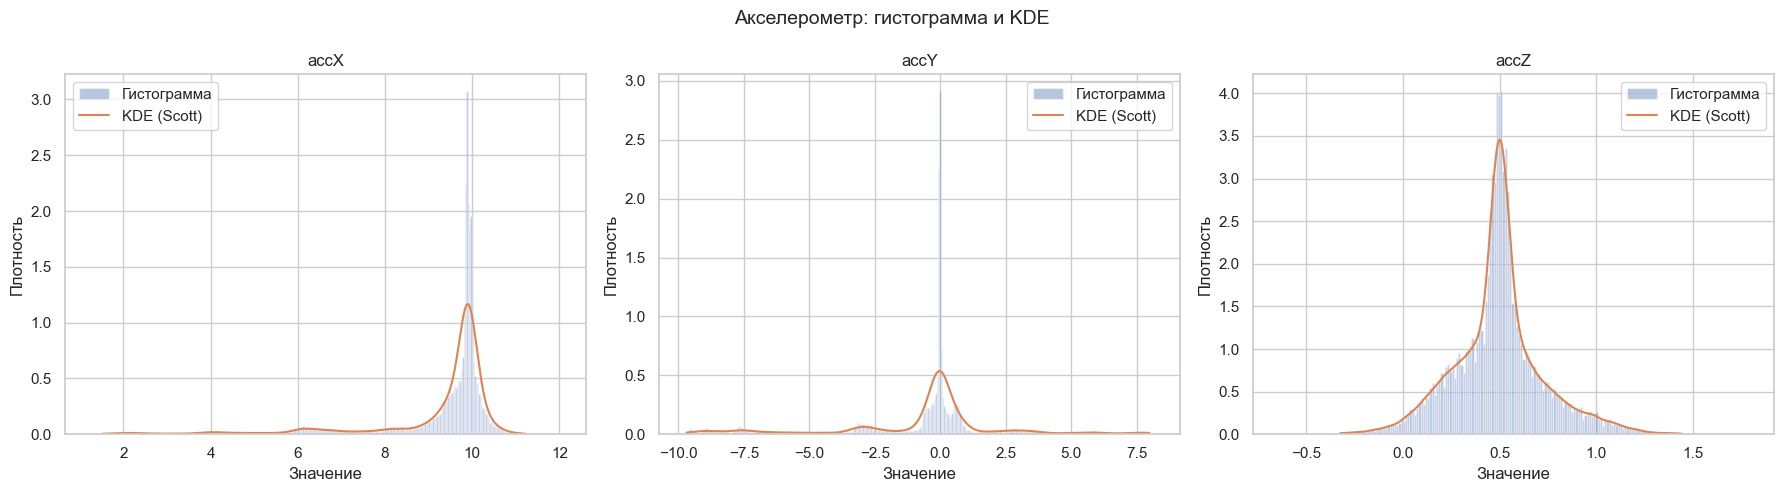

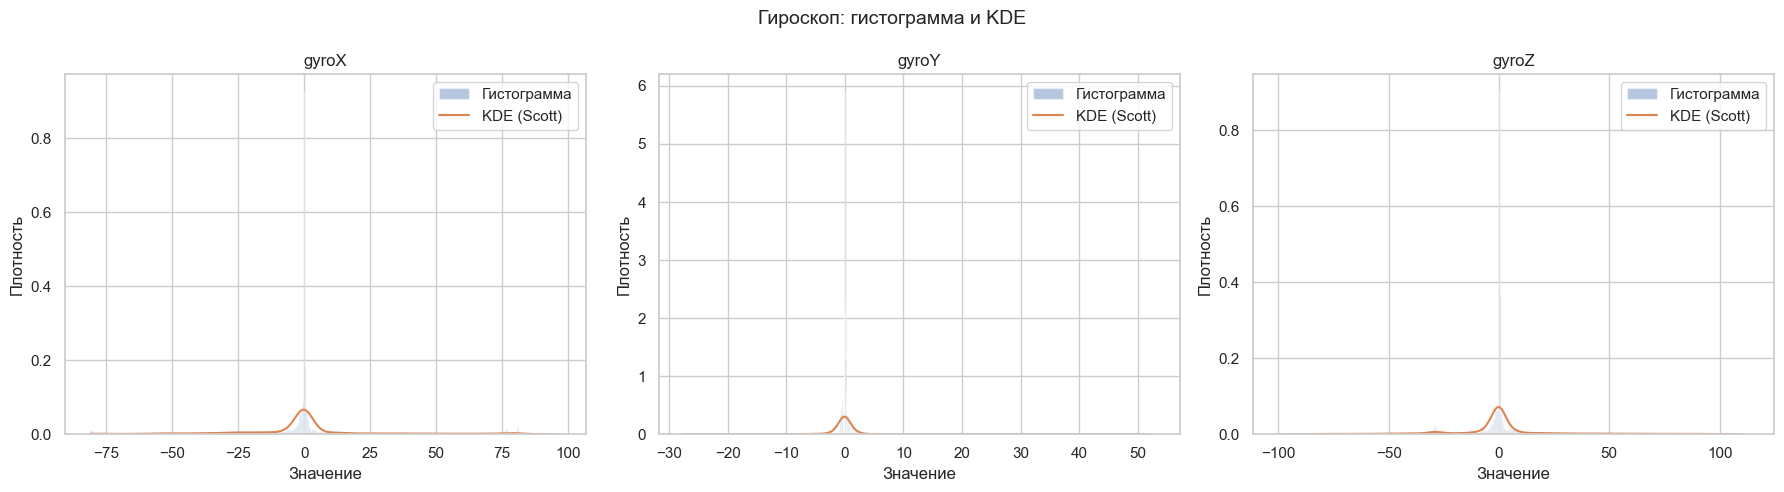

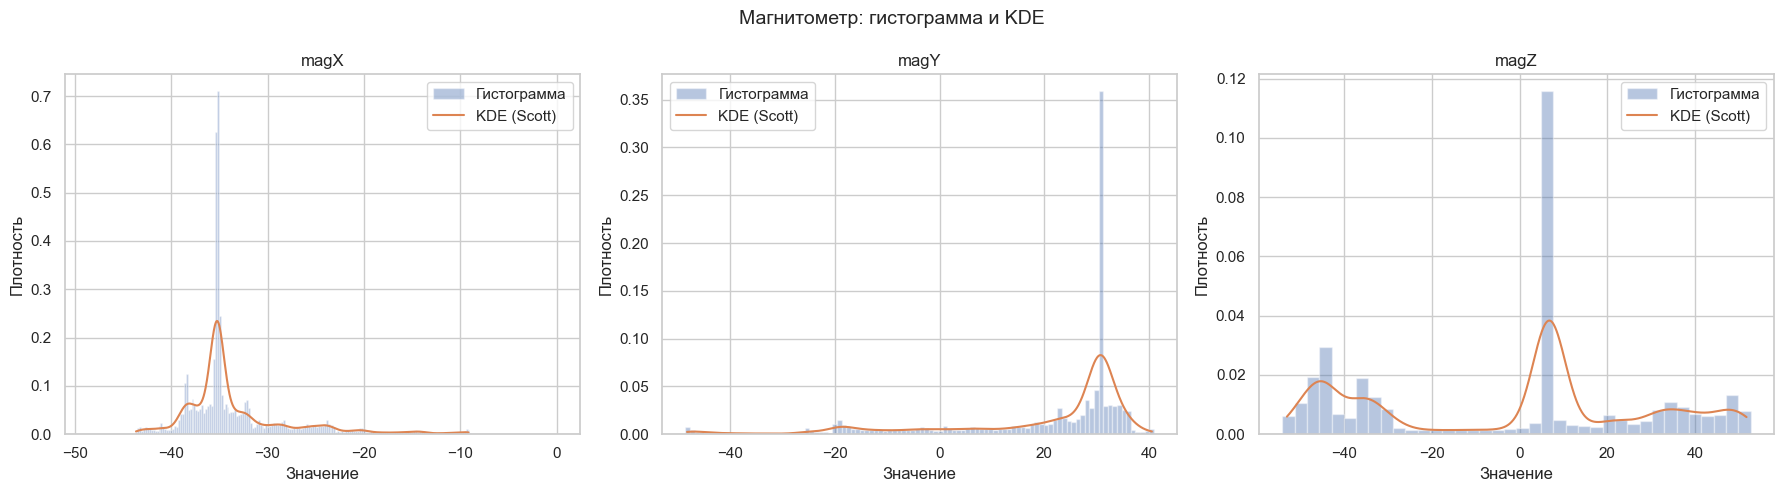

In [19]:
from scipy.stats import gaussian_kde

for group_name, columns in groups.items():
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    for ax, col in zip(axes, columns):
        x = kde_sample[col].dropna().to_numpy()
        
        # Гистограмма
        q1, q3 = np.percentile(x, [25, 75])
        iqr = q3 - q1
        bin_width = 2 * iqr / (len(x) ** (1 / 3))
        
        if bin_width > 0:
            bins = int(np.ceil((x.max() - x.min()) / bin_width))
        else:
            bins = 30
        
        ax.hist(
            x,
            bins=bins,
            density=True,
            alpha=0.4,
            label="Гистограмма"
        )
        
        # KDE с гауссовским ядром
        kde = gaussian_kde(x, bw_method="scott")
        
        x_grid = np.linspace(
            np.percentile(x, 0.1),
            np.percentile(x, 99.9),
            1000
        )
        
        ax.plot(
            x_grid,
            kde(x_grid),
            label="KDE (Scott)"
        )
        
        ax.set_title(col)
        ax.set_xlabel("Значение")
        ax.set_ylabel("Плотность")
        ax.legend()
    
    fig.suptitle(
        f"{group_name}: гистограмма и KDE",
        fontsize=14
    )
    
    plt.tight_layout()
    plt.show()

Для акселерометра и магнитометра KDE с окном по правилу Scott в целом повторяет гистограмму, хотя и сглаживает отдельные пики. Для гироскопа видно серьёзное расхождение: гистограмма имеет узкий пик в нуле (плотность до 0.8–6), а KDE — пологий «холм» с плотностью не выше 0.3. Правило Scott здесь переоценивает ширину окна. Проверим это количественно.

### 2.4 Выбор ширины окна KDE

Форма KDE существенно зависит от ширины окна сглаживания $h$. При слишком малом $h$ оценка становится «шумной», при слишком большом — скрывает особенности распределения.

**Правила Scott и Silverman** (одномерный случай):

$$
h_{Scott}=\hat\sigma\,n^{-1/5},\qquad
h_{Silverman}=\hat\sigma\left(\frac{3n}{4}\right)^{-1/5}.
$$

В `scipy.stats.gaussian_kde` атрибут `factor` — это множитель при $\hat\sigma$. Он зависит **только от объёма выборки** $n$, поэтому одинаков для всех признаков, а отношение $h_{Silverman}/h_{Scott}=(3/4)^{-1/5}\approx1.059$ постоянно. Поэтому сравнивать нужно фактическую ширину окна $h=\text{factor}\cdot\hat\sigma$.

Оба правила оптимальны (в смысле минимума среднеквадратичной ошибки MISE), если истинное распределение **нормальное**. Для островершинных и многомодальных распределений они дают чрезмерное сглаживание. Поэтому дополнительно выберем $h$ по данным — **кросс-валидацией по правдоподобию**: KDE строится на обучающей части выборки, а качество оценивается средним логарифмом плотности на отложенных наблюдениях $T$:

$$
CV(h)=\frac{1}{|T|}\sum_{x_j\in T}\log\hat f_h^{(-T)}(x_j)\ \to\ \max_h .
$$

Кросс-валидация выполняется на подвыборке из 10 000 наблюдений (3 фолда, объём обучающей части $m\approx6\,667$). Найденное окно пересчитывается на объём $n=50\,000$ по асимптотическому закону $h\propto n^{-1/5}$: $h_{CV}(n)=h_{CV}(m)\,(m/n)^{1/5}$.

**Деквантование.** Для дискретных данных правдоподобие неограниченно растёт при $h\to0$ (отложенные точки совпадают с обучающими), и кросс-валидация выбрала бы вырожденное окно. Поэтому к значениям добавляется равномерный шум $U(-\Delta/2,\Delta/2)$, где $\Delta$ — шаг квантования. Это стандартный приём, не меняющий распределение на масштабах, больших $\Delta$.

In [20]:
from scipy.stats import gaussian_kde
from sklearn.neighbors import KernelDensity
from sklearn.model_selection import GridSearchCV, KFold

CV_SAMPLE_SIZE = 10_000
CV_FOLDS = 3

rng = np.random.default_rng(RANDOM_STATE)

# Деквантованная подвыборка: шум в пределах шага квантования каждого признака
kde_sample_dq = kde_sample.copy()
for col in sensor_columns:
    step = distribution_check.loc[col, "quant_step"]
    kde_sample_dq[col] = kde_sample[col] + rng.uniform(-step / 2, step / 2, len(kde_sample))

bandwidth_results = []

for col in sensor_columns:
    x = kde_sample_dq[col].to_numpy()

    kde_scott = gaussian_kde(x, bw_method="scott")
    kde_silverman = gaussian_kde(x, bw_method="silverman")

    # Фактическая ширина окна = factor * выборочное стандартное отклонение
    h_scott = kde_scott.factor * x.std(ddof=1)
    h_silverman = kde_silverman.factor * x.std(ddof=1)

    # Кросс-валидация по правдоподобию на сетке от 0.01*h_Scott до 2*h_Scott
    cv_x = rng.choice(x, size=min(CV_SAMPLE_SIZE, len(x)), replace=False)[:, None]
    grid_search = GridSearchCV(
        KernelDensity(kernel="gaussian", rtol=1e-4),
        {"bandwidth": h_scott * np.logspace(-2, 0.3, 16)},
        cv=KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
    ).fit(cv_x)

    # Пересчёт окна с объёма обучающей части m на объём n по закону h ~ n^(-1/5)
    m_train = len(cv_x) * (CV_FOLDS - 1) / CV_FOLDS
    h_cv = grid_search.best_params_["bandwidth"] * (m_train / len(x)) ** 0.2

    bandwidth_results.append({
        "feature": col,
        "Scott_factor": kde_scott.factor,
        "Silverman_factor": kde_silverman.factor,
        "h_Scott": h_scott,
        "h_Silverman": h_silverman,
        "h_CV": h_cv,
        "h_CV / h_Scott": h_cv / h_scott
    })

bandwidth_results = pd.DataFrame(bandwidth_results).set_index("feature")

bandwidth_results.round(4)

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: divide by zero encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: overflow encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: invalid value encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: divide by zero encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: overflow encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: invalid value encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: divide by zero encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: overflow encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: invalid value encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: divide by zero encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: overflow encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: invalid value encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: divide by zero encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: overflow encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: invalid value encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: divide by zero encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: overflow encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: invalid value encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: divide by zero encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: overflow encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: invalid value encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: divide by zero encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: overflow encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: invalid value encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: divide by zero encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: overflow encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: invalid value encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)


,Scott_factor,Silverman_factor,h_Scott,h_Silverman,h_CV,h_CV / h_Scott
feature,,,,,,
accX,0.1149,0.1217,0.1753,0.1856,0.0197,0.1126
accY,0.1149,0.1217,0.3561,0.3772,0.0139,0.0391
accZ,0.1149,0.1217,0.0269,0.0285,0.0177,0.6581
gyroX,0.1149,0.1217,3.2156,3.4061,0.0882,0.0274
gyroY,0.1149,0.1217,0.9280,0.9830,0.0516,0.0556
gyroZ,0.1149,0.1217,3.0325,3.2121,0.1184,0.0391
magX,0.1149,0.1217,0.6771,0.7172,0.0763,0.1126
magY,0.1149,0.1217,2.2258,2.3576,0.0869,0.0391
magZ,0.1149,0.1217,3.6108,3.8247,0.1410,0.0391


### 2.5 Сравнение различных bandwidth

Сравним KDE, построенные с окнами по правилам Scott и Silverman и с окном, выбранным кросс-валидацией. Фоном показана гистограмма (число интервалов — по правилу Фридмана–Диакониса).

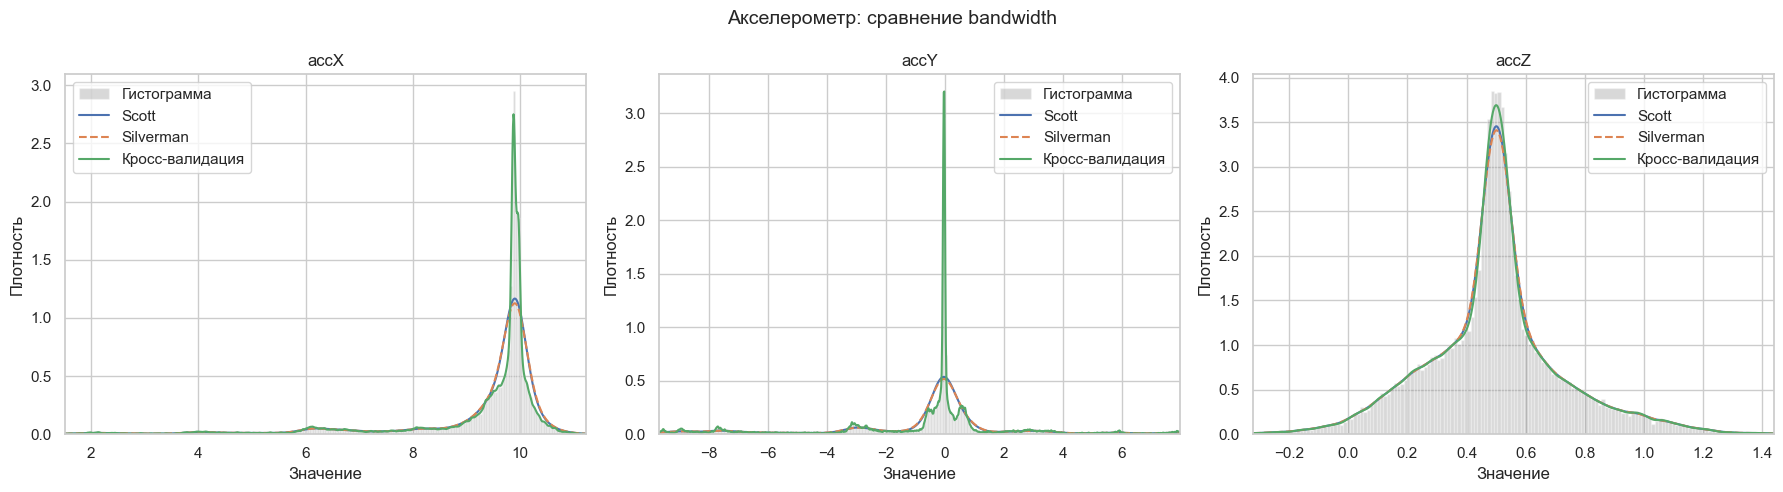

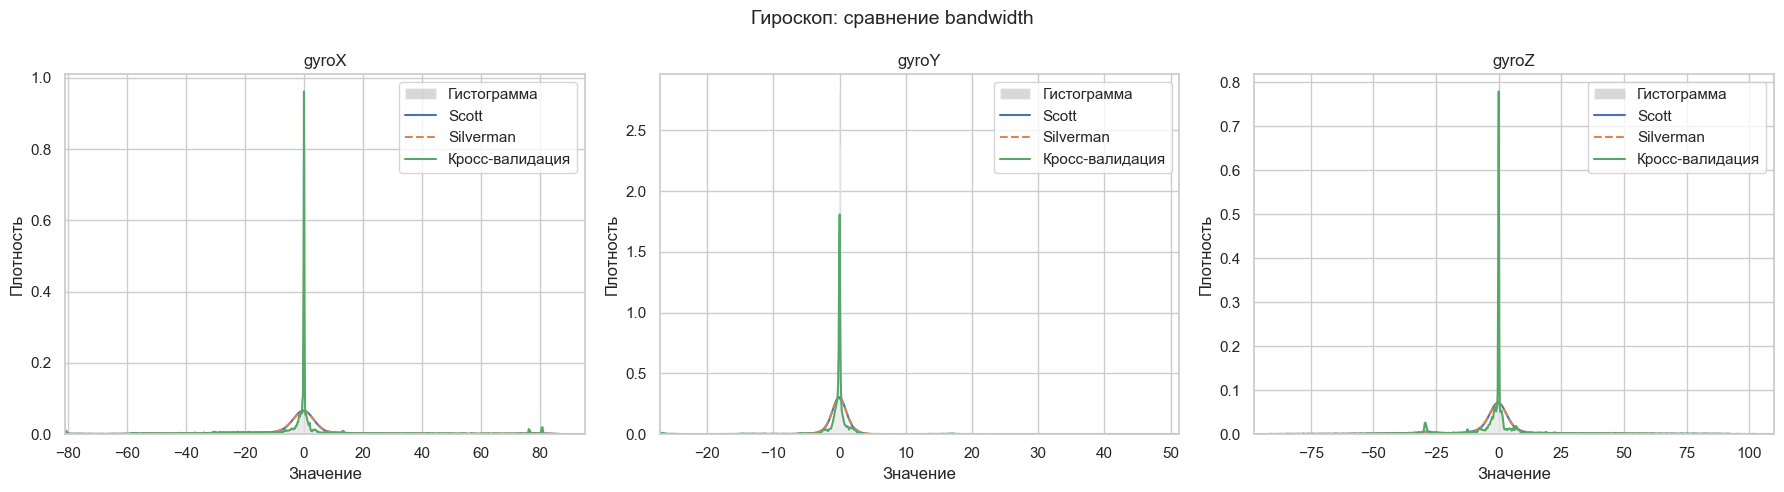

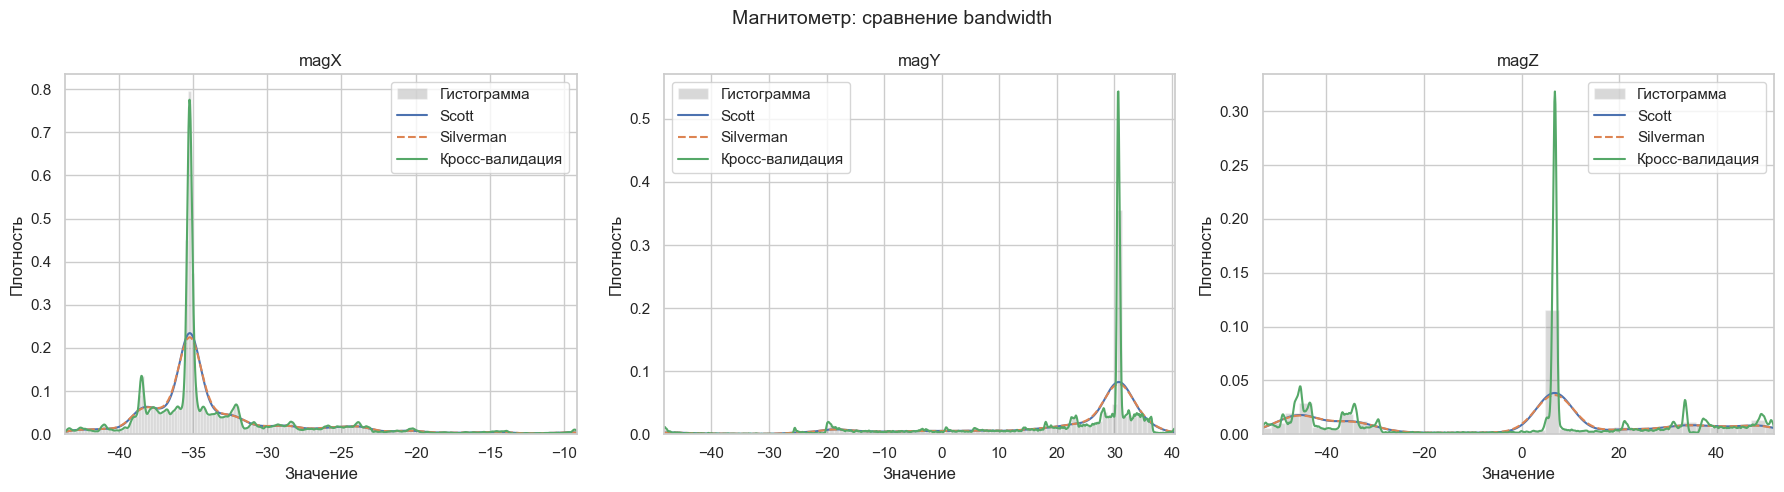

In [21]:
def kde_curve(x, h, grid):
    # Гауссовская KDE с заданной абсолютной шириной окна h
    return gaussian_kde(x, bw_method=h / x.std(ddof=1))(grid)


for group_name, columns in groups.items():

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    for ax, col in zip(axes, columns):
        x = kde_sample_dq[col].to_numpy()

        x_grid = np.linspace(
            np.percentile(x, 0.1),
            np.percentile(x, 99.9),
            1000
        )

        ax.hist(x, bins="fd", density=True, alpha=0.3, color="gray", label="Гистограмма")

        ax.plot(x_grid, kde_curve(x, bandwidth_results.loc[col, "h_Scott"], x_grid), label="Scott")
        ax.plot(x_grid, kde_curve(x, bandwidth_results.loc[col, "h_Silverman"], x_grid),
                linestyle="--", label="Silverman")
        ax.plot(x_grid, kde_curve(x, bandwidth_results.loc[col, "h_CV"], x_grid),
                label="Кросс-валидация")

        ax.set_xlim(x_grid[0], x_grid[-1])
        ax.set_title(col)
        ax.set_xlabel("Значение")
        ax.set_ylabel("Плотность")
        ax.legend()

    fig.suptitle(
        f"{group_name}: сравнение bandwidth",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()

Для гироскопа основная масса наблюдений сосредоточена около нуля, поэтому рассмотрим этот участок отдельно. Интервалы гистограммы совпадают с сеткой квантования (шаг 0.0625 °/с), а плотность нормирована на всю выборку.

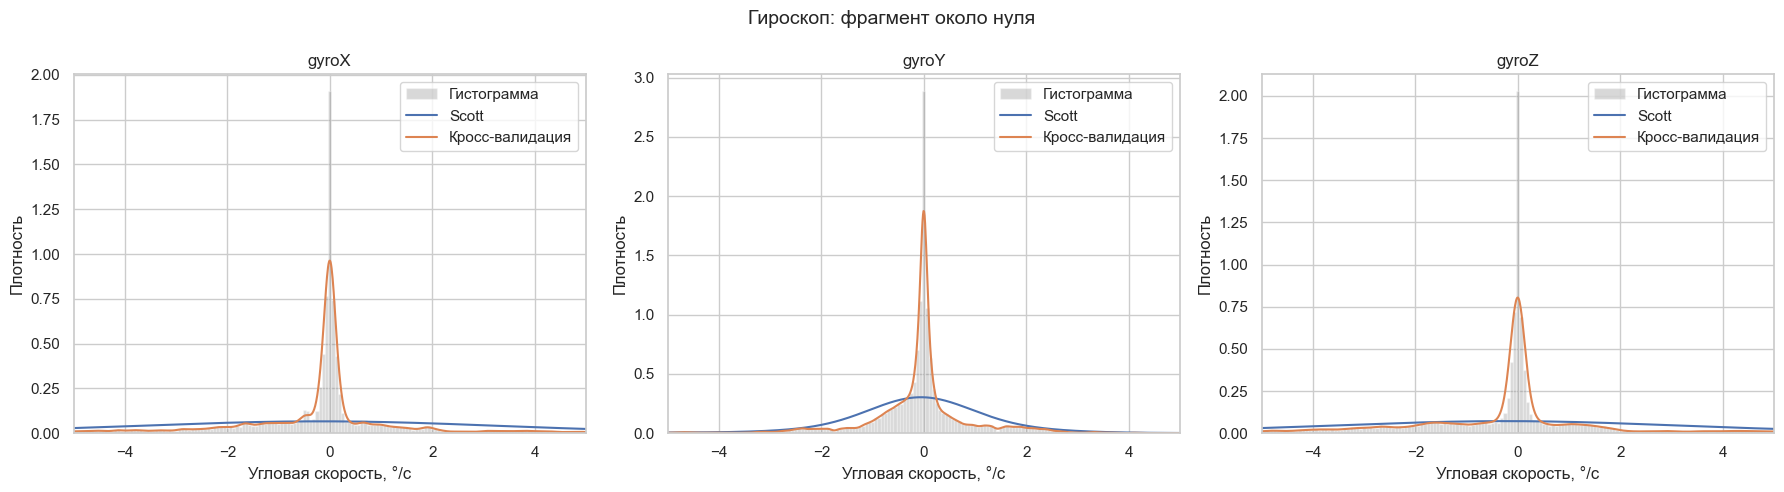

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(axes, groups["Гироскоп"]):
    x = kde_sample_dq[col].to_numpy()
    step = distribution_check.loc[col, "quant_step"]

    x_grid = np.linspace(-5, 5, 1000)
    bins = np.arange(-5 - step / 2, 5 + step, step)

    # Веса 1/(n*step): плотность нормирована на всю выборку, а не на фрагмент
    ax.hist(x, bins=bins, weights=np.full(len(x), 1 / (len(x) * step)),
            alpha=0.3, color="gray", label="Гистограмма")

    ax.plot(x_grid, kde_curve(x, bandwidth_results.loc[col, "h_Scott"], x_grid), label="Scott")
    ax.plot(x_grid, kde_curve(x, bandwidth_results.loc[col, "h_CV"], x_grid), label="Кросс-валидация")

    ax.set_xlim(-5, 5)
    ax.set_title(col)
    ax.set_xlabel("Угловая скорость, °/с")
    ax.set_ylabel("Плотность")
    ax.legend()

fig.suptitle("Гироскоп: фрагмент около нуля", fontsize=14)
plt.tight_layout()
plt.show()

### 2.6 Влияние формы ядра и ширины окна

Сравним три ядра — гауссовское, Епанечникова и прямоугольное (`tophat`). Чтобы сравнение было честным, ширина каждого ядра подбирается так, чтобы **дисперсия ядра** была одинаковой и равнялась $h_{CV}^2$: в `sklearn` параметр `bandwidth` для ядра Епанечникова — это радиус носителя (дисперсия $h^2/5$), а для прямоугольного — полуширина (дисперсия $h^2/3$).

Отдельно покажем, как меняется оценка при окне в 5 раз меньше и в 5 раз больше найденного.

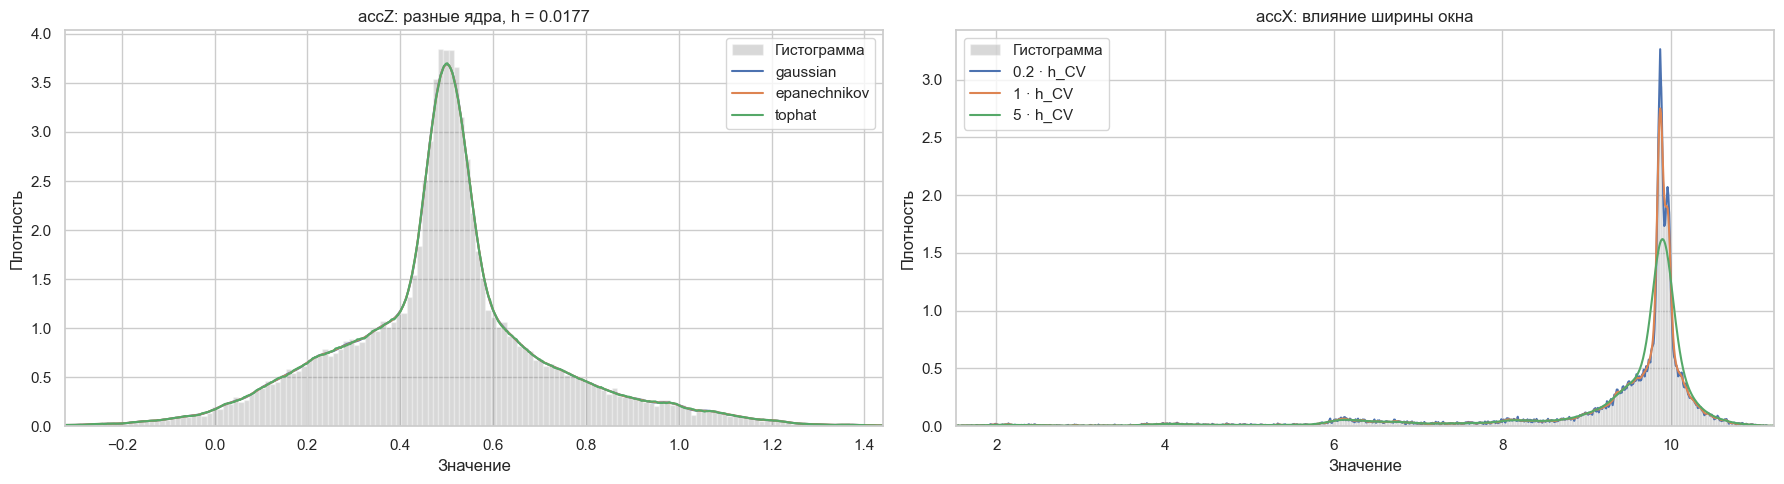

In [23]:
KERNEL_SCALE = {
    "gaussian": 1.0,
    "epanechnikov": np.sqrt(5),
    "tophat": np.sqrt(3)
}

fig, axes = plt.subplots(1, 2, figsize=(18, 5))

# Левый график: разные ядра при одинаковой дисперсии ядра
col = "accZ"
x = kde_sample_dq[col].to_numpy()
h = bandwidth_results.loc[col, "h_CV"]
x_grid = np.linspace(np.percentile(x, 0.1), np.percentile(x, 99.9), 1000)

axes[0].hist(x, bins="fd", density=True, alpha=0.3, color="gray", label="Гистограмма")
for kernel, scale in KERNEL_SCALE.items():
    kd = KernelDensity(kernel=kernel, bandwidth=h * scale).fit(x[:, None])
    axes[0].plot(x_grid, np.exp(kd.score_samples(x_grid[:, None])), label=kernel)
axes[0].set_xlim(x_grid[0], x_grid[-1])
axes[0].set_title(f"{col}: разные ядра, h = {h:.4f}")
axes[0].set_xlabel("Значение")
axes[0].set_ylabel("Плотность")
axes[0].legend()

# Правый график: недосглаживание и пересглаживание
col = "accX"
x = kde_sample_dq[col].to_numpy()
h = bandwidth_results.loc[col, "h_CV"]
x_grid = np.linspace(np.percentile(x, 0.1), np.percentile(x, 99.9), 1000)

axes[1].hist(x, bins="fd", density=True, alpha=0.3, color="gray", label="Гистограмма")
for mult in [0.2, 1, 5]:
    axes[1].plot(x_grid, kde_curve(x, mult * h, x_grid), label=f"{mult} · h_CV")
axes[1].set_xlim(x_grid[0], x_grid[-1])
axes[1].set_title(f"{col}: влияние ширины окна")
axes[1].set_xlabel("Значение")
axes[1].set_ylabel("Плотность")
axes[1].legend()

plt.tight_layout()
plt.show()

### 2.7 Асимметрия и эксцесс

Для дополнительного количественного описания формы распределений
рассчитаем коэффициенты асимметрии и эксцесса.

Асимметрия характеризует отклонение распределения от симметрии.
Эксцесс характеризует выраженность хвостов и центральной части
распределения относительно нормального распределения.

Эти показатели используются как дополнительные характеристики и
не заменяют статистические критерии проверки нормальности.

In [24]:
from scipy.stats import skew, kurtosis

shape_statistics = pd.DataFrame(index=sensor_columns)

shape_statistics["skewness"] = [
    skew(df[col].dropna(), bias=False)
    for col in sensor_columns
]

shape_statistics["excess_kurtosis"] = [
    kurtosis(df[col].dropna(), fisher=True, bias=False)
    for col in sensor_columns
]

shape_statistics

,skewness,excess_kurtosis
accX,-2.739166,7.740546
accY,-0.762666,1.868484
accZ,0.284244,1.645130
gyroX,0.491446,2.317646
gyroY,2.871021,17.121582
gyroZ,0.465529,4.292307
magX,1.755210,3.541038
magY,-1.671453,2.005146
magZ,-0.093653,-1.193974


### Вывод

KDE показала, что распределения сенсорных показателей имеют различную форму: асимметрия, тяжёлые хвосты, несколько мод (`accY`, `magY`, `magZ`) и острые пики, соответствующие неподвижному положению манипулятора.

Правила Scott и Silverman дают почти одинаковые окна — их отношение всегда равно 1.059, поэтому близость этих правил ничего не говорит об устойчивости оценки. Кросс-валидация по правдоподобию показала:
- для `accZ`, распределение которого ближе всего к колоколообразному, оптимальное окно того же порядка, что и по правилу Scott ($h_{CV}\approx0.66\,h_{Scott}$), и все оценки практически совпадают;
- для остальных признаков оптимальное окно в 9–36 раз меньше, чем по правилу Scott ($h_{CV}/h_{Scott}$ от 0.11 для `accX` и `magX` до 0.03 для `gyroX`).

Таким образом, правила Scott и Silverman, выведенные в предположении нормальности, **неприменимы** к островершинным и многомодальным распределениям гироскопа, `accX`, `accY` и магнитометра: они дают чрезмерное сглаживание и скрывают пик в нуле и отдельные моды. Для этих признаков следует использовать окно, подобранное по данным.

Даже KDE с окном, выбранным кросс-валидацией, занижает высоту пика гироскопа в нуле (≈ 1 вместо ≈ 1.9 для `gyroX`): 12–18% наблюдений — точные нули, т.е. распределение содержит дискретный атом, который непрерывная ядерная оценка воспроизвести не может. Для таких данных точнее описывать распределение как смесь: вероятность точного нуля плюс непрерывная плотность ненулевых значений.

Форма ядра (гауссовское, Епанечникова, прямоугольное) при одинаковой дисперсии ядра практически не влияет на результат, тогда как изменение ширины окна в 5 раз заметно меняет оценку: при $0.2\,h_{CV}$ появляются ложные локальные пики, при $5\,h_{CV}$ главный пик `accX` снижается примерно в 1.7 раза.

Данные являются временным рядом, поэтому соседние наблюдения зависимы. Следовательно, KDE используется здесь прежде всего как описательный и визуальный инструмент. Полученные результаты не являются формальным доказательством ненормальности распределений — проверка нормальности проводится отдельно статистическими критериями.

---
## 3. Визуальный анализ данных

На данном этапе исследуем взаимосвязи между сенсорными показателями и структуру данных с помощью условных плотностей, двумерных и временных диаграмм рассеяния, а также boxplot.

В отличие от предыдущего раздела, где каждый признак рассматривался отдельно, здесь анализируются пары признаков. Это позволяет определить, изменяется ли распределение одного показателя при изменении другого, существуют ли визуально выраженные зависимости, кластеры или участки повышенной вариативности.

Для двух случайных величин \(X\) и \(Y\) условная плотность

$$
f_{Y|X}(y|x)
$$

описывает распределение \(Y\) при заданном значении \(X=x\).

Поскольку в реальном наборе данных редко встречается большое количество наблюдений с абсолютно одинаковым значением \(X\), значения \(X\) разобьём на несколько групп. В данной работе используются четыре квартильных интервала, содержащих примерно одинаковое количество наблюдений. Для каждой группы строится KDE распределения \(Y\).

Таким образом, фактически рассматриваются распределения

$$
f_{Y|X\in G_k}(y), \qquad k=1,\ldots,4,
$$

где \(G_k\) — один из квартильных интервалов значений \(X\).

Для оценки условных плотностей, как и в предыдущем разделе, используется гауссовское ядро и правило Scott для выбора ширины окна.

Дополнительно используются scatter plot. Для пары признаков \(X\) и \(Y\) каждая точка имеет координаты

$$
(x_i,y_i),
$$

что позволяет визуально оценить характер их взаимосвязи, наличие кластеров, изменение разброса и отдельных экстремальных наблюдений.

Поскольку исходные данные являются временным рядом, отдельно исследуем изменение сенсорных показателей во времени. Для этого строятся временные диаграммы рассеяния с временем по оси \(x\) и значением сенсорного показателя по оси \(y\).

В завершение используются boxplot. Для него межквартильный размах определяется как

$$
IQR=Q_3-Q_1,
$$

а стандартные границы потенциальных выбросов задаются:

$$
L=Q_1-1.5IQR,
$$

$$
U=Q_3+1.5IQR.
$$

Наблюдения за пределами этих границ рассматриваются как потенциальные выбросы. Само по себе попадание наблюдения за пределы усов boxplot не означает ошибочность измерения и требует дальнейшей проверки статистическими методами.


### 3.1 Условная плотность

Для исследования взаимосвязи сенсорных показателей разобьём значения первого признака \(X\) на четыре квартильных интервала. Для каждого интервала построим KDE распределения второго признака \(Y\).

Если форма условных плотностей существенно изменяется между квартильными группами, это указывает на то, что распределение \(Y\) зависит от уровня \(X\). При этом данный анализ является визуальным и сам по себе не является формальным статистическим тестом зависимости.


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: divide by zero encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: overflow encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: invalid value encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)


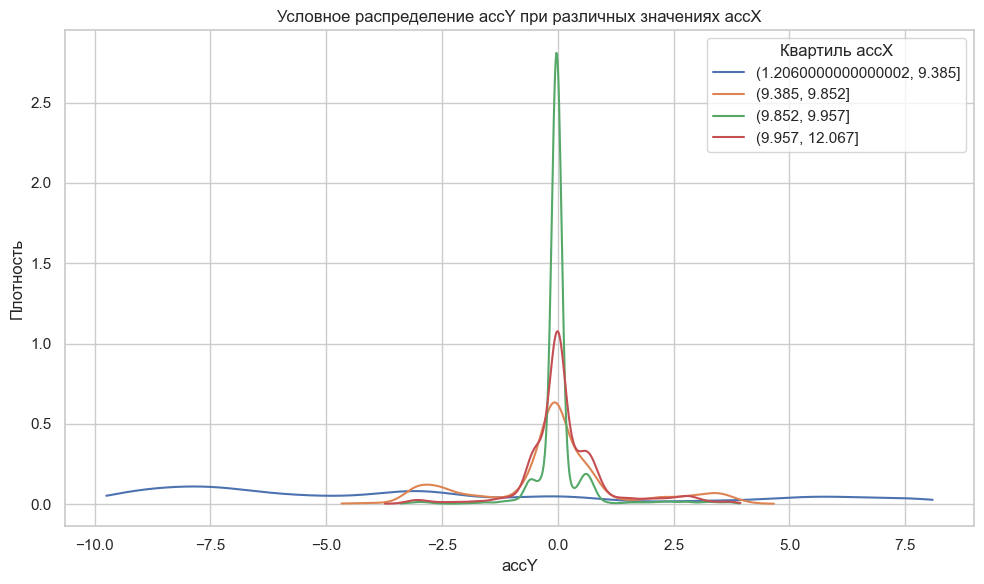

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: divide by zero encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: overflow encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: invalid value encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)


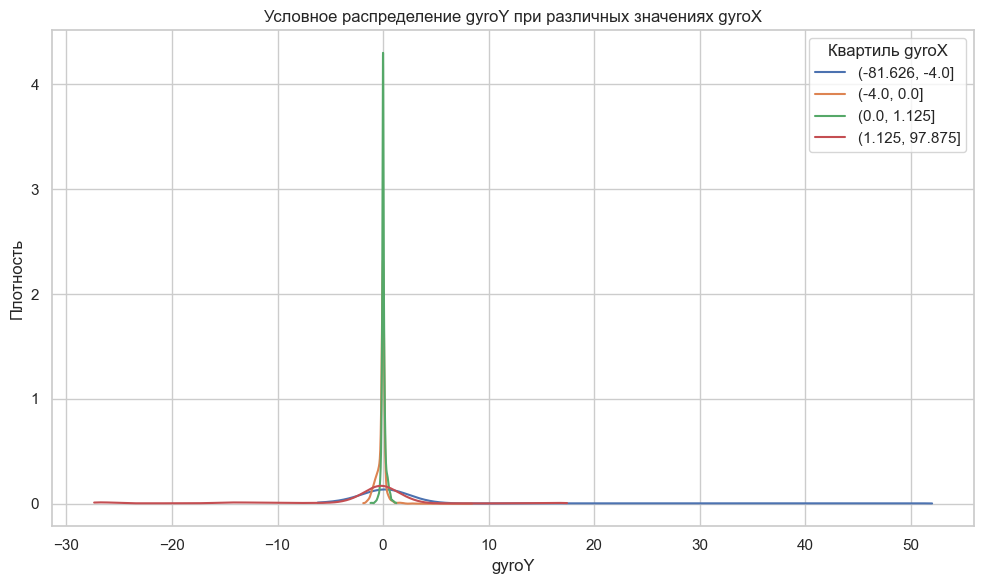

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: divide by zero encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: overflow encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: invalid value encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)


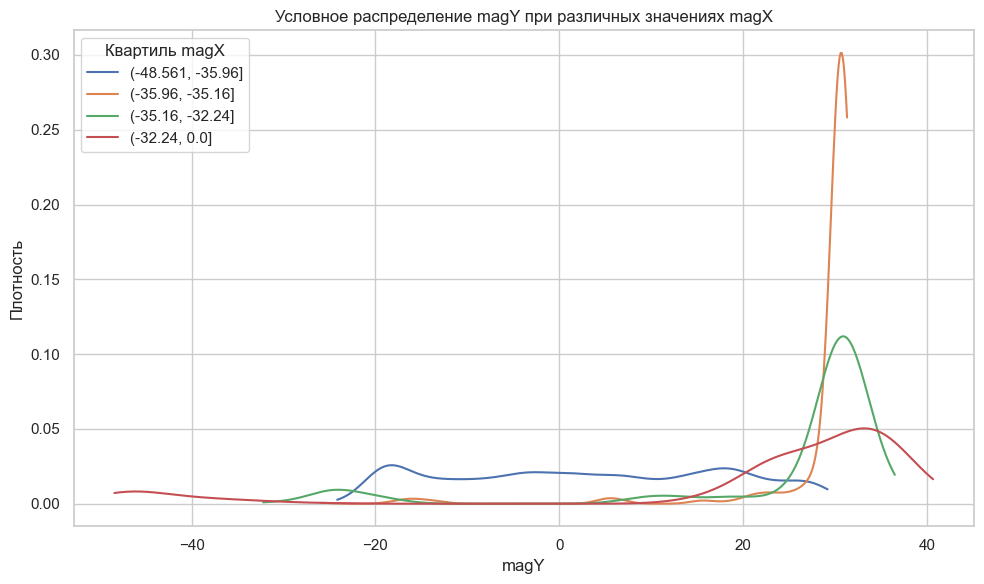

In [25]:
from scipy.stats import gaussian_kde


def conditional_density(data, x_col, y_col, title):
    temp = data[[x_col, y_col]].dropna().copy()

    # Делим X на 4 квартильные группы
    temp["x_group"] = pd.qcut(
        temp[x_col],
        q=4,
        duplicates="drop"
    )

    plt.figure(figsize=(10, 6))

    for group in temp["x_group"].cat.categories:
        y = temp.loc[
            temp["x_group"] == group,
            y_col
        ].to_numpy()

        # Gaussian KDE, bandwidth — правило Scott
        kde = gaussian_kde(
            y,
            bw_method="scott"
        )

        y_grid = np.linspace(
            np.percentile(y, 0.1),
            np.percentile(y, 99.9),
            500
        )

        plt.plot(
            y_grid,
            kde(y_grid),
            label=str(group)
        )

    plt.title(title)
    plt.xlabel(y_col)
    plt.ylabel("Плотность")
    plt.legend(title=f"Квартиль {x_col}")
    plt.tight_layout()
    plt.show()


conditional_density(
    kde_sample,
    "accX",
    "accY",
    "Условное распределение accY при различных значениях accX"
)

conditional_density(
    kde_sample,
    "gyroX",
    "gyroY",
    "Условное распределение gyroY при различных значениях gyroX"
)

conditional_density(
    kde_sample,
    "magX",
    "magY",
    "Условное распределение magY при различных значениях magX"
)

### 3.2 Условная плотность качественного признака (cdplot)

Классический график условной плотности (`cdplot` в R) показывает, как **вероятность категории** качественного признака $Y$ зависит от значения количественного признака $X$:

$$
\hat P(Y=k\mid X=x)=\frac{\hat f(x\mid Y=k)\,\hat P(Y=k)}{\hat f(x)} .
$$

Качественного признака в датасете нет, поэтому построим его по показаниям гироскопа — **режим работы манипулятора**: «движение», если модуль угловой скорости $|\omega|=\sqrt{\omega_x^2+\omega_y^2+\omega_z^2}>1$ °/с, иначе «покой» (в покое показания гироскопа — шум квантования порядка ±0.2 °/с).

Плотности оцениваются гауссовской KDE с окном по правилу Silverman (как в `cdplot` по умолчанию); для отношения двух плотностей пересглаживание менее критично, чем для самих плотностей.

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: divide by zero encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: overflow encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/scipy/_lib/_util.py:1280: RuntimeWarning: invalid value encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)


Доля наблюдений в режиме движения: 0.703


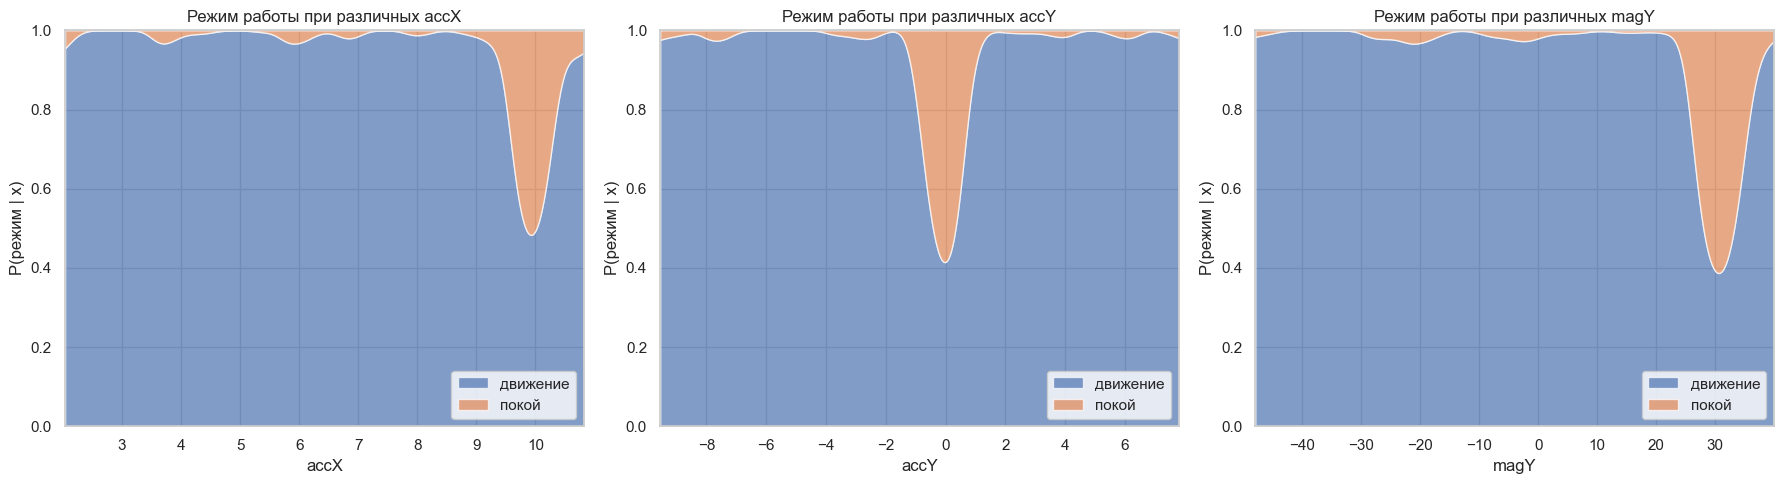

In [26]:
MOVING_THRESHOLD = 1.0  # °/с

state_sample = kde_sample.copy()
state_sample["gyro_norm"] = np.sqrt((state_sample[groups["Гироскоп"]] ** 2).sum(axis=1))
state_sample["state"] = np.where(state_sample["gyro_norm"] > MOVING_THRESHOLD, "движение", "покой")

print("Доля наблюдений в режиме движения:", round((state_sample["state"] == "движение").mean(), 3))


def cd_plot(data, x_col, ax):
    x = data[x_col].to_numpy()
    moving = (data["state"] == "движение").to_numpy()

    grid = np.linspace(np.percentile(x, 0.5), np.percentile(x, 99.5), 400)

    # Одинаковая ширина окна; знаменатель — сумма взвешенных плотностей.
    p_moving = regime_probability(x, moving, grid)

    ax.fill_between(grid, 0, p_moving, alpha=0.7, label="движение")
    ax.fill_between(grid, p_moving, 1, alpha=0.7, label="покой")
    ax.set_xlim(grid[0], grid[-1])
    ax.set_ylim(0, 1)
    ax.set_xlabel(x_col)
    ax.set_ylabel("P(режим | x)")
    ax.set_title(f"Режим работы при различных {x_col}")
    ax.legend(loc="lower right")


fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ["accX", "accY", "magY"]):
    cd_plot(state_sample, col, ax)

plt.tight_layout()
plt.show()

### 3.3 Двумерные диаграммы рассеяния

Для непосредственного визуального исследования взаимосвязи между признаками построим двумерные диаграммы рассеяния.

Будем рассматривать пары показателей внутри одной группы датчиков:

* `accX` и `accY`;
* `gyroX` и `gyroY`;
* `magX` и `magY`.

Каждая точка на графике соответствует одному наблюдению с координатами \((X_i,Y_i)\).

Такая визуализация позволяет оценить наличие линейной или нелинейной зависимости, кластеров, неоднородности разброса и отдельных экстремальных наблюдений.


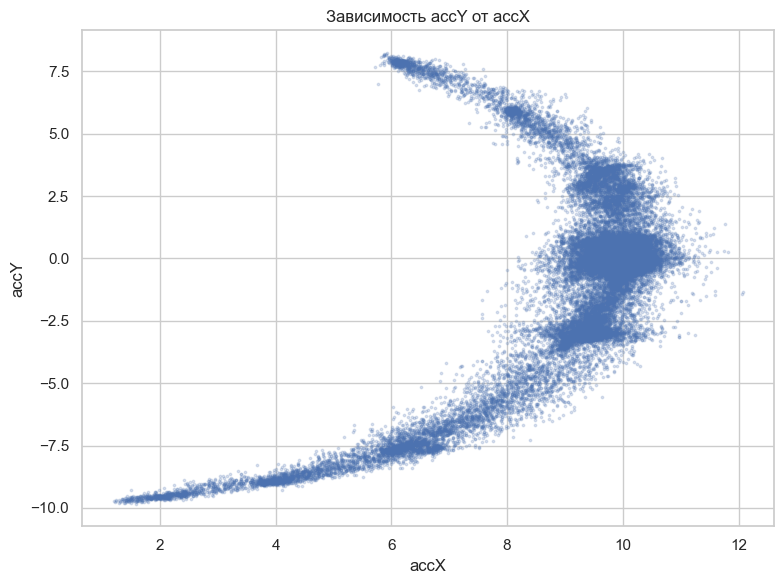

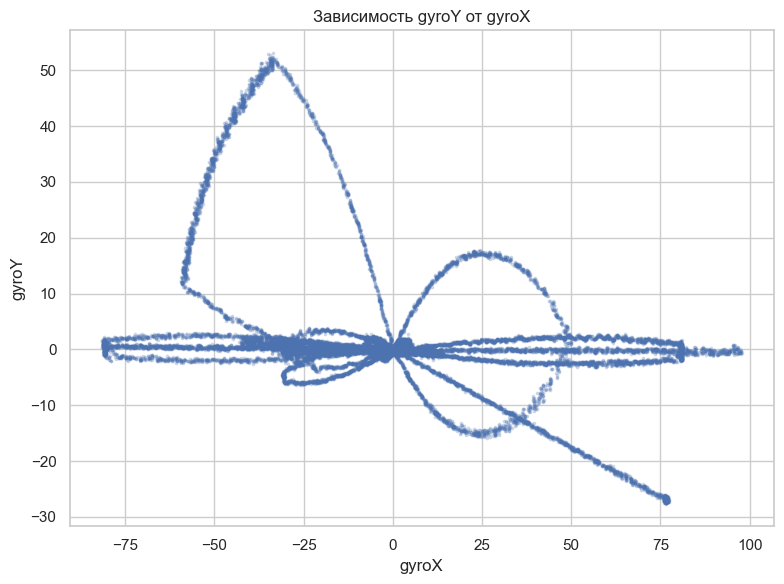

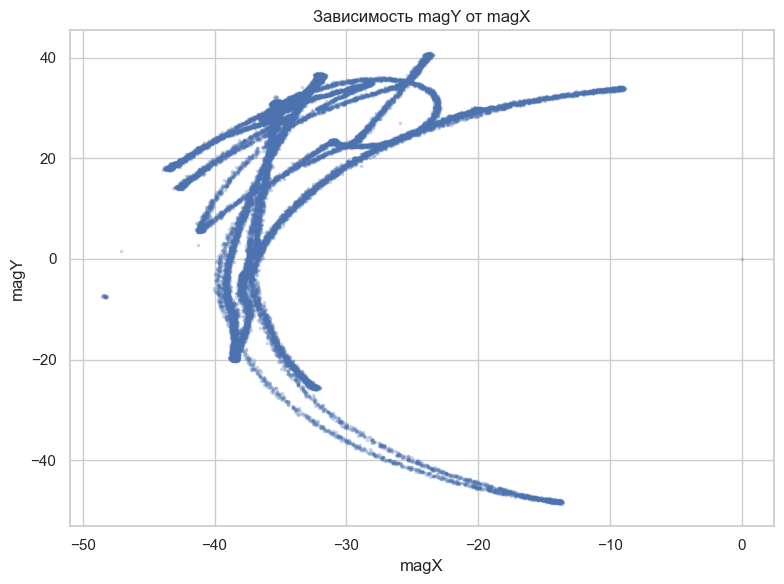

In [27]:
pairs = [
    ("accX", "accY"),
    ("gyroX", "gyroY"),
    ("magX", "magY")
]

for x_col, y_col in pairs:
    plt.figure(figsize=(8, 6))

    plt.scatter(
        kde_sample[x_col],
        kde_sample[y_col],
        s=3,
        alpha=0.2
    )

    plt.xlabel(x_col)
    plt.ylabel(y_col)
    plt.title(f"Зависимость {y_col} от {x_col}")

    plt.tight_layout()
    plt.show()

### 3.4 Временные диаграммы рассеяния

Поскольку исходные данные представляют собой временной ряд, исследуем изменение сенсорных показателей во времени.

По оси \(x\) откладывается время наблюдения, а по оси \(y\) — значение соответствующего сенсорного показателя.

Такая визуализация позволяет выявить изменение режима работы датчика, резкие скачки, участки повышенной вариативности и отдельные потенциально аномальные наблюдения.

Для удобства визуализации используется случайная подвыборка наблюдений. Исходные данные при этом не изменяются.


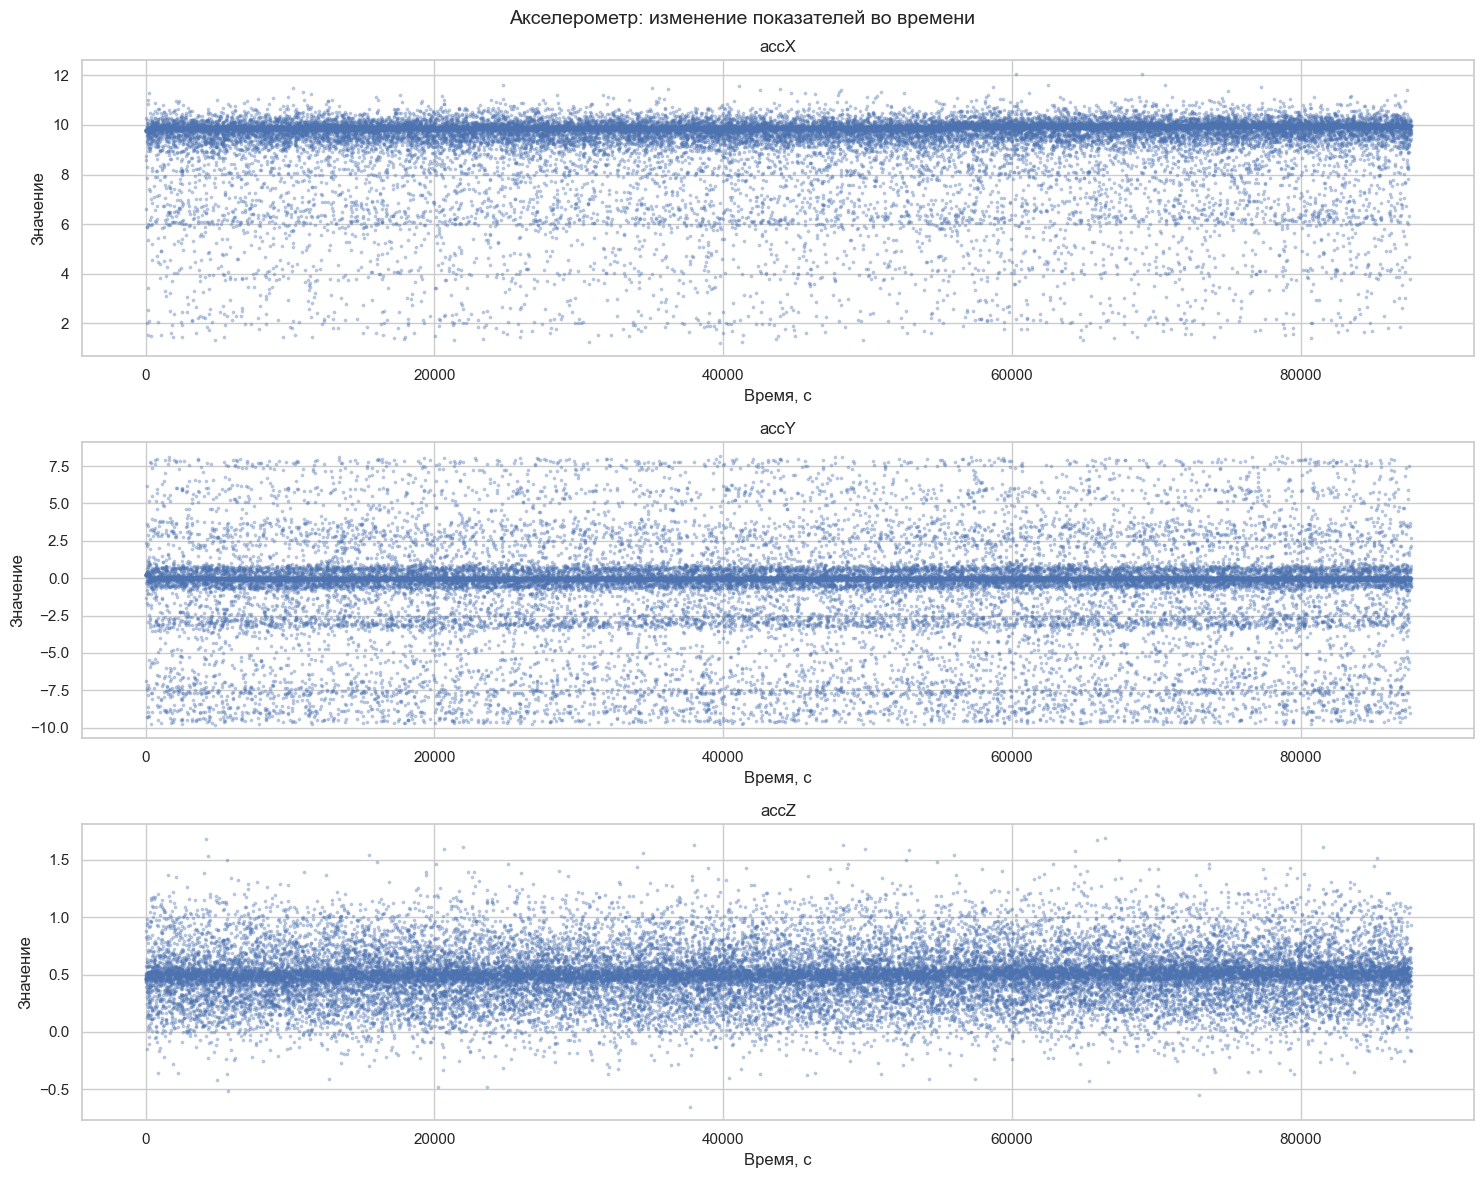

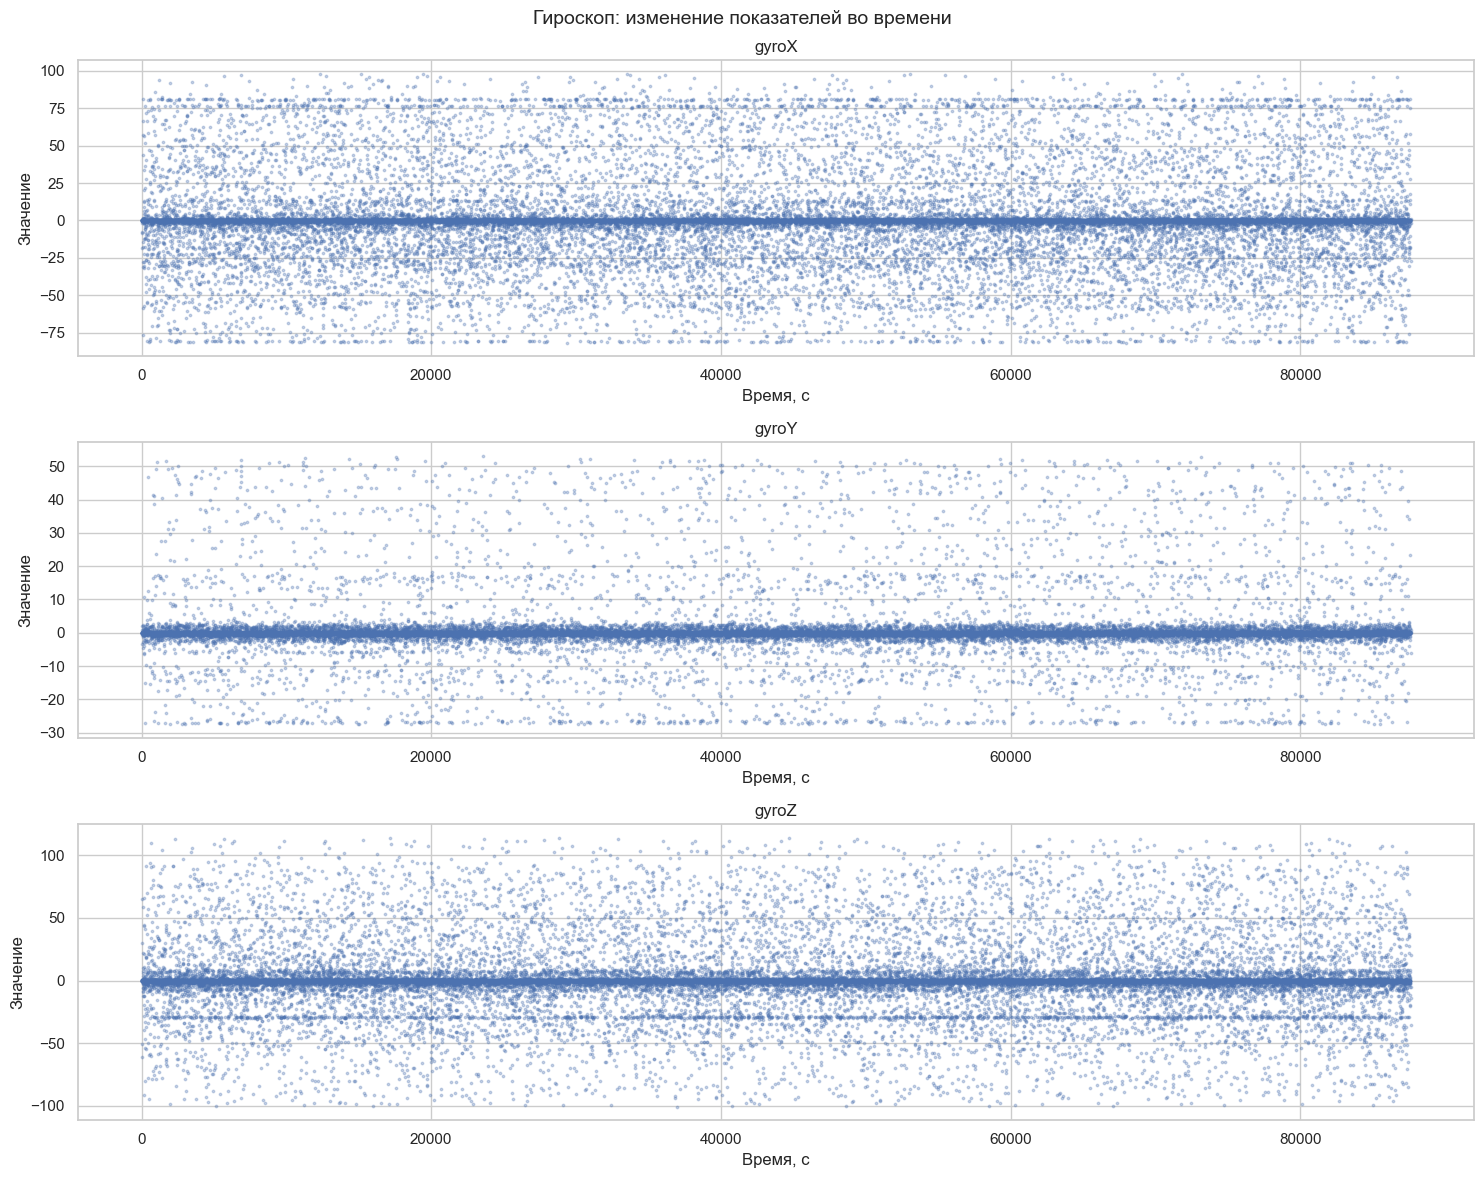

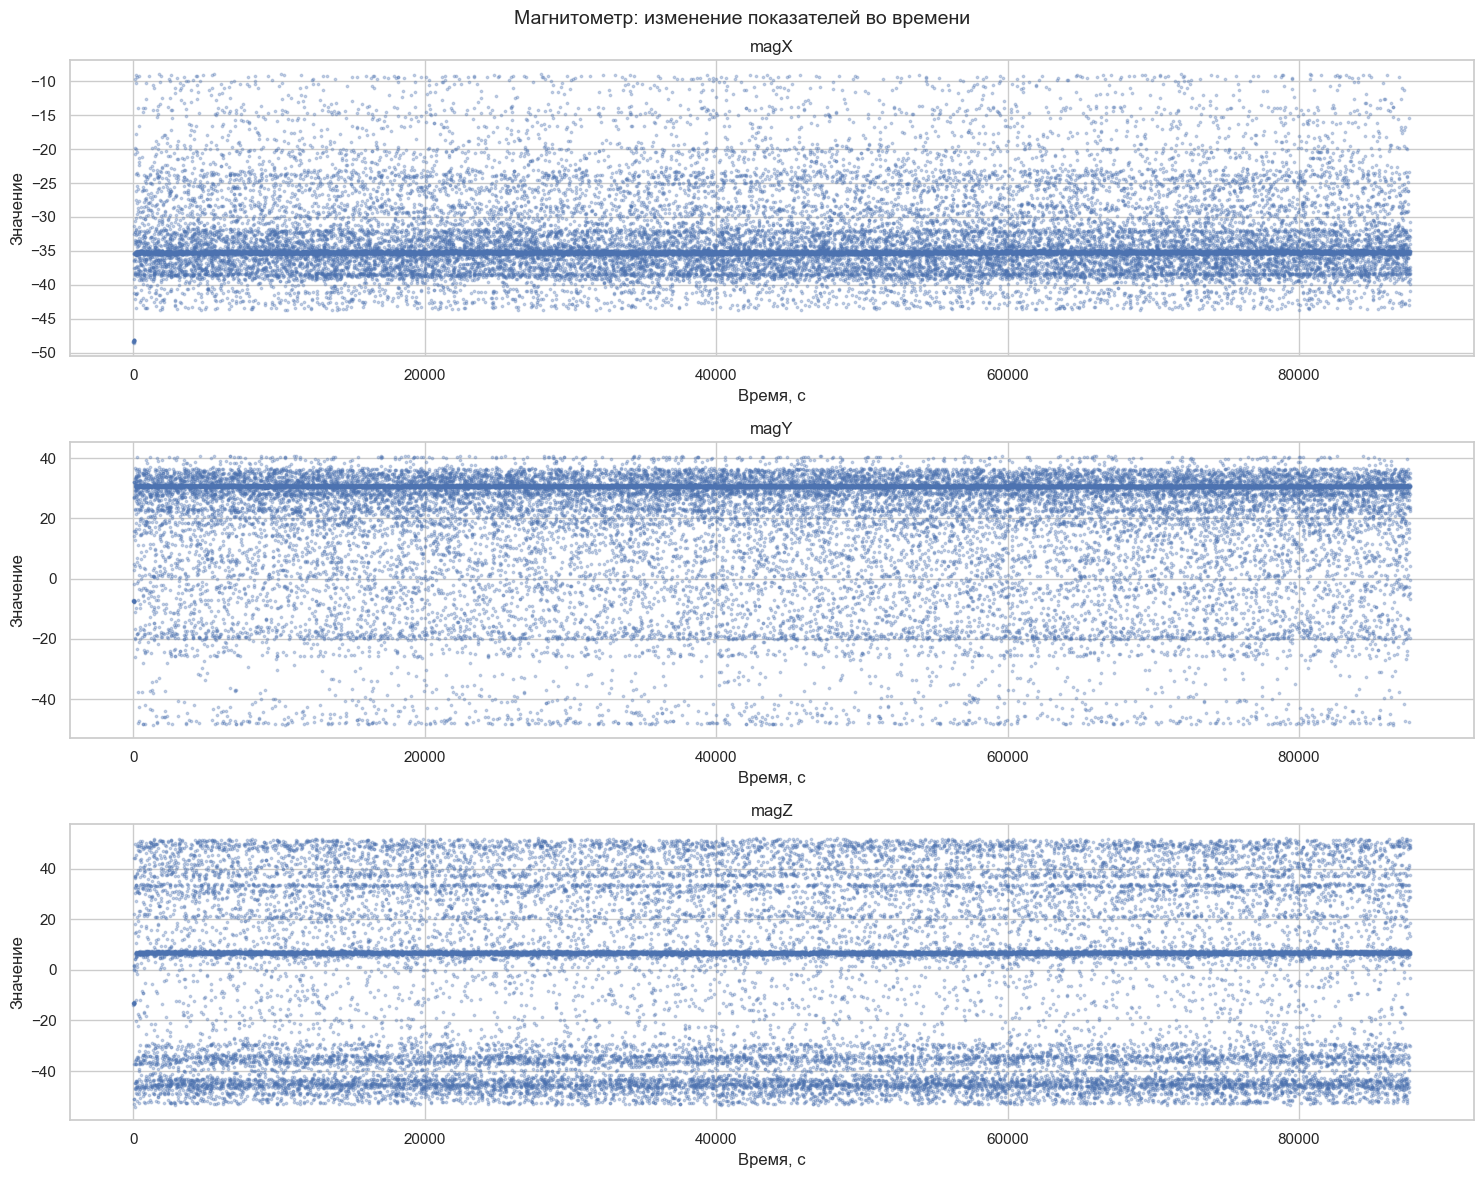

In [28]:
scatter_sample = df.sample(
    n=min(30_000, len(df)),
    random_state=42
).copy()

scatter_sample["time_sec"] = (
    scatter_sample["time"] - df["time"].iloc[0]
) / 1e9

for group_name, columns in groups.items():
    fig, axes = plt.subplots(3, 1, figsize=(15, 12))

    for ax, col in zip(axes, columns):
        ax.scatter(
            scatter_sample["time_sec"],
            scatter_sample[col],
            s=3,
            alpha=0.3
        )

        ax.set_title(col)
        ax.set_xlabel("Время, с")
        ax.set_ylabel("Значение")

    fig.suptitle(
        f"{group_name}: изменение показателей во времени",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()

### 3.5 Одномерные точечные диаграммы

Одномерная точечная диаграмма (strip plot, dot plot) изображает каждое наблюдение точкой на одной числовой оси. Чтобы совпадающие значения не сливались, точкам добавляется небольшое случайное смещение по вертикали (jitter), не несущее информации. В отличие от гистограммы и KDE такая диаграмма не агрегирует данные и показывает каждое наблюдение, в том числе скопления на сетке квантования и отдельные удалённые точки.

Для читаемости используется случайная подвыборка из 2 000 наблюдений. Точки разделены по режиму работы манипулятора (п. 3.2), что позволяет сравнить распределения показателей в состоянии покоя и при движении.

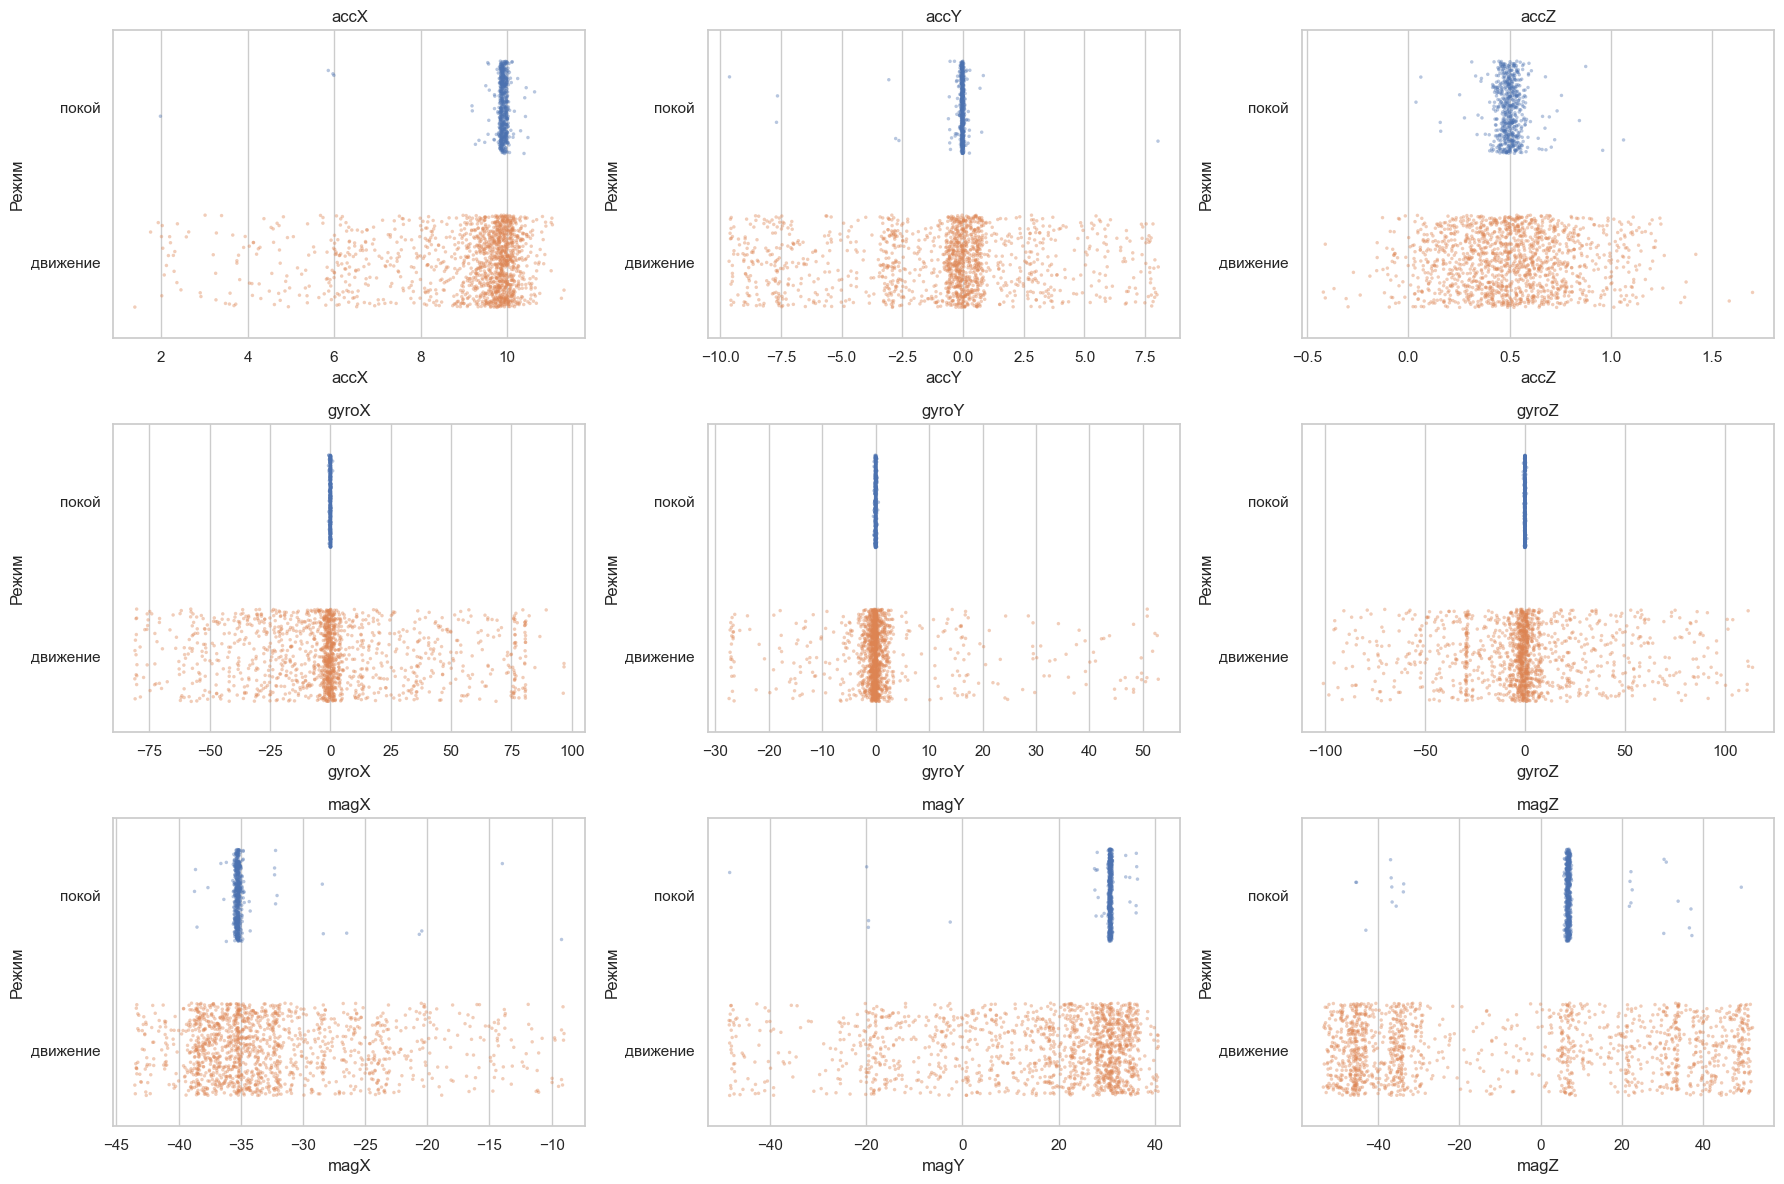

In [29]:
STRIP_SAMPLE_SIZE = 2_000

strip_sample = state_sample.sample(
    n=STRIP_SAMPLE_SIZE,
    random_state=RANDOM_STATE
)

fig, axes = plt.subplots(3, 3, figsize=(18, 12))

for ax, col in zip(axes.flat, sensor_columns):
    sns.stripplot(
        data=strip_sample,
        x=col,
        y="state",
        hue="state",
        order=["покой", "движение"],
        jitter=0.3,
        size=2.5,
        alpha=0.4,
        legend=False,
        ax=ax
    )

    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Режим")

plt.tight_layout()
plt.show()

### 3.6 Boxplot

Построим boxplot для сенсорных показателей.

Boxplot позволяет одновременно оценить медиану, межквартильный размах и диапазон основной массы наблюдений.

Межквартильный размах определяется как

$$
IQR=Q_3-Q_1,
$$

где \(Q_1\) и \(Q_3\) — первый и третий квартили.

Стандартные границы потенциальных выбросов определяются как

$$
Q_1-1.5IQR
$$

и

$$
Q_3+1.5IQR.
$$

Наблюдения за пределами этих границ отображаются отдельно.

Важно, что точки за пределами усов не считаются автоматически ошибочными данными. Они являются потенциальными выбросами и требуют дополнительной проверки с использованием статистических и алгоритмических методов.


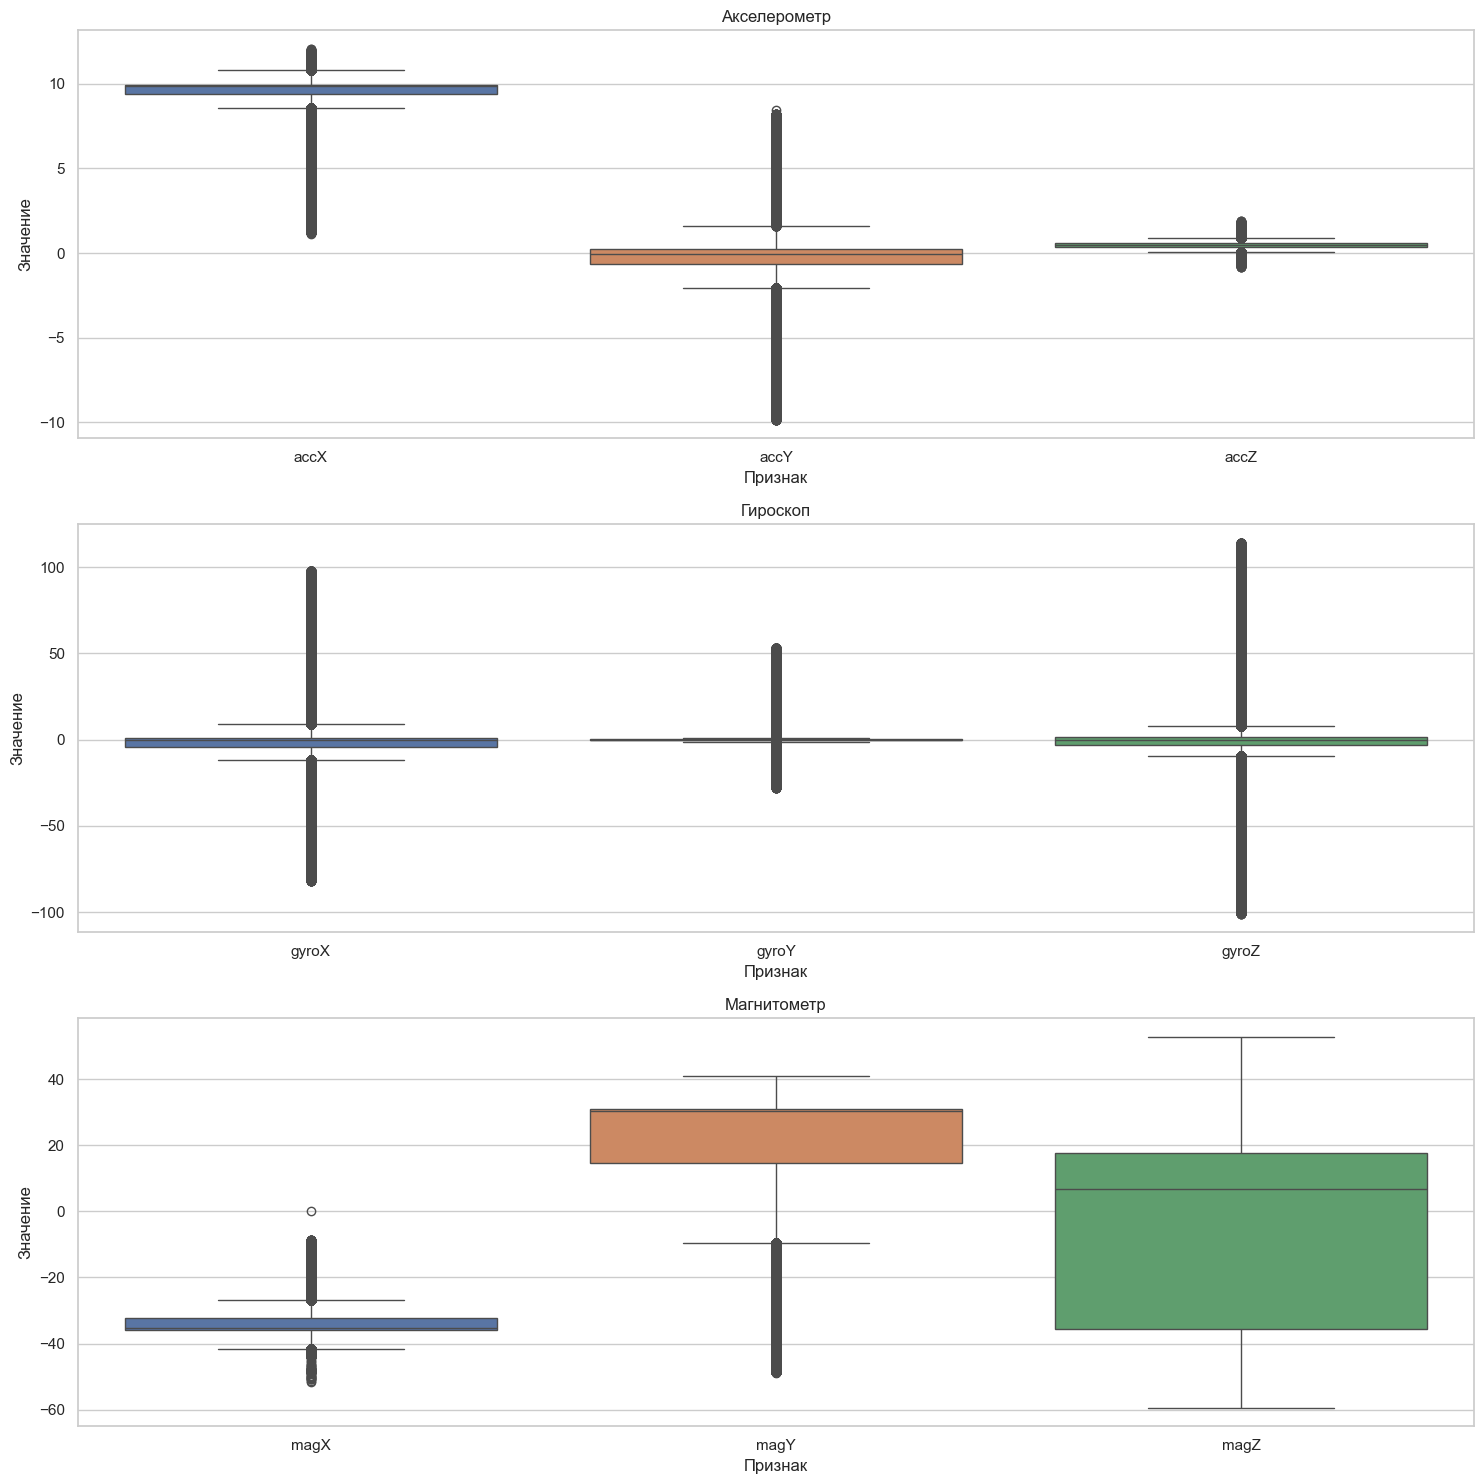

In [30]:
fig, axes = plt.subplots(3, 1, figsize=(15, 15))

for ax, (group_name, columns) in zip(axes, groups.items()):
    sns.boxplot(
        data=df[columns],
        ax=ax
    )

    ax.set_title(group_name)
    ax.set_ylabel("Значение")
    ax.set_xlabel("Признак")

plt.tight_layout()
plt.show()

### Вывод

Условные распределения показывают, что распределение одного сенсорного показателя изменяется при переходе между квартилями другого. Наиболее заметные различия наблюдаются для пары `magX`–`magY`, тогда как для `accX`–`accY` и особенно `gyroX`–`gyroY` распределения также имеют выраженную структуру и различаются по ширине и форме.

График условной плотности режима работы (cdplot) показывает, что неподвижное состояние манипулятора (≈ 30% наблюдений) сосредоточено в узкой области значений: `accX` ≈ 9.9 м/с², `accY` ≈ 0 м/с², `magY` ≈ 30 мкТл — это «исходная» поза манипулятора. Там вероятность покоя достигает ≈ 0.6, а за пределами этой области почти все наблюдения относятся к движению.

Двумерные scatter plot показывают нелинейные зависимости между всеми рассмотренными парами признаков. Для `accX`–`accY`, `gyroX`–`gyroY` и `magX`–`magY` наблюдаются криволинейные траектории и отдельные области концентрации точек, поэтому линейная модель взаимосвязи здесь была бы недостаточна.

Одномерные точечные диаграммы наглядно показывают разделение режимов: в покое значения всех показателей компактны (гироскоп — только шум квантования около нуля), а в режиме движения разброс в десятки раз больше. На них также видна дискретность значений гироскопа и отдельные скопления значений `magZ`.

Boxplot выявляют большое количество наблюдений за пределами границ $1.5IQR$, особенно у гироскопа. Точечные диаграммы объясняют причину: центральная часть распределения узкая (покой и медленные движения), и за границы $1.5IQR$ выходят обычные наблюдения быстрых движений. Поэтому такие наблюдения следует считать лишь потенциальными выбросами — они могут соответствовать реальным движениям манипулятора.

Таким образом, визуальный анализ выявил нелинейные взаимосвязи между сенсорными показателями, два режима работы манипулятора и большое число потенциальных выбросов, которые требуют проверки статистическими методами.

---
## 4. Выявление выбросов

### 4.1 Теоретические основы

Выбросом будем называть наблюдение, которое существенно отличается от основной массы данных. При этом статистически необычное наблюдение не обязательно является ошибочным: в данных роботизированного манипулятора оно может соответствовать как ошибке измерения, так и реальному резкому движению.

В предыдущем разделе с помощью boxplot были обнаружены многочисленные потенциальные выбросы. На данном этапе проверим их с использованием формальных статистических критериев и алгоритмов обнаружения аномалий.

В работе используются следующие методы:

- метод межквартильного размаха (IQR);
- Z-оценки;
- критерий Граббса;
- Q-тест Диксона;
- Isolation Forest;
- Local Outlier Factor (LOF).

Первые четыре метода в основном рассматривают каждый признак отдельно. Isolation Forest и LOF позволяют анализировать наблюдения в многомерном пространстве признаков.

Различия между методами принципиальны. IQR использует положение наблюдения относительно квартилей, Z-оценка — расстояние от среднего в единицах стандартного отклонения, критерий Граббса и Q-тест Диксона являются статистическими критериями для проверки экстремальных наблюдений, а Isolation Forest и LOF используют структуру многомерного пространства данных.

Результаты различных методов не обязаны совпадать. Поэтому задача данного раздела состоит не в автоматическом удалении всех обнаруженных наблюдений, а в сравнении методов и выявлении наблюдений, требующих дополнительного анализа.

### 4.2. Метод межквартильного размаха (IQR)

Метод межквартильного размаха основан на первом и третьем квартилях распределения:

$$
Q_1=P_{25}, \qquad Q_3=P_{75}.
$$

Межквартильный размах определяется как

$$
IQR=Q_3-Q_1.
$$

Стандартные границы потенциальных выбросов задаются выражениями

$$
L=Q_1-1.5IQR,
$$

$$
U=Q_3+1.5IQR.
$$

Наблюдение считается потенциальным выбросом, если

$$
x_i<L
$$

или

$$
x_i>U.
$$

Метод устойчив к выбросам, поскольку основан на квартилях и не использует среднее и стандартное отклонение. Однако для сильно асимметричных распределений он может классифицировать большое количество наблюдений как потенциальные выбросы.

Для каждого сенсорного показателя определим количество и долю наблюдений, выходящих за границы $1.5IQR$.

In [31]:
def iqr_outliers(series):
    x = series.dropna()

    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    mask = (x < lower) | (x > upper)

    return {
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_bound": lower,
        "upper_bound": upper,
        "outlier_count": mask.sum(),
        "outlier_share": mask.mean()
    }


iqr_results = pd.DataFrame({
    col: iqr_outliers(df[col])
    for col in sensor_columns
}).T

iqr_results

,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count,outlier_share
accX,9.394847,9.957484,0.562637,8.550891,10.801440,135368.0,0.154717
accY,-0.672771,0.246603,0.919373,-2.051831,1.625663,274797.0,0.314076
accZ,0.378284,0.586579,0.208296,0.065841,0.899023,80821.0,0.092374
gyroX,-4.000000,1.187500,5.187500,-11.781250,8.968750,318670.0,0.364221
gyroY,-0.375000,0.187500,0.562500,-1.218750,1.031250,232367.0,0.265581
gyroZ,-3.062500,1.312500,4.375000,-9.625000,7.875000,280077.0,0.320111
magX,-35.959999,-32.279999,3.680000,-41.480000,-26.759998,134909.0,0.154193
magY,14.680000,30.879999,16.199999,-9.619998,55.179997,103742.0,0.118571
magZ,-35.615383,17.692308,53.307692,-115.576921,97.653846,0.0,0.000000


IQR относит к потенциальным выбросам 27–36% наблюдений гироскопа и 31% наблюдений `accY`. Столь большая доля означает, что метод здесь **неприменим в буквальном смысле**: распределения являются смесями режимов (покой / движение, см. п. 3.2 и 3.5), квартильные границы строятся по узкому центральному пику, и в «выбросы» попадают почти все наблюдения в режиме активного движения. Для `magZ`, напротив, IQR ничего не находит: распределение широкое и платовидное, и границы $Q_1-1.5IQR$, $Q_3+1.5IQR$ лежат за пределами размаха данных.

### 4.3. Z-оценки

Z-оценка показывает, на сколько стандартных отклонений наблюдение удалено от среднего значения:

$$
z_i=\frac{x_i-\bar{x}}{s},
$$

где $\bar{x}$ — среднее значение признака, а $s$ — его стандартное отклонение.

В качестве границы потенциального выброса будем использовать

$$
|z_i|>3.
$$

То есть наблюдение считается потенциальным выбросом, если оно находится дальше трёх стандартных отклонений от среднего.

Метод Z-оценок наиболее естественно интерпретируется для распределений, близких к нормальным. Для существенно асимметричных или мультимодальных распределений среднее и стандартное отклонение могут плохо характеризовать основную массу наблюдений. Поэтому результаты Z-оценок будем рассматривать совместно с формой распределений и результатами других методов.

In [32]:
from scipy.stats import zscore

Z_THRESHOLD = 3

z_results = []

for col in sensor_columns:
    x = df[col].dropna()

    z = zscore(x)

    mask = np.abs(z) > Z_THRESHOLD

    z_results.append({
        "feature": col,
        "mean": x.mean(),
        "std": x.std(),
        "outlier_count": mask.sum(),
        "outlier_share": mask.mean()
    })

z_results = pd.DataFrame(z_results).set_index("feature")

z_results

,mean,std,outlier_count,outlier_share
feature,,,,
accX,9.269243,1.516315,28900,0.033031
accY,-0.679584,3.081915,0,0.000000
accZ,0.495106,0.234830,8742,0.009992
gyroX,0.348747,28.019503,3851,0.004401
gyroY,0.663905,8.082524,33707,0.038525
gyroZ,0.018216,26.374499,27921,0.031912
magX,-33.343776,5.845444,22852,0.026118
magY,19.589580,19.280610,20149,0.023029
magZ,-2.480548,31.454652,0,0.000000


Z-оценки для `accY` и `magZ` не нашли ни одного выброса. Для широких многомодальных распределений стандартное отклонение велико, и порог $3s$ выходит за пределы данных: для `accY` максимальное $|z|\approx2.97$. Кроме того, сами экстремальные наблюдения завышают $s$ и тем самым «маскируют» себя (эффект маскировки). Поэтому Z-оценки корректно интерпретировать только для распределений, близких к нормальному.

### 4.4. Предварительная проверка применимости критерия Граббса

Критерий Граббса предназначен для выявления одного экстремального наблюдения в выборке и основан на предположении о нормальности распределения.

Перед его применением необходимо оценить, насколько это предположение согласуется с исследуемыми данными.

В качестве предварительной проверки рассмотрим:

1. коэффициент асимметрии;
2. excess kurtosis;
3. результат теста Шапиро–Уилка на случайной подвыборке.

Полный набор данных содержит 874 937 наблюдений. При таком объёме выборки формальные тесты нормальности становятся чрезмерно чувствительными даже к небольшим отклонениям от нормального распределения. Поэтому для предварительной оценки используем случайную подвыборку фиксированного размера.

Тест Шапиро–Уилка проверяет гипотезы

$$
H_0: X \sim N(\mu,\sigma^2),
$$

$$
H_1: X \text{ не имеет нормального распределения}.
$$

При уровне значимости

$$
\alpha=0.05
$$

значение $p<0.05$ является основанием отвергнуть гипотезу о нормальности.

При этом отсутствие оснований для отклонения $H_0$ не доказывает нормальность распределения. Поэтому результаты теста рассматриваются вместе с асимметрией, эксцессом и графическим анализом.

Полученные результаты будут использованы для выбора признаков, для которых применение критерия Граббса является наиболее обоснованным.

In [33]:
from scipy.stats import shapiro, skew, kurtosis

NORMALITY_SAMPLE_SIZE = 5000
NORMALITY_RANDOM_STATE = 42
ALPHA = 0.05

normality_results = []

for col in sensor_columns:
    x = df[col].dropna()

    sample = x.sample(
        n=min(NORMALITY_SAMPLE_SIZE, len(x)),
        random_state=NORMALITY_RANDOM_STATE
    )

    shapiro_stat, shapiro_p = shapiro(sample)

    normality_results.append({
        "feature": col,
        "skewness": skew(x, bias=False),
        "excess_kurtosis": kurtosis(
            x,
            fisher=True,
            bias=False
        ),
        "Shapiro_W": shapiro_stat,
        "Shapiro_p": shapiro_p,
        "normality_at_0.05": shapiro_p >= ALPHA
    })

normality_results = pd.DataFrame(
    normality_results
).set_index("feature")

normality_results

,skewness,excess_kurtosis,Shapiro_W,Shapiro_p,normality_at_0.05
feature,,,,,
accX,-2.739166,7.740546,0.618090,1.970381e-74,False
accY,-0.762666,1.868484,0.839884,1.843544e-57,False
accZ,0.284244,1.645130,0.966342,1.189872e-32,False
gyroX,0.491446,2.317646,0.835261,5.567320e-58,False
gyroY,2.871021,17.121582,0.490441,1.470187e-80,False
gyroZ,0.465529,4.292307,0.801000,1.707565e-61,False
magX,1.755210,3.541038,0.811868,1.940002e-60,False
magY,-1.671453,2.005146,0.737164,7.335134e-67,False
magZ,-0.093653,-1.193974,0.905926,3.455905e-48,False


Для более формальной графической проверки нормальности построим Q-Q графики с поточечной 95%-ной нормальной огибающей.

Выборка предварительно **стандартизуется** по собственным среднему и стандартному отклонению: $z_i=(x_i-\bar x)/s$. Только после этого её квантили можно сравнивать с квантилями $N(0,1)$ и с прямой $y=x$.

Огибающая строится методом Монте-Карло: генерируется 1000 выборок из $N(0,1)$ того же объёма, каждая **стандартизуется так же**, как исследуемая выборка (это учитывает, что параметры оценены по данным), и упорядочивается. Для каждого теоретического квантиля определяются 2.5% и 97.5% квантили смоделированных порядковых статистик — это 95%-ный коридор ожидаемых значений при нормальности.

Точки, выходящие за пределы огибающей, выделяются отдельно. Систематический выход точек за пределы коридора свидетельствует о существенном отклонении распределения от нормального.

In [34]:
from scipy.stats import norm

ENVELOPE_SIMULATIONS = 1000
ENVELOPE_ALPHA = 0.05


def standardize(x):
    # Стандартизация по собственным среднему и стандартному отклонению
    return (x - x.mean()) / x.std(ddof=1)


def qq_normal_envelope(
    x,
    n_sim=ENVELOPE_SIMULATIONS,
    alpha=ENVELOPE_ALPHA,
    random_state=42
):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]

    n = len(x)

    # Теоретические нормальные квантили
    probabilities = (np.arange(1, n + 1) - 0.5) / n
    theoretical = norm.ppf(probabilities)

    # Наблюдаемые квантили стандартизованной выборки
    observed = np.sort(standardize(x))

    # Моделирование: выборки из N(0,1), стандартизованные так же, как данные
    rng = np.random.default_rng(random_state)
    simulated = rng.standard_normal(size=(n_sim, n))
    simulated = (simulated - simulated.mean(axis=1, keepdims=True)) / simulated.std(axis=1, ddof=1, keepdims=True)
    simulated.sort(axis=1)

    lower = np.quantile(simulated, alpha / 2, axis=0)
    upper = np.quantile(simulated, 1 - alpha / 2, axis=0)

    return theoretical, observed, lower, upper

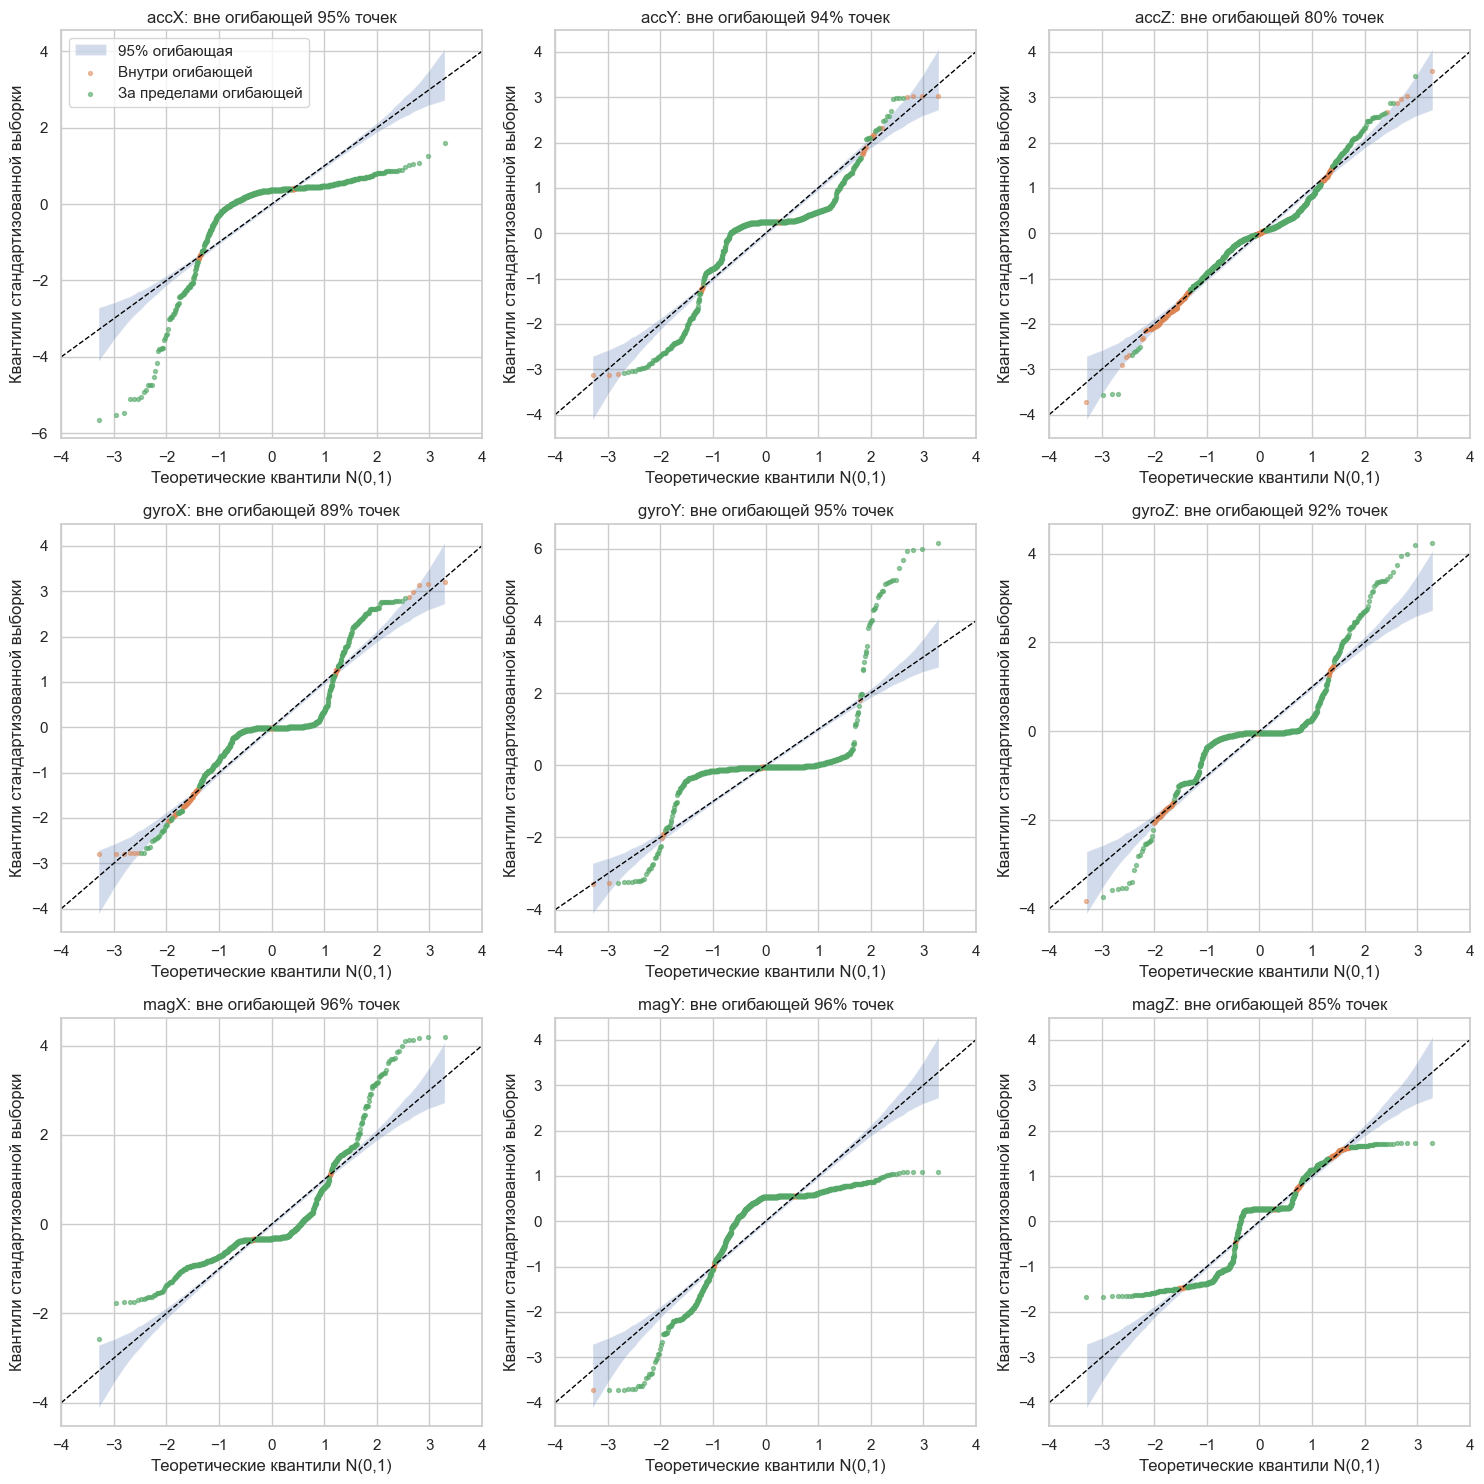

,Доля точек вне огибающей
accX,0.951
accY,0.935
accZ,0.795
gyroX,0.892
gyroY,0.954
gyroZ,0.915
magX,0.956
magY,0.957
magZ,0.849


In [35]:
ENVELOPE_SAMPLE_SIZE = 1000

fig, axes = plt.subplots(3, 3, figsize=(15, 15))

envelope_summary = {}

for ax, col in zip(axes.flat, sensor_columns):

    x = df[col].dropna().sample(
        n=ENVELOPE_SAMPLE_SIZE,
        random_state=NORMALITY_RANDOM_STATE
    ).to_numpy()

    theoretical, observed, lower, upper = qq_normal_envelope(
        x,
        random_state=NORMALITY_RANDOM_STATE
    )

    outside = (observed < lower) | (observed > upper)
    envelope_summary[col] = outside.mean()

    # Нормальная огибающая
    ax.fill_between(theoretical, lower, upper, alpha=0.25, label="95% огибающая")

    # Q-Q точки внутри и вне огибающей
    ax.scatter(theoretical[~outside], observed[~outside], s=8, alpha=0.5, label="Внутри огибающей")
    ax.scatter(theoretical[outside], observed[outside], s=8, alpha=0.6, label="За пределами огибающей")

    # Прямая y = x: совпадение со стандартным нормальным распределением
    lim = [-4, 4]
    ax.plot(lim, lim, linestyle="--", color="black", linewidth=1)

    ax.set_xlim(-4, 4)
    ax.set_title(f"{col}: вне огибающей {outside.mean():.0%} точек")
    ax.set_xlabel("Теоретические квантили N(0,1)")
    ax.set_ylabel("Квантили стандартизованной выборки")

axes.flat[0].legend(loc="upper left")
plt.tight_layout()
plt.show()

pd.Series(envelope_summary, name="Доля точек вне огибающей").to_frame().round(3)

Для всех девяти признаков большая часть точек (от 80% у `accZ` до 96% у `magY`) лежит за пределами 95%-ной огибающей. Для `accZ` отклонение умеренное — точки идут близко к прямой, но с систематическим S-образным изгибом (более острый пик и тяжёлые хвосты); для гироскопа и магнитометра видны горизонтальные «полки» (скопления одинаковых значений в состоянии покоя) и резкие скачки между модами. Таким образом, метод огибающих подтверждает вывод о ненормальности распределений.

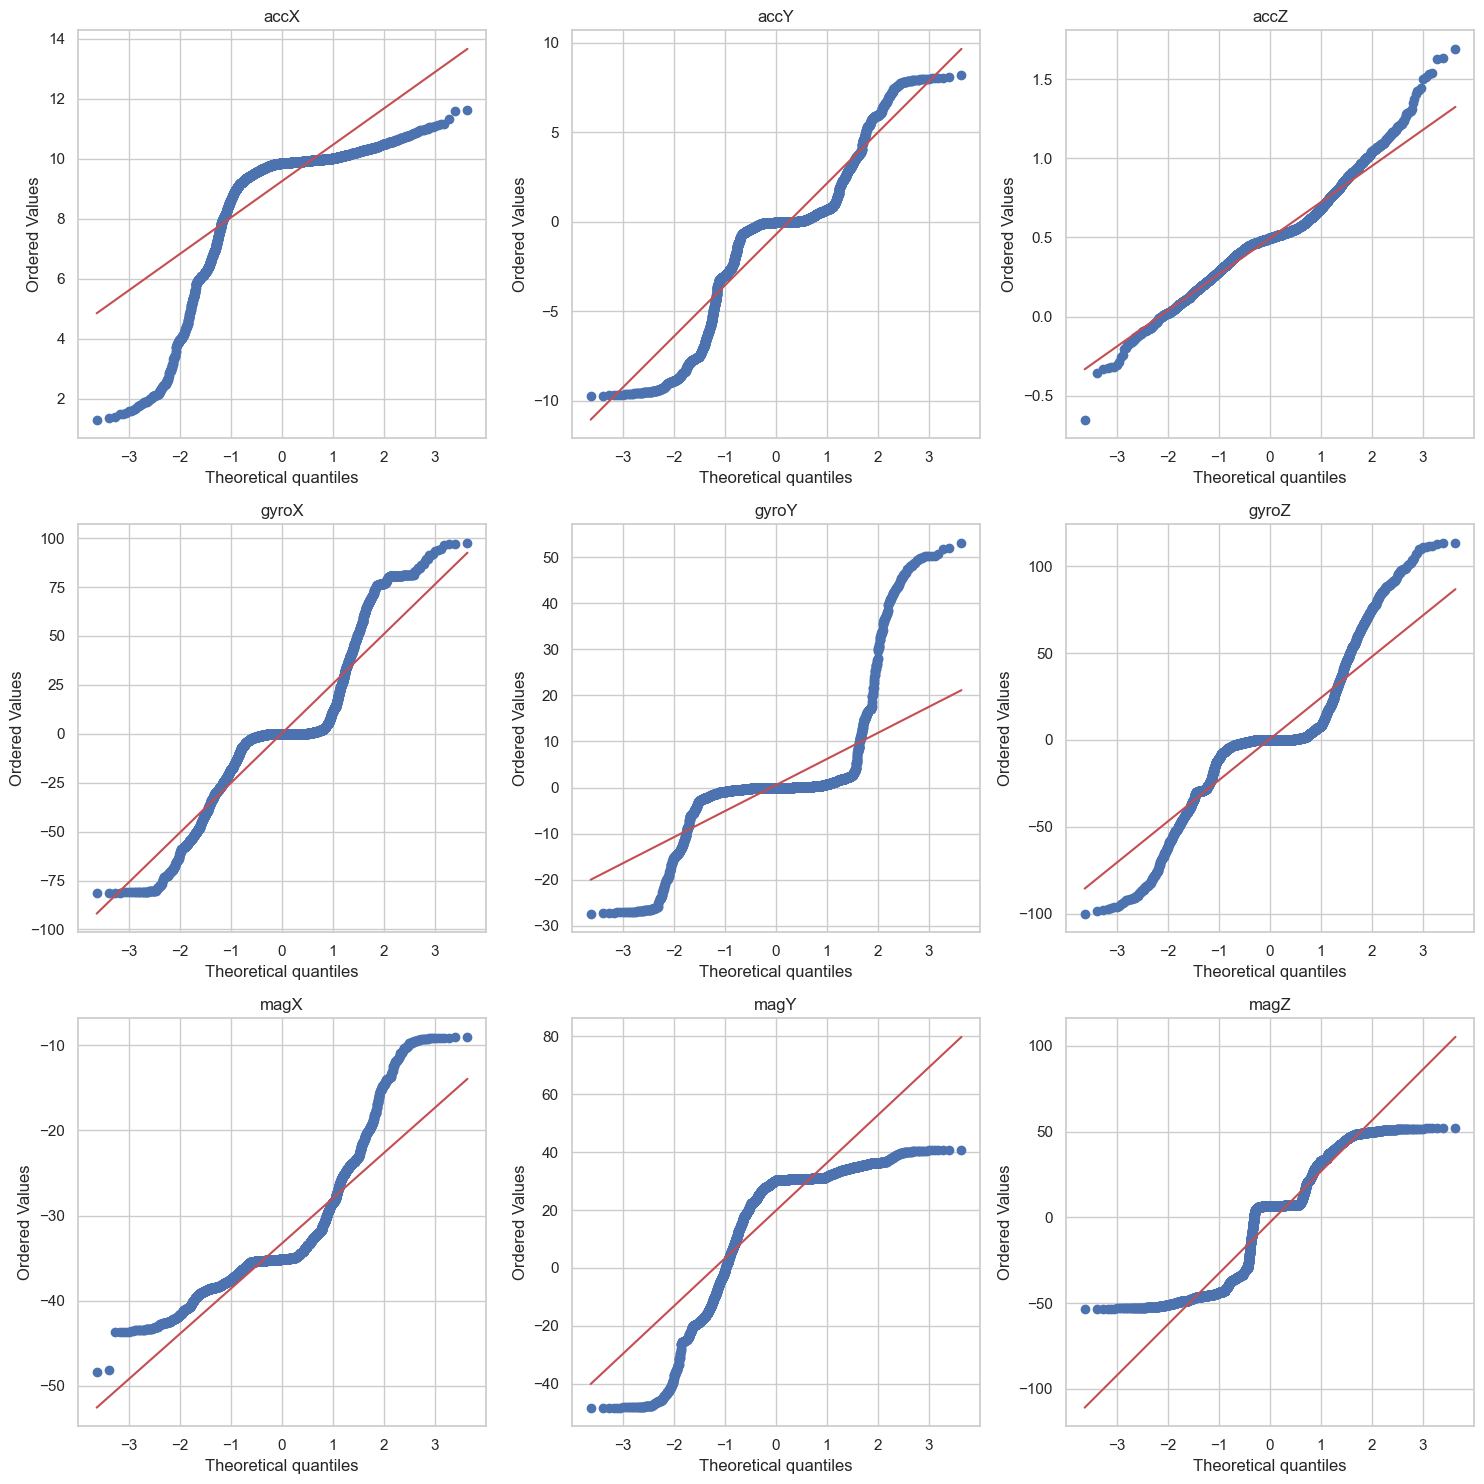

In [36]:
import scipy.stats as stats

fig, axes = plt.subplots(
    3, 3,
    figsize=(15, 15)
)

for ax, col in zip(axes.flat, sensor_columns):
    x = df[col].dropna()

    sample = x.sample(
        n=min(NORMALITY_SAMPLE_SIZE, len(x)),
        random_state=NORMALITY_RANDOM_STATE
    )

    stats.probplot(
        sample,
        dist="norm",
        plot=ax
    )

    ax.set_title(col)

plt.tight_layout()
plt.show()

### 4.5. Критерий Граббса

Критерий Граббса используется для проверки наличия одного экстремального наблюдения в выборке. Он основан на предположении о нормальности распределения.

Статистика критерия определяется как

$$
G=
\frac{\max_i |x_i-\bar{x}|}{s},
$$

где $\bar{x}$ — выборочное среднее, а $s$ — выборочное стандартное отклонение.

Проверяются гипотезы

$$
H_0:\text{выборка не содержит выброса},
$$

$$
H_1:\text{выборка содержит выброс}.
$$

Для уровня значимости $\alpha$ критическое значение определяется по формуле

$$
G_{\text{crit}}
=
\frac{n-1}{\sqrt{n}}
\sqrt{
\frac{t^2}
{n-2+t^2}
},
$$

где

$$
t=t_{1-\alpha/(2n),\,n-2}
$$

— квантиль распределения Стьюдента.

Если

$$
G>G_{\text{crit}},
$$

нулевая гипотеза отвергается, и наиболее экстремальное наблюдение рассматривается как статистически значимый выброс.

Предварительный анализ показал, что ни один из сенсорных показателей формально не удовлетворяет предположению о нормальности при уровне значимости $\alpha=0.05$. Наиболее близким к нормальному распределению является `accZ`: его коэффициент асимметрии равен 0.284, а Q-Q plot демонстрирует наименьшие отклонения от теоретической прямой. Однако критерий Шапиро–Уилка также отвергает нормальность для этого признака.

Поэтому критерий Граббса применим к исходным данным только с оговоркой о нарушении его предпосылки. В работе он будет использован для `accZ` как дополнительный ориентир, а полученный результат будет сопоставлен с результатами непараметрических и многомерных методов.

In [37]:
from scipy.stats import t


def grubbs_test(series, alpha=0.05):
    x = series.dropna().to_numpy()
    n = len(x)

    if n < 3 or not np.isfinite(x).all():
        raise ValueError("Нужно минимум 3 конечных наблюдения")
    if np.ptp(x) == 0:
        raise ValueError("Критерий не определён для постоянной выборки")

    mean = np.mean(x)
    std = np.std(x, ddof=1)

    # Отклонения наблюдений от среднего
    deviations = np.abs(x - mean)

    # Самое экстремальное наблюдение
    max_idx = np.argmax(deviations)

    G = deviations[max_idx] / std

    # Критическое значение
    t_critical = t.ppf(
        1 - alpha / (2 * n),
        n - 2
    )

    G_critical = (
        (n - 1) / np.sqrt(n)
        * np.sqrt(
            t_critical**2 /
            (n - 2 + t_critical**2)
        )
    )

    # Приближённое p-value через обратную связь
    # между G и t-статистикой
    t_stat = np.sqrt(
        (G**2 * n * (n - 2)) /
        ((n - 1)**2 - n * G**2)
    )

    # t.sf(x) = 1 - t.cdf(x), но вычисляется точнее для малых вероятностей
    p_value = 2 * n * t.sf(t_stat, n - 2)

    p_value = min(p_value, 1.0)

    return {
        "n": n,
        "G": G,
        "G_critical": G_critical,
        "p_value": p_value,
        "outlier_index": series.dropna().index[max_idx],
        "outlier_value": x[max_idx],
        "outlier_detected": G > G_critical
    }

In [38]:
grubbs_accZ = grubbs_test(
    df["accZ"],
    alpha=0.05
)

grubbs_accZ

{'n': 874937,
 'G': np.float64(6.017441648908994),
 'G_critical': np.float64(5.427461787669298),
 'p_value': np.float64(0.0015497664572237987),
 'outlier_index': np.int64(201238),
 'outlier_value': np.float64(1.908178687095642),
 'outlier_detected': np.True_}

Получено

$$
G=6.0174,
$$

при критическом значении

$$
G_{\text{crit}}=5.4275.
$$

Поскольку

$$
G>G_{\text{crit}},
$$

нулевая гипотеза об отсутствии выброса отвергается. Это также подтверждается значением

$$
p=0.00155<0.05.
$$

Таким образом, критерий Граббса выделяет наблюдение `accZ = 1.90818` как статистически значимо экстремальное.

При этом необходимо учитывать, что предварительная проверка отвергла гипотезу нормальности для `accZ`. Поэтому результат критерия Граббса следует интерпретировать с осторожностью: он указывает на экстремальность наблюдения в рамках данного критерия, но не является самостоятельным доказательством ошибочности измерения.

Посмотрим, в каком режиме работы манипулятора получено это наблюдение.

In [39]:
gyro_norm = np.sqrt((df[groups["Гироскоп"]] ** 2).sum(axis=1))

center = grubbs_accZ["outlier_index"]

display(pd.DataFrame({
    "accZ": df.loc[center - 5: center + 5, "accZ"],
    "|ω|, °/с": gyro_norm.loc[center - 5: center + 5]
}).round(3).T)

,201233,201234,201235,201236,201237,201238,201239,201240,201241,201242,201243
accZ,0.445,0.735,0.323,0.950,1.132,1.908,0.860,1.070,0.639,0.955,1.046
"|ω|, °/с",80.754,81.192,80.036,72.081,63.835,55.609,48.001,39.599,31.381,23.173,15.228


Наблюдение получено при замедлении быстрого поворота манипулятора: за 0.5 с до него модуль угловой скорости ≈ 81 °/с, в момент измерения ≈ 56 °/с. Соседние значения `accZ` также повышены (0.86–1.13 м/с² при медиане 0.50 м/с²). Это согласуется с реальным динамическим ускорением; без эталона нельзя исключить ошибку измерения: глобальный критерий Граббса отмечает его только потому, что распределение `accZ` по всей записи — смесь режимов и не является нормальным.

### 4.5.1 Критерий Граббса на стационарном участке

Предпосылка критерия Граббса (нормальность) лучше выполняется для **шума датчика в покое**. Найдём самый длинный непрерывный участок, на котором манипулятор неподвижен ($|\omega|\le0.5$ °/с), проверим нормальность на нём и применим критерий там.

In [40]:
from scipy.stats import shapiro

REST_THRESHOLD = 0.5  # °/с

is_rest = (gyro_norm <= REST_THRESHOLD).to_numpy()

# Границы непрерывных участков покоя
edges = np.diff(np.r_[0, is_rest.astype(int), 0])
rest_starts = np.where(edges == 1)[0]
rest_ends = np.where(edges == -1)[0]

longest = np.argmax(rest_ends - rest_starts)
rest_segment = df.iloc[rest_starts[longest]:rest_ends[longest]]

print(f"Самый длинный участок покоя: индексы {rest_starts[longest]}–{rest_ends[longest] - 1}, "
      f"{len(rest_segment)} наблюдений ({(rest_segment['time'].iloc[-1] - rest_segment['time'].iloc[0]) / 1e9:.1f} с)")

rest_normality = pd.DataFrame({
    col: {
        "Shapiro_W": shapiro(rest_segment[col]).statistic,
        "Shapiro_p": shapiro(rest_segment[col]).pvalue
    }
    for col in acc_cols
}).T

rest_normality["normality_at_0.05"] = rest_normality["Shapiro_p"] >= ALPHA
rest_normality

Самый длинный участок покоя: индексы 0–268, 269 наблюдений (26.8 с)


,Shapiro_W,Shapiro_p,normality_at_0.05
accX,0.656379,5.658025e-23,False
accY,0.813484,2.814030e-17,False
accZ,0.994151,3.865092e-01,True


In [41]:
grubbs_rest = grubbs_test(rest_segment["accZ"], alpha=0.05)
grubbs_rest

{'n': 269,
 'G': np.float64(2.7520140150393466),
 'G_critical': np.float64(3.6925022260731195),
 'p_value': 1.0,
 'outlier_index': np.int64(37),
 'outlier_value': np.float64(0.385466456413269),
 'outlier_detected': np.False_}

На участке покоя (начало записи, ≈ 27 с) критерий Шапиро–Уилка не отвергает нормальность `accZ`, т.е. здесь предпосылка критерия Граббса согласуется с данными, но это не подтверждает независимость наблюдений и не гарантирует корректность p-value. Для `accX` и `accY` нормальность отвергается и на этом участке.

### 4.5.2 Обобщённый критерий ESD (Рознера)

Критерий Граббса проверяет только **одно** экстремальное наблюдение. Если выбросов несколько, они могут маскировать друг друга. Обобщённый критерий ESD (Generalized Extreme Studentized Deviate, Rosner, 1983) последовательно удаляет наиболее удалённое наблюдение и для каждого шага $i=1,\dots,r$ сравнивает статистику

$$
R_i=\frac{\max_j|x_j-\bar x^{(i)}|}{s^{(i)}}
$$

с критическим значением

$$
\lambda_i=\frac{(n-i)\,t_{p,\,n-i-1}}{\sqrt{(n-i-1+t_{p,\,n-i-1}^2)(n-i+1)}},\qquad p=1-\frac{\alpha}{2(n-i+1)} .
$$

Число выбросов — наибольшее $i$, для которого $R_i>\lambda_i$.

In [42]:
def generalized_esd(series, max_outliers, alpha=0.05):
    x = series.dropna()
    values = x.to_numpy().astype(float)
    index = x.index.to_numpy()
    n = len(values)

    if not 1 <= max_outliers <= n - 3:
        raise ValueError("max_outliers должен быть от 1 до n-3")
    if not np.isfinite(values).all() or np.ptp(values) == 0:
        raise ValueError("Нужна конечная непостоянная выборка")

    steps = []
    for i in range(1, max_outliers + 1):
        mean = values.mean()
        std = values.std(ddof=1)

        if std == 0:
            break

        j = np.argmax(np.abs(values - mean))
        R = abs(values[j] - mean) / std

        # Критическое значение lambda_i; m = n - i + 1 — текущий объём выборки
        m = n - i + 1
        t_crit = t.ppf(1 - alpha / (2 * m), m - 2)
        lam = (m - 1) * t_crit / np.sqrt((m - 2 + t_crit ** 2) * m)

        steps.append({"step": i, "index": index[j], "value": values[j], "R": R, "lambda": lam})

        # Удаляем наиболее удалённое наблюдение и повторяем
        values = np.delete(values, j)
        index = np.delete(index, j)

    steps = pd.DataFrame(steps)

    exceed = np.where(steps["R"] > steps["lambda"])[0]
    n_outliers = exceed.max() + 1 if len(exceed) else 0
    steps["is_outlier"] = steps["step"] <= n_outliers

    return steps, n_outliers


esd_rest, esd_rest_count = generalized_esd(rest_segment["accZ"], max_outliers=10)
print("ESD, участок покоя, accZ: выбросов =", esd_rest_count)
display(esd_rest.round(4))

ESD_MAX_OUTLIERS = 60
esd_full, esd_full_count = generalized_esd(df["accZ"], max_outliers=ESD_MAX_OUTLIERS)
print(f"ESD, вся запись, accZ (r = {ESD_MAX_OUTLIERS}): выбросов =", esd_full_count)
display(esd_full.head(10).round(4))

ESD, участок покоя, accZ: выбросов = 0


,step,index,value,R,lambda,is_outlier
0,1,37,0.3855,2.7520,3.6925,False
1,2,151,0.3855,2.7971,3.6914,False
2,3,102,0.3879,2.7544,3.6904,False
3,4,268,0.5267,2.4906,3.6893,False
4,5,186,0.3974,2.4500,3.6882,False
5,6,236,0.5243,2.4472,3.6871,False
6,7,244,0.5219,2.3864,3.6860,False
7,8,87,0.4022,2.3219,3.6849,False
8,9,80,0.4070,2.1597,3.6838,False
9,10,105,0.4070,2.1835,3.6827,False


ESD, вся запись, accZ (r = 60): выбросов = 32


,step,index,value,R,lambda,is_outlier
0,1,201238,1.9082,6.0174,5.4275,True
1,2,191750,1.8962,5.9666,5.4275,True
2,3,584506,1.8747,5.8750,5.4275,True
3,4,208357,1.8579,5.8037,5.4275,True
4,5,192389,1.8387,5.7222,5.4275,True
5,6,786295,1.8316,5.6918,5.4275,True
6,7,580398,1.8292,5.6817,5.4275,True
7,8,422522,-0.8356,5.6673,5.4275,True
8,9,428434,1.8196,5.6411,5.4275,True
9,10,498459,1.8196,5.6412,5.4275,True


In [43]:
comparison_1d = pd.DataFrame({
    "IQR": iqr_results["outlier_count"],
    "Z-score": z_results["outlier_count"]
})

comparison_1d

,IQR,Z-score
accX,135368.0,28900
accY,274797.0,0
accZ,80821.0,8742
gyroX,318670.0,3851
gyroY,232367.0,33707
gyroZ,280077.0,27921
magX,134909.0,22852
magY,103742.0,20149
magZ,0.0,0


In [44]:
comparison_1d.loc["accZ", "Grubbs"] = (
    1 if grubbs_accZ["outlier_detected"] else 0
)

comparison_1d

,IQR,Z-score,Grubbs
accX,135368.0,28900,NaN
accY,274797.0,0,NaN
accZ,80821.0,8742,1.0
gyroX,318670.0,3851,NaN
gyroY,232367.0,33707,NaN
gyroZ,280077.0,27921,NaN
magX,134909.0,22852,NaN
magY,103742.0,20149,NaN
magZ,0.0,0,NaN


Полученные результаты показывают существенное различие между методами. 
Для большинства признаков критерий IQR выявляет значительно больше потенциальных
выбросов, чем Z-оценки. Это связано с тем, что методы используют разные критерии
экстремальности наблюдений.

Критерий Граббса был применён только к `accZ`, поскольку именно этот признак
оказался наиболее близким к нормальному распределению по результатам
предварительного анализа. Значение `1` в таблице означает, что критерий выявил
статистически значимый экстремальный элемент. Для остальных признаков значение
не рассчитывалось, поэтому отображается `NaN`. Результаты критерия на стационарном участке и
обобщённого критерия ESD приведены в п. 4.5.1–4.5.2.

### 4.6. Q-тест Диксона

Q-тест Диксона предназначен для проверки одного подозрительного крайнего наблюдения в небольшой выборке.

Сначала значения выборки упорядочиваются:

$$
x_{(1)} \leq x_{(2)} \leq \ldots \leq x_{(n)}.
$$

Если подозревается минимальное значение, вычисляется статистика

$$
Q_{\min}=
\frac{x_{(2)}-x_{(1)}}
{x_{(n)}-x_{(1)}}.
$$

Если подозревается максимальное значение:

$$
Q_{\max}=
\frac{x_{(n)}-x_{(n-1)}}
{x_{(n)}-x_{(1)}}.
$$

Таким образом, числитель показывает расстояние от подозрительного наблюдения до ближайшего к нему значения, а знаменатель — полный диапазон выборки.

Если

$$
Q>Q_{\mathrm{crit}},
$$

то крайнее наблюдение считается статистически значимо отличающимся от остальных при выбранном уровне значимости.

В данной работе используем уровень значимости

$$
\alpha=0.05.
$$

Классический Q-тест рассчитан на небольшие выборки. Для выборки из 20 наблюдений критическое значение при $\alpha=0.05$ составляет

$$
Q_{\mathrm{crit}}=0.342.
$$

Это табличное значение для статистики $r_{10}$ (Rorabacher, 1991); ниже оно проверено моделированием. Отметим, что для $n=14\ldots30$ Диксон рекомендовал модифицированную статистику $r_{22}$, менее чувствительную к двум соседним выбросам; здесь используется классическая $r_{10}$ из формулировки задания. Кроме того, **Q-тест, как и критерий Граббса, предполагает нормальность выборки**: критические значения получены для нормального распределения.

Поскольку исходный датасет содержит 874 937 наблюдений, непосредственно применять Q-тест ко всему датасету некорректно. Поэтому проведём исследовательскую проверку на небольших случайных подвыборках размера $n=20$.

Важно, что такой анализ не является проверкой всех 874 937 наблюдений одновременно. Он показывает, насколько часто отдельные случайные подвыборки содержат крайнее наблюдение, которое Q-тест классифицирует как потенциальный выброс.

In [45]:
from collections import Counter

DIXON_N = 20
DIXON_ITERATIONS = 100
DIXON_ALPHA = 0.05
DIXON_Q_CRITICAL = 0.342


def dixon_q_test(values, q_critical=DIXON_Q_CRITICAL):
    """
    Dixon Q-test для одного крайнего наблюдения.
    Проверяются одновременно минимальное и максимальное значения.
    """

    x = np.sort(np.asarray(values, dtype=float))

    n = len(x)

    if n != DIXON_N:
        raise ValueError("Порог 0.342 откалиброван только для n=20")
    if not np.isfinite(x).all():
        raise ValueError("Выборка должна содержать конечные значения")

    if n < 3:
        raise ValueError("Для Q-теста необходимо минимум 3 наблюдения.")

    data_range = x[-1] - x[0]

    if data_range == 0:
        return {
            "Q_min": 0.0,
            "Q_max": 0.0,
            "Q": 0.0,
            "suspected_side": None,
            "outlier_detected": False
        }

    Q_min = (x[1] - x[0]) / data_range
    Q_max = (x[-1] - x[-2]) / data_range

    if Q_min >= Q_max:
        Q = Q_min
        side = "min"
    else:
        Q = Q_max
        side = "max"

    return {
        "Q_min": Q_min,
        "Q_max": Q_max,
        "Q": Q,
        "suspected_side": side,
        "outlier_detected": Q > q_critical
    }

Проверим критическое значение моделированием Монте-Карло: сгенерируем 200 000 выборок объёма 20 из $N(0,1)$ и для каждой вычислим $Q=\max(Q_{\min},Q_{\max})$ так же, как в функции `dixon_q_test`. Квантиль уровня 0.95 полученного распределения и есть критическое значение при $\alpha=0.05$.

In [46]:
mc_rng = np.random.default_rng(0)

Z_sim = np.sort(mc_rng.standard_normal((200_000, DIXON_N)), axis=1)
Z_range = Z_sim[:, -1] - Z_sim[:, 0]
Q_sim = np.maximum(
    (Z_sim[:, 1] - Z_sim[:, 0]) / Z_range,
    (Z_sim[:, -1] - Z_sim[:, -2]) / Z_range
)

for level in [0.90, 0.95, 0.99]:
    print(f"Q_crit (доверительный уровень {level:.2f}) = {np.quantile(Q_sim, level):.3f}")

print(f"\nДоля срабатываний при Q_crit = {DIXON_Q_CRITICAL} для нормальных данных: "
      f"{(Q_sim > DIXON_Q_CRITICAL).mean():.3f}")

Q_crit (доверительный уровень 0.90) = 0.301
Q_crit (доверительный уровень 0.95) = 0.344
Q_crit (доверительный уровень 0.99) = 0.426

Доля срабатываний при Q_crit = 0.342 для нормальных данных: 0.051


In [47]:
dixon_results = []

rng = np.random.default_rng(42)

for col in sensor_columns:

    x = df[col].dropna().to_numpy()

    detected_count = 0
    min_detected = 0
    max_detected = 0

    q_values = []

    for _ in range(DIXON_ITERATIONS):

        sample = rng.choice(
            x,
            size=DIXON_N,
            replace=False
        )

        result = dixon_q_test(sample)

        q_values.append(result["Q"])

        if result["outlier_detected"]:
            detected_count += 1

            if result["suspected_side"] == "min":
                min_detected += 1
            elif result["suspected_side"] == "max":
                max_detected += 1

    dixon_results.append({
        "feature": col,
        "iterations": DIXON_ITERATIONS,
        "sample_size": DIXON_N,
        "detected_count": detected_count,
        "detection_share": detected_count / DIXON_ITERATIONS,
        "min_detected": min_detected,
        "max_detected": max_detected,
        "mean_Q": np.mean(q_values),
        "max_Q": np.max(q_values)
    })

dixon_results = pd.DataFrame(
    dixon_results
).set_index("feature")

dixon_results

,iterations,sample_size,detected_count,detection_share,min_detected,max_detected,mean_Q,max_Q
feature,,,,,,,,
accX,100,20,37,0.37,37,0,0.297462,0.765191
accY,100,20,32,0.32,19,13,0.264295,0.607755
accZ,100,20,16,0.16,3,13,0.224674,0.523364
gyroX,100,20,22,0.22,9,13,0.242997,0.663905
gyroY,100,20,74,0.74,26,48,0.494860,0.947917
gyroZ,100,20,49,0.49,17,32,0.329607,0.696948
magX,100,20,28,0.28,0,28,0.259111,0.639405
magY,100,20,26,0.26,26,0,0.236739,0.669307
magZ,100,20,0,0.00,0,0,0.068926,0.286204


Для нормальных данных Q-тест с $Q_{crit}=0.342$ срабатывает примерно в 5% подвыборок (это и есть уровень значимости). Для всех признаков, кроме `magZ`, доля срабатываний значительно выше: от 16% (`accZ`) до 74% (`gyroY`). Это не означает, что в данных много ошибочных измерений: высокая доля срабатываний — следствие **ненормальности** распределений (тяжёлые хвосты, смесь режимов покоя и движения). Для `gyroY` дополнительно сказывается квантование: большинство из 20 значений равны 0 или ±0.0625 °/с, и одно наблюдение из режима движения даёт огромный отрыв от остальных. Для `magZ` Q-тест не срабатывает ни разу: распределение платовидное, без хвостов.

Для `accX` все срабатывания приходятся на минимум, для `magX` — на максимум, для `magY` — на минимум, что согласуется с направлением асимметрии этих признаков (п. 2.7).

In [48]:
accZ_sample = df["accZ"].sample(
    n=DIXON_N,
    random_state=42
)

accZ_dixon = dixon_q_test(
    accZ_sample.to_numpy()
)

accZ_sample_sorted = np.sort(
    accZ_sample.to_numpy()
)

print("Отсортированная выборка:")
print(accZ_sample_sorted)

print("\nРезультат Q-теста:")
accZ_dixon

Отсортированная выборка:
[-0.12210429  0.10534488  0.1388637   0.15322891  0.29448679  0.34955344
  0.38307226  0.39264908  0.40462008  0.4333505   0.4429273   0.46447513
  0.49799395  0.49799395  0.51714754  0.54587799  0.54827219  0.74459672
  0.85951841  1.06781399]

Результат Q-теста:


{'Q_min': np.float64(0.19114687763418017),
 'Q_max': np.float64(0.17505032680615978),
 'Q': np.float64(0.19114687763418017),
 'suspected_side': 'min',
 'outlier_detected': np.False_}

Случайная подвыборка из разных моментов времени не отвечает на вопрос, является ли конкретное наблюдение выбросом. Для временного ряда естественнее сравнивать наблюдение с его **соседями по времени**. Применим Q-тест к окну из 20 последовательных наблюдений вокруг точки, найденной критерием Граббса.

In [49]:
center = grubbs_accZ["outlier_index"]

accZ_window = df.loc[center - 10: center + 9, "accZ"]

print("Отсортированное окно из 20 соседних наблюдений:")
print(np.round(np.sort(accZ_window.to_numpy()), 3))

dixon_q_test(accZ_window.to_numpy())

Отсортированное окно из 20 соседних наблюдений:
[-0.242  0.103  0.283  0.323  0.366  0.445  0.548  0.639  0.735  0.86
  0.907  0.95   0.955  1.001  1.03   1.046  1.07   1.132  1.216  1.908]


{'Q_min': np.float64(0.16035635223165218),
 'Q_max': np.float64(0.3218262545057791),
 'Q': np.float64(0.3218262545057791),
 'suspected_side': 'max',
 'outlier_detected': np.False_}

В окне из соседних по времени наблюдений $Q<Q_{crit}$, т.е. значение `accZ = 1.908`, выделенное критерием Граббса по всей записи, **не выделяется на фоне соседних измерений**: во время быстрого поворота манипулятора все соседние значения тоже повышены. Это подтверждает вывод п. 4.5 о том, что наблюдение соответствует реальному движению, а не ошибке датчика.

### 4.7. Isolation Forest

**Isolation Forest** — алгоритм обнаружения аномальных наблюдений, основанный на их изоляции от основной массы данных.

Основная идея метода заключается в том, что обычные наблюдения находятся в плотных областях пространства признаков, поэтому для их изоляции требуется большое количество случайных разбиений. Аномальные наблюдения, напротив, часто находятся в разреженных областях или далеко от основной массы данных, поэтому могут быть изолированы за меньшее количество разбиений.

Таким образом:

- чем меньше разбиений требуется для изоляции наблюдения, тем более вероятно, что оно является аномальным;
- алгоритм позволяет учитывать несколько признаков одновременно;
- в отличие от IQR и Z-оценок, Isolation Forest способен обнаруживать аномалии, обусловленные не только экстремальным значением одного признака, но и необычным сочетанием нескольких признаков.

В данной работе Isolation Forest применяется одновременно к девяти сенсорным характеристикам:

`accX`, `accY`, `accZ`, `gyroX`, `gyroY`, `gyroZ`, `magX`, `magY`, `magZ`.

В качестве параметра `contamination` зададим значение `0.01`. Оно означает, что алгоритм будет относить к наиболее аномальным примерно 1% наблюдений. Это значение используется как параметр чувствительности метода и не означает, что ровно 1% наблюдений являются ошибочными.

Для воспроизводимости результатов используется фиксированное значение `random_state = 42`.

In [50]:
from sklearn.ensemble import IsolationForest

isoforest_features = sensor_columns

X = df[isoforest_features].dropna()

iso_model = IsolationForest(
    n_estimators=100,
    contamination=0.01,
    random_state=42,
    n_jobs=-1
)

iso_model.fit(X)

iso_pred = iso_model.predict(X)
iso_score = iso_model.decision_function(X)

iso_results = pd.DataFrame({
    "is_anomaly": iso_pred == -1,
    "anomaly_score": iso_score
}, index=X.index)

iso_results.head()

,is_anomaly,anomaly_score
0,False,0.122815
1,False,0.189280
2,False,0.190011
3,False,0.188854
4,False,0.189220


In [51]:
iso_summary = pd.DataFrame({
    "anomaly_count": [iso_results["is_anomaly"].sum()],
    "anomaly_share": [iso_results["is_anomaly"].mean()]
})

iso_summary

,anomaly_count,anomaly_share
0,8745,0.009995


Доля аномалий ≈ 1% получена **по построению**: параметр `contamination=0.01` задаёт порог решающей функции так, чтобы аномальными были признаны ровно 1% обучающих наблюдений. Поэтому само значение доли не является результатом анализа; содержательную информацию дают значения `anomaly_score` и состав отобранных наблюдений.

In [52]:
most_anomalous = (
    iso_results
    .sort_values("anomaly_score")
    .head(10)
)

most_anomalous

,is_anomaly,anomaly_score
752852,True,-0.036700
687582,True,-0.031918
421151,True,-0.031075
368280,True,-0.030853
318526,True,-0.030420
453125,True,-0.030306
269883,True,-0.029992
446665,True,-0.029990
819312,True,-0.029958
220053,True,-0.029144


In [53]:
most_anomalous_data = df.loc[
    most_anomalous.index,
    sensor_columns
].copy()

most_anomalous_data["anomaly_score"] = most_anomalous["anomaly_score"]

most_anomalous_data

,accX,accY,accZ,gyroX,gyroY,gyroZ,magX,magY,magZ,anomaly_score
752852,6.361394,7.316680,1.017536,15.1875,14.8750,-42.6250,-19.000000,-45.160000,-38.000000,-0.036700
687582,8.614338,6.189011,1.350330,28.6250,17.1250,-67.1875,-29.520000,-33.720001,-42.307693,-0.031918
421151,6.402095,7.326257,1.031901,7.3125,8.4375,-22.9375,-16.400000,-47.040001,-36.461540,-0.031075
368280,2.853888,-9.196129,-0.177171,-0.4375,-0.6250,38.3125,-13.200000,32.320000,-43.307693,-0.030853
318526,8.415619,6.248867,1.316811,27.0625,17.0625,-63.5625,-28.559999,-35.520000,-41.615383,-0.030420
453125,1.654393,-9.698911,-0.107739,0.3750,-0.0625,-6.1875,-9.160000,33.919998,-42.846153,-0.030306
269883,8.621520,6.402095,1.254562,28.8750,16.8750,-66.8125,-29.400000,-34.080002,-41.846153,-0.029992
446665,6.155492,7.637503,0.883460,4.9375,6.4375,-17.0625,-15.360000,-47.599998,-36.230770,-0.029990
819312,6.153098,7.563283,0.926556,11.2500,12.3125,-33.5000,-19.320000,-45.240002,-38.000000,-0.029958
220053,8.765172,6.394913,1.352724,20.8125,17.4375,-55.1875,-26.000000,-38.759998,-41.000000,-0.029144


### 4.8. Local Outlier Factor (LOF)

**Local Outlier Factor (LOF)** — метод обнаружения аномальных наблюдений, основанный на сравнении локальной плотности точки с плотностью её ближайших соседей.

Основная идея метода состоит в том, что наблюдение считается потенциальной аномалией, если оно находится в области, где плотность точек значительно ниже, чем плотность его соседей.

В отличие от Isolation Forest, который оценивает, насколько легко наблюдение изолировать случайными разбиениями, LOF анализирует **локальное окружение каждой точки**.

Для каждой точки:

1. находятся её ближайшие соседи;
2. оценивается локальная плотность точки;
3. плотность сравнивается с плотностями соседних точек;
4. на основании этого вычисляется значение LOF.

Интерпретация:

- `LOF ≈ 1` — локальная плотность точки примерно соответствует плотности соседей;
- `LOF > 1` — точка находится в менее плотной области;
- чем больше значение LOF, тем более подозрительным является наблюдение.

В данной работе LOF применяется одновременно к девяти сенсорным признакам:

`accX`, `accY`, `accZ`, `gyroX`, `gyroY`, `gyroZ`, `magX`, `magY`, `magZ`.

Поскольку алгоритм использует расстояния между наблюдениями, перед его применением признаки необходимо стандартизировать. Это важно, поскольку исходные сенсорные характеристики имеют существенно разные масштабы.

In [54]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import LocalOutlierFactor

lof_features = sensor_columns

LOF_SAMPLE_SIZE = 20_000
LOF_RANDOM_STATE = 42

lof_sample = df[lof_features].dropna().sample(
    n=LOF_SAMPLE_SIZE,
    random_state=LOF_RANDOM_STATE
)

scaler = StandardScaler()
X_lof_scaled = scaler.fit_transform(lof_sample)

X_lof_scaled.shape

(20000, 9)

In [55]:
lof_model = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.01,
    n_jobs=-1
)

lof_pred = lof_model.fit_predict(X_lof_scaled)

lof_results = pd.DataFrame({
    "is_anomaly": lof_pred == -1,
    "LOF": -lof_model.negative_outlier_factor_
}, index=lof_sample.index)

lof_results.head()

,is_anomaly,LOF
734019,False,1.065998
688555,False,1.005688
459617,False,1.178186
321937,False,1.118159
701431,False,1.073132


In [56]:
lof_summary = pd.DataFrame({
    "anomaly_count": [lof_results["is_anomaly"].sum()],
    "anomaly_share": [lof_results["is_anomaly"].mean()]
})

lof_summary

,anomaly_count,anomaly_share
0,200,0.01


In [57]:
most_anomalous_lof = (
    lof_results
    .sort_values("LOF", ascending=False)
    .head(10)
)

most_anomalous_lof

,is_anomaly,LOF
431,True,6.833764
633,True,6.732842
667,True,5.159516
356978,True,4.637606
102107,True,4.346852
351049,True,4.076878
134136,True,4.071787
799837,True,3.443652
849364,True,3.427348
710436,True,3.387976


In [58]:
most_anomalous_lof_data = df.loc[
    most_anomalous_lof.index,
    sensor_columns
].copy()

most_anomalous_lof_data["LOF"] = most_anomalous_lof["LOF"]

most_anomalous_lof_data

,accX,accY,accZ,gyroX,gyroY,gyroZ,magX,magY,magZ,LOF
431,9.792285,0.239420,0.466869,-0.1250,0.0625,0.1250,-36.279999,27.000000,1.384615,6.833764
633,9.768343,0.225055,0.502782,0.0000,0.1250,0.0000,-35.279999,32.200001,0.230769,6.732842
667,9.782708,0.263362,0.490811,0.0625,0.0000,0.0625,-35.480000,32.040001,0.153846,5.159516
356978,9.890447,-0.009577,0.490811,4.1250,0.0000,0.0625,-35.200001,30.600000,6.615385,4.637606
102107,9.804255,0.153229,0.462081,-4.2500,0.3125,0.0000,-35.240002,30.840000,6.538462,4.346852
351049,9.883265,-0.009577,0.502782,3.5000,-0.1250,0.0000,-35.200001,30.760000,7.076923,4.076878
134136,9.900023,-0.028730,0.488417,-2.9375,-0.2500,0.0000,-35.200001,31.040001,6.692307,4.071787
799837,10.000581,-0.033519,0.545878,-2.8125,0.0625,0.0625,-35.279999,30.639999,6.538462,3.443652
849364,9.727641,2.197877,1.441309,0.3125,0.2500,-0.8125,-41.040001,6.160000,-46.461540,3.427348
710436,9.883265,-0.277727,0.476446,0.2500,0.1250,-4.2500,-35.119999,30.440001,6.923077,3.387976


### 4.9. Сравнение методов обнаружения выбросов

В работе были рассмотрены как одномерные статистические критерии, так и многомерные методы обнаружения аномалий. Их результаты необходимо интерпретировать с учётом различий в принципах работы и области применимости.

Для сравнения методов рассмотрим количество обнаруженных потенциальных выбросов и долю таких наблюдений.

In [59]:
comparison_results = pd.DataFrame({
    "IQR (наблюдений)": iqr_results["outlier_count"].astype(int),
    "Z-score (наблюдений)": z_results["outlier_count"],
    "Grubbs (0/1)": [1 if col == "accZ" and grubbs_accZ["outlier_detected"] else np.nan
                     for col in sensor_columns],
    f"ESD (наблюдений, r={ESD_MAX_OUTLIERS})": [esd_full_count if col == "accZ" else np.nan
                                               for col in sensor_columns],
    "Dixon (подвыборок из 100)": dixon_results["detected_count"]
}, index=sensor_columns)

comparison_results

,IQR (наблюдений),Z-score (наблюдений),Grubbs (0/1),"ESD (наблюдений, r=60)",Dixon (подвыборок из 100)
accX,135368,28900,NaN,NaN,37
accY,274797,0,NaN,NaN,32
accZ,80821,8742,1.0,32.0,16
gyroX,318670,3851,NaN,NaN,22
gyroY,232367,33707,NaN,NaN,74
gyroZ,280077,27921,NaN,NaN,49
magX,134909,22852,NaN,NaN,28
magY,103742,20149,NaN,NaN,26
magZ,0,0,NaN,NaN,0


In [60]:
multivariate_comparison = pd.DataFrame({
    "Method": ["Isolation Forest", "LOF"],
    "Sample size": [len(X), len(X_lof_scaled)],
    "Anomaly count": [
        iso_results["is_anomaly"].sum(),
        lof_results["is_anomaly"].sum()
    ],
    "Anomaly share": [
        iso_results["is_anomaly"].mean(),
        lof_results["is_anomaly"].mean()
    ]
})

multivariate_comparison

,Method,Sample size,Anomaly count,Anomaly share
0,Isolation Forest,874937,8745,0.009995
1,LOF,20000,200,0.010000


#### Согласованность методов

Isolation Forest обучен на **всём** датасете, поэтому его метки известны и для наблюдений, попавших в подвыборку LOF. Это позволяет сравнить два многомерных метода на одних и тех же 20 000 наблюдениях. Также проверим, какая доля аномалий Isolation Forest является экстремальной хотя бы по одному признаку с точки зрения Z-оценок.

In [61]:
iso_on_lof = iso_results.loc[lof_results.index, "is_anomaly"]

overlap = pd.crosstab(
    lof_results["is_anomaly"].rename("LOF"),
    iso_on_lof.rename("Isolation Forest")
)
display(overlap)

both = (lof_results["is_anomaly"] & iso_on_lof).sum()
either = (lof_results["is_anomaly"] | iso_on_lof).sum()
print(f"Общих аномалий: {both}; коэффициент Жаккара: {both / either:.3f}")

# Наблюдения, экстремальные хотя бы по одному признаку по Z-оценке
z_any = (np.abs(zscore(df[sensor_columns])) > Z_THRESHOLD).any(axis=1)
print(f"Доля аномалий Isolation Forest с |z| > 3 хотя бы по одному признаку: "
      f"{z_any[iso_results['is_anomaly']].mean():.3f}")
print(f"Доля аномалий LOF с |z| > 3 хотя бы по одному признаку: "
      f"{z_any[lof_results.index[lof_results['is_anomaly']]].mean():.3f}")

Isolation Forest,False,True
LOF,,
False,19618,182
True,194,6


Общих аномалий: 6; коэффициент Жаккара: 0.016
Доля аномалий Isolation Forest с |z| > 3 хотя бы по одному признаку: 0.964
Доля аномалий LOF с |z| > 3 хотя бы по одному признаку: 0.120


#### Контрольный пример: скрытый пропуск в строке 0

В разделе 1 обнаружено подозрительное наблюдение — первая строка, в которой все компоненты магнитометра равны нулю. Проверим, какие методы его обнаруживают. Строка 0 не попала в подвыборку LOF, поэтому для LOF используем режим `novelty=True`: модель обучается на подвыборке и затем оценивает новое наблюдение.

In [62]:
row0 = df.loc[[0], sensor_columns]

# LOF в режиме оценки новых наблюдений
lof_novelty = LocalOutlierFactor(n_neighbors=20, contamination=0.01, novelty=True)
novelty_train = lof_sample.drop(index=0, errors="ignore")
novelty_scaler = StandardScaler().fit(novelty_train)
lof_novelty.fit(novelty_scaler.transform(novelty_train))
row0_scaled = novelty_scaler.transform(row0)

z_magX_row0 = (df.loc[0, "magX"] - df["magX"].mean()) / df["magX"].std(ddof=0)

control = pd.Series({
    "magX в строке 0": df.loc[0, "magX"],
    "IQR (magX за границами)": bool(
        df.loc[0, "magX"] > iqr_results.loc["magX", "upper_bound"]
        or df.loc[0, "magX"] < iqr_results.loc["magX", "lower_bound"]
    ),
    "Z-оценка magX": round(z_magX_row0, 2),
    "Z-score (|z| > 3)": bool(abs(z_magX_row0) > Z_THRESHOLD),
    "Isolation Forest: аномалия": bool(iso_results.loc[0, "is_anomaly"]),
    "Isolation Forest: score": round(iso_results.loc[0, "anomaly_score"], 4),
    "LOF (novelty): аномалия": bool(lof_novelty.predict(row0_scaled)[0] == -1),
    "LOF (novelty): значение LOF": round(-lof_novelty.score_samples(row0_scaled)[0], 3)
})

control.to_frame("Строка 0")

,Строка 0
magX в строке 0,0.0
IQR (magX за границами),True
Z-оценка magX,5.7
Z-score (|z| > 3),True
Isolation Forest: аномалия,False
Isolation Forest: score,0.1228
LOF (novelty): аномалия,True
LOF (novelty): значение LOF,11.745


#### Сравнение одномерных методов

Результаты одномерных методов существенно различаются, и это различие объясняется их предпосылками:
- **IQR** отмечает до 36% наблюдений — для смеси режимов покоя и движения метод теряет смысл;
- **Z-оценки** отмечают 0–4% наблюдений, а для `accY` и `magZ` — ни одного из-за большого стандартного отклонения (эффект маскировки);
- **критерий Граббса** по всей записи `accZ` выделяет значение 1.908, а **обобщённый ESD** — 32 экстремальных значения. Однако предпосылка нормальности на всей записи нарушена, а анализ соседних по времени наблюдений показал, что значение 1.908 получено при быстром повороте манипулятора и не выделяется на фоне соседей (Q-тест Диксона в окне). На стационарном участке, где нормальность `accZ` не отвергается, ни Граббс, ни ESD выбросов не находят;
- **Q-тест Диксона** на случайных подвыборках срабатывает значительно чаще номинальных 5%, что указывает на ненормальность распределений, а не на ошибочность отдельных измерений.

#### Сравнение многомерных методов

Isolation Forest (вся выборка) и LOF (подвыборка из 20 000 наблюдений) при `contamination = 0.01` отбирают по 1% наблюдений — это задано параметром. По содержанию методы находят **разные** аномалии: на общей подвыборке из 200 аномалий LOF и 188 аномалий Isolation Forest общих только 6 (коэффициент Жаккара 0.016).

- Isolation Forest находит **глобальные** аномалии: 96% отобранных им наблюдений экстремальны хотя бы по одному признаку ($|z|>3$). Это наблюдения быстрых поворотов манипулятора с большой угловой скоростью и необычным сочетанием ускорений и магнитного поля.
- LOF находит **локальные** аномалии: лишь 12% его аномалий имеют $|z|>3$. Наиболее аномальные по LOF наблюдения (индексы 431, 633, 667) относятся к началу записи, когда манипулятор неподвижен, но показания магнитометра немного отличаются от типичных для этой позы (`magZ` ≈ 0.15–1.4 мкТл вместо ≈ 6.6 мкТл), т.е. это редкие точки рядом с очень плотным кластером.

Контрольный пример — скрытый пропуск в строке 0 (нулевой вектор магнитометра) — обнаружили IQR, Z-оценка ($z\approx5.7$) и LOF (LOF ≈ 11.7), но **не обнаружил Isolation Forest**. Каждое дерево Isolation Forest строится по подвыборке из 256 наблюдений, и пороги разбиений выбираются внутри диапазона этой подвыборки. Значение `magX = 0` лежит за пределами диапазона почти всех подвыборок, поэтому точка попадает в один лист с крайними обычными наблюдениями и не получает короткого пути изоляции; по остальным признакам строка 0 типична для состояния покоя.

| Метод | Тип анализа | Основная идея | Данные | Предпосылки и применимость |
|---|---|---|---|---|
| IQR | Одномерный | Значения за пределами $Q_1-1.5IQR$ и $Q_3+1.5IQR$ | Вся выборка | Не требует нормальности, но для смесей режимов отмечает до трети данных |
| Z-score | Одномерный | Удалённость от среднего более чем на 3 стандартных отклонения | Вся выборка | Корректен для распределений, близких к нормальному; подвержен маскировке |
| Grubbs | Одномерный | Проверка одного наиболее экстремального наблюдения | `accZ`: вся запись и участок покоя | Требует нормальности; выполняется на участке покоя |
| ESD (Рознер) | Одномерный | Последовательная проверка до $r$ экстремальных наблюдений | `accZ`: вся запись и участок покоя | Требует нормальности; устойчив к маскировке |
| Dixon Q | Одномерный | Отрыв крайнего наблюдения от соседнего относительно размаха | 100 случайных подвыборок по 20 наблюдений; окно из 20 соседних по времени | Малые выборки, требует нормальности |
| Isolation Forest | Многомерный | Изоляция наблюдений случайными разбиениями | Вся выборка | Доля аномалий задаётся параметром `contamination` |
| LOF | Многомерный | Сравнение локальной плотности точки с плотностью соседей | 20 000 случайных наблюдений (+ novelty для строки 0) | Требует стандартизации; вычислительно затратен |

### Вывод

Применены одномерные методы (IQR, Z-оценки, критерий Граббса и его обобщение ESD, Q-тест Диксона) и многомерные (Isolation Forest, LOF), с проверкой их применимости.

1. Распределения всех признаков статистически отличаются от нормального и являются смесями режимов работы манипулятора (покой / движение). Поэтому методы, основанные на нормальности (Z-оценки, Граббс, ESD, Диксон), применимы к записи в целом только с оговорками, а IQR, отмечающий до 36% данных, фактически описывает режим движения, а не выбросы.
2. Там, где предпосылки выполнены — на стационарном участке, где нормальность `accZ` не отвергается, — критерии Граббса и ESD выбросов не находят.
3. Наиболее экстремальное значение `accZ` по критерию Граббса соответствует реальному быстрому повороту манипулятора и не выделяется на фоне соседних по времени наблюдений. Для временных рядов сравнение с соседями по времени (скользящее окно) информативнее, чем сравнение со всей выборкой.
4. Isolation Forest и LOF находят разные типы аномалий (глобальные и локальные) и почти не пересекаются; доля аномалий ≈ 1% задана параметром `contamination`, а не получена из данных.
5. Единственное подозрительное наблюдение (нулевой вектор магнитометра в строке 0) обнаружили IQR, Z-оценки и LOF, но не Isolation Forest.

Таким образом, «выбросы» по формальным критериям в этих данных в основном являются реальными движениями манипулятора, а не ошибками измерений, и удалять их нельзя. Для выявления сбоев датчика нужно учитывать режим работы и временную структуру ряда.

---
## 5. Заполнение пропусков в данных

В исходном наборе данных явные пропуски (`NaN`) отсутствуют. Поэтому для проверки методов восстановления пропущенных значений сформируем искусственные пропуски, сохранив исходный датасет как эталонный.

Будем рассматривать исходные значения как истинные и случайным образом удалять часть наблюдений. После этого к полученному датасету будут применены несколько методов заполнения пропусков, а восстановленные значения будут сравнены с исходными.

Для оценки качества восстановления используются средняя абсолютная ошибка (MAE) и корень из среднеквадратичной ошибки (RMSE).

### 5.1. Постановка эксперимента

Поскольку данные представляют собой временной ряд измерений IMU, пропуски могут возникать вследствие кратковременного сбоя датчика или потери отдельных измерений.

Для эксперимента будем искусственно удалять значения только сенсорных признаков:

- `accX`, `accY`, `accZ`;
- `gyroX`, `gyroY`, `gyroZ`;
- `magX`, `magY`, `magZ`.

Временная координата `time` и служебный признак `name` изменяться не будут.

В качестве уровня пропусков выберем 1% наблюдений для каждого сенсорного признака. Пропуски будут размещаться случайным образом, что позволяет получить воспроизводимый эксперимент и сохранить достаточно большую часть исходной выборки для оценки методов.

Исходный датасет `df` сохраняется без изменений и используется для получения истинных значений. Испорченная версия будет сохранена отдельно.

In [63]:
# Параметры эксперимента
MISSING_RATE = 0.01
MISSING_RANDOM_STATE = 42

rng = np.random.default_rng(MISSING_RANDOM_STATE)

# Создаём копию исходного датасета.
# Исходный df не изменяем.
df_missing = df.copy()

# Маска искусственно созданных пропусков.
# True означает, что значение было удалено нами.
missing_mask = pd.DataFrame(
    False,
    index=df.index,
    columns=sensor_columns
)

# Индекс 0 не используем для искусственного удаления:
# в первой строке уже есть особенность магнитометра —
# нулевые значения могут интерпретироваться как скрытый пропуск.
valid_indices = np.arange(1, len(df))

for col in sensor_columns:
    n_missing = int(len(valid_indices) * MISSING_RATE)

    missing_indices = rng.choice(
        valid_indices,
        size=n_missing,
        replace=False
    )

    df_missing.loc[missing_indices, col] = np.nan
    missing_mask.loc[missing_indices, col] = True

print("Количество искусственных пропусков:")
display(
    df_missing[sensor_columns]
    .isna()
    .sum()
    .to_frame("Количество пропусков")
)

print(
    f"\nСредняя доля пропусков среди сенсорных признаков: "
    f"{df_missing[sensor_columns].isna().mean().mean() * 100:.2f}%"
)

Количество искусственных пропусков:


,Количество пропусков
accX,8749
accY,8749
accZ,8749
gyroX,8749
gyroY,8749
gyroZ,8749
magX,8749
magY,8749
magZ,8749



Средняя доля пропусков среди сенсорных признаков: 1.00%


### 5.2. Сохранение датасета с пропусками

Полученный датасет сохраним в отдельный файл `IMU_10Hz_missing.csv`. Исходный файл при этом не изменяется.

Дополнительно сохраним маску искусственно созданных пропусков. Она необходима для последующей оценки качества: сравнивать восстановленные значения следует только с теми значениями, которые действительно были удалены.

In [64]:
# По умолчанию не создаём ещё два больших CSV при каждом запуске.
EXPORT_GENERATED_DATA = False
if EXPORT_GENERATED_DATA:
    export_dir = Path("generated")
    export_dir.mkdir(exist_ok=True)
    df_missing.to_csv(export_dir / "IMU_10Hz_missing.csv", index=False)
    missing_mask.to_csv(export_dir / "IMU_10Hz_missing_mask.csv", index=True)
    print("Созданные данные сохранены в generated/")
else:
    print("Экспорт отключён; данные с пропусками доступны в памяти.")


Экспорт отключён; данные с пропусками доступны в памяти.


### 5.3. Проверка сформированного датасета

Проверим, что после внесения пропусков размерность данных не изменилась, а количество пропущенных значений соответствует заданной доле.

In [65]:
print("Размер исходного датасета:", df.shape)
print("Размер датасета с пропусками:", df_missing.shape)

missing_summary = pd.DataFrame({
    "Пропуски": df_missing[sensor_columns].isna().sum(),
    "Доля пропусков, %": (
        df_missing[sensor_columns].isna().mean() * 100
    )
})

display(missing_summary.round(3))

Размер исходного датасета: (874937, 12)
Размер датасета с пропусками: (874937, 12)


,Пропуски,"Доля пропусков, %"
accX,8749,1.0
accY,8749,1.0
accZ,8749,1.0
gyroX,8749,1.0
gyroY,8749,1.0
gyroZ,8749,1.0
magX,8749,1.0
magY,8749,1.0
magZ,8749,1.0


Размер исходного и изменённого датасетов совпадает. Пропуски присутствуют только в сенсорных признаках, а их доля близка к заданному значению 1%.

Таким образом, получен искусственно повреждённый датасет, для которого известны истинные значения всех удалённых наблюдений. Это позволяет непосредственно оценить качество различных методов импутации.

### 5.4. Методы заполнения пропусков

Для сравнения рассмотрим несколько методов различной сложности.

**Заполнение средним.** Каждый пропуск заменяется средним значением соответствующего признака:

$$
\hat{x}_i = \bar{x}.
$$

Метод является простым базовым подходом, но не учитывает временную структуру данных.

**Заполнение медианой.** Пропуск заменяется медианой соответствующего признака:

$$
\hat{x}_i = \operatorname{median}(X).
$$

Медиана менее чувствительна к выбросам, чем среднее.

**Forward fill.** Пропуск заполняется последним известным значением:

$$
\hat{x}_t = x_{t-1}.
$$

Метод учитывает последовательность наблюдений, но предполагает, что значение сигнала между соседними измерениями изменяется незначительно.

**Линейная интерполяция.** Значение восстанавливается по двум ближайшим известным наблюдениям:

$$
\hat{x}(t)
=
x(t_1)
+
\frac{t-t_1}{t_2-t_1}
\left(x(t_2)-x(t_1)\right).
$$

Для временного ряда этот подход является естественным, поскольку использует информацию как до, так и после пропуска.

В качестве основных методов сравнения будем использовать среднее, медиану, forward fill и линейную интерполяцию.

In [66]:
df_mean = df_missing.copy()

for col in sensor_columns:
    df_mean[col] = df_mean[col].fillna(
        df_missing[col].mean()
    )

print(
    "Количество пропусков после заполнения средним:",
    df_mean[sensor_columns].isna().sum().sum()
)

Количество пропусков после заполнения средним: 0


In [67]:
df_median = df_missing.copy()

for col in sensor_columns:
    df_median[col] = df_median[col].fillna(
        df_missing[col].median()
    )

print(
    "Количество пропусков после заполнения медианой:",
    df_median[sensor_columns].isna().sum().sum()
)

Количество пропусков после заполнения медианой: 0


In [68]:
df_ffill = df_missing.copy()

for col in sensor_columns:
    df_ffill[col] = df_ffill[col].ffill()

print(
    "Количество пропусков после forward fill:",
    df_ffill[sensor_columns].isna().sum().sum()
)

Количество пропусков после forward fill: 0


### 5.5. Линейная интерполяция

Поскольку временные интервалы между наблюдениями в датасете не являются строго постоянными, при интерполяции будем учитывать реальные значения `time`.

Для этого временную координату используем как индекс, а затем выполняем линейную интерполяцию по времени.

In [69]:
# Интерполируем по относительному времени: сначала вычитаем целочисленный
# timestamp начала записи, затем переводим в float. Это сохраняет точность.
df_interpolated = df_missing.copy()
df_interpolated[sensor_columns] = interpolate_by_time(
    df_missing[sensor_columns], df_missing["time"]
)
print("Пропусков после интерполяции:",
      df_interpolated[sensor_columns].isna().sum().sum())


Пропусков после интерполяции: 0


### 5.5.1 Заполнение пропусков методом KNN

В дополнение к одномерным методам рассмотрим многомерный метод `KNNImputer` из библиотеки `sklearn`.

Метод восстанавливает пропущенное значение как среднее по $k$ наиболее похожим наблюдениям, где похожесть определяется по **остальным сенсорным признакам той же строки**. В отличие от среднего, медианы, forward fill и линейной интерполяции, KNN не использует соседей по времени, а использует взаимосвязи между признаками.

Используем $k=5$. Поскольку признаки имеют разные единицы и масштабы, перед поиском соседей они стандартизуются (иначе расстояние определялось бы в основном гироскопом и магнитометром). Для скорости KNN применяется к случайной подвыборке из 10 000 строк; для сравнения на тех же пропусках вычисляется и ошибка линейной интерполяции.

In [70]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

KNN_SAMPLE_SIZE = 10_000
KNN_NEIGHBORS = 5

# Подвыборка строк для KNN (расчёт на всём датасете занял бы слишком много времени)
knn_sample = df_missing[sensor_columns].sample(
    n=min(KNN_SAMPLE_SIZE, len(df_missing)),
    random_state=RANDOM_STATE
).copy()

# Стандартизация: StandardScaler игнорирует NaN при оценке среднего и дисперсии
knn_scaler = StandardScaler()
knn_scaled = knn_scaler.fit_transform(knn_sample)

knn_imputer = KNNImputer(n_neighbors=KNN_NEIGHBORS)

# Восстанавливаем и возвращаем исходный масштаб
knn_result = pd.DataFrame(
    knn_scaler.inverse_transform(knn_imputer.fit_transform(knn_scaled)),
    columns=sensor_columns,
    index=knn_sample.index
)

print(f"KNN применён к {len(knn_sample):,} наблюдениям")
print("Искусственных пропусков в подвыборке:", int(missing_mask.loc[knn_sample.index].sum().sum()))
print("Пропусков после KNN:", knn_result.isna().sum().sum())

KNN применён к 10,000 наблюдениям
Искусственных пропусков в подвыборке: 917
Пропусков после KNN: 0


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


In [71]:
# Сравнение KNN и линейной интерполяции на одних и тех же пропусках подвыборки
knn_metrics = []

for col in sensor_columns:
    mask = missing_mask.loc[knn_sample.index, col]
    idx = mask.index[mask]

    true_values = df.loc[idx, col].to_numpy()

    for method_name, predicted in [
        ("KNN", knn_result.loc[idx, col].to_numpy()),
        ("Линейная интерполяция", df_interpolated.loc[idx, col].to_numpy())
    ]:
        knn_metrics.append({
            "feature": col,
            "method": method_name,
            "n_missing": len(idx),
            "MAE": np.mean(np.abs(true_values - predicted)),
            "RMSE": np.sqrt(np.mean((true_values - predicted) ** 2))
        })

knn_metrics = pd.DataFrame(knn_metrics)

display(knn_metrics.pivot(index="feature", columns="method", values="MAE").round(4))

method,KNN,Линейная интерполяция
feature,,
accX,0.1946,0.2465
accY,0.2049,0.1586
accZ,0.1059,0.1247
gyroX,1.9629,0.5474
gyroY,0.3216,0.2492
gyroZ,6.9462,0.5441
magX,0.3048,0.1787
magY,0.5715,0.2865
magZ,1.3455,0.2734


### 5.6. Проверка результатов импутации

Проверим, что после применения каждого метода искусственно созданные пропуски были заполнены.

In [72]:
imputation_check = pd.DataFrame({
    "Среднее": df_mean[sensor_columns].isna().sum(),
    "Медиана": df_median[sensor_columns].isna().sum(),
    "Forward fill": df_ffill[sensor_columns].isna().sum(),
    "Интерполяция": df_interpolated[sensor_columns].isna().sum(),
    "KNN (подвыборка)": knn_result[sensor_columns].isna().sum(),
})

display(imputation_check)

,Среднее,Медиана,Forward fill,Интерполяция,KNN (подвыборка)
accX,0,0,0,0,0
accY,0,0,0,0,0
accZ,0,0,0,0,0
gyroX,0,0,0,0,0
gyroY,0,0,0,0,0
gyroZ,0,0,0,0,0
magX,0,0,0,0,0
magY,0,0,0,0,0
magZ,0,0,0,0,0


### 5.7. Оценка качества восстановления

Поскольку исходные значения удалённых наблюдений известны, качество импутации можно оценить непосредственно.

Для каждого сенсорного признака будем сравнивать:

- истинные значения из исходного датасета `df`;
- восстановленные значения после импутации.

Сравнение выполняется только для тех наблюдений, которые были искусственно удалены.

Используются две метрики.

**Средняя абсолютная ошибка (MAE):**

$$
MAE =
\frac{1}{m}
\sum_{i=1}^{m}
|x_i-\hat{x}_i|.
$$

MAE показывает среднюю абсолютную величину ошибки восстановления.

**Корень из среднеквадратичной ошибки (RMSE):**

$$
RMSE =
\sqrt{
\frac{1}{m}
\sum_{i=1}^{m}
(x_i-\hat{x}_i)^2
}.
$$

RMSE сильнее штрафует большие ошибки, поэтому позволяет дополнительно оценить наличие крупных отклонений при восстановлении.

In [73]:
from sklearn.metrics import mean_absolute_error, mean_squared_error


imputed_datasets = {
    "Среднее": df_mean,
    "Медиана": df_median,
    "Forward fill": df_ffill,
    "Линейная интерполяция": df_interpolated,
}

metrics_results = []

for method_name, data in imputed_datasets.items():

    for col in sensor_columns:

        mask = missing_mask[col]

        true_values = df.loc[mask, col].to_numpy()
        predicted_values = data.loc[mask, col].to_numpy()

        mae = mean_absolute_error(
            true_values,
            predicted_values
        )

        rmse = np.sqrt(
            mean_squared_error(
                true_values,
                predicted_values
            )
        )

        metrics_results.append({
            "method": method_name,
            "feature": col,
            "MAE": mae,
            "RMSE": rmse
        })

metrics_results = pd.DataFrame(metrics_results)

display(
    metrics_results.round(4)
)

,method,feature,MAE,RMSE
0,Среднее,accX,0.9929,1.5689
1,Среднее,accY,1.9675,3.0172
2,Среднее,accZ,0.1653,0.2354
3,Среднее,gyroX,15.5138,27.5920
4,Среднее,gyroY,3.1834,8.2582
5,Среднее,gyroZ,13.8264,26.2849
6,Среднее,magX,4.1603,5.9042
7,Среднее,magY,15.0554,19.5012
8,Среднее,magZ,26.9528,31.3687
9,Медиана,accX,0.7924,1.6884


In [74]:
mae_table = metrics_results.pivot(
    index="feature",
    columns="method",
    values="MAE"
)

rmse_table = metrics_results.pivot(
    index="feature",
    columns="method",
    values="RMSE"
)

print("MAE:")
display(mae_table.round(4))

print("RMSE:")
display(rmse_table.round(4))

MAE:


method,Forward fill,Линейная интерполяция,Медиана,Среднее
feature,,,,
accX,0.3015,0.2372,0.7924,0.9929
accY,0.2921,0.1708,1.7433,1.9675
accZ,0.1490,0.1288,0.1653,0.1653
gyroX,2.6537,0.5437,15.3891,15.5138
gyroY,0.6272,0.2558,2.8386,3.1834
gyroZ,3.0650,0.7175,13.8231,13.8264
magX,0.5627,0.1719,3.6118,4.1603
magY,1.2757,0.2680,12.4688,15.0554
magZ,1.0473,0.3194,24.8147,26.9528


RMSE:


method,Forward fill,Линейная интерполяция,Медиана,Среднее
feature,,,,
accX,0.4920,0.3857,1.6884,1.5689
accY,0.5060,0.2737,3.0876,3.0172
accZ,0.2225,0.1904,0.2354,0.2354
gyroX,4.2681,1.0952,27.5894,27.5920
gyroY,1.3622,0.4681,8.3035,8.2582
gyroZ,5.2343,1.6770,26.2850,26.2849
magX,0.9020,0.2562,6.1896,5.9042
magY,2.1061,0.4629,22.2314,19.5012
magZ,1.7207,0.4580,32.6189,31.3687


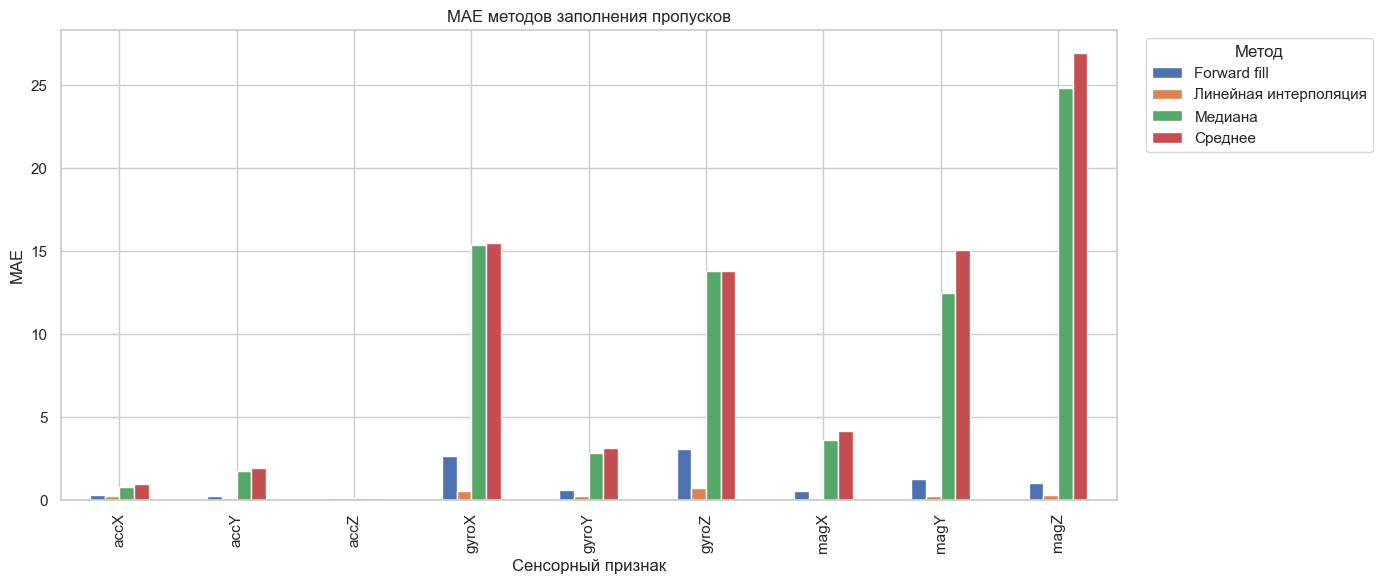

In [75]:
fig, ax = plt.subplots(figsize=(14, 6))

mae_table.plot(
    kind="bar",
    ax=ax
)

ax.set_title("MAE методов заполнения пропусков")
ax.set_xlabel("Сенсорный признак")
ax.set_ylabel("MAE")
ax.legend(title="Метод", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

In [76]:
# Признаки измеряются в разных единицах (м/с², °/с, мкТл), поэтому простое среднее MAE
# по признакам определялось бы в основном гироскопом и магнитометром.
# Для сводного сравнения нормируем ошибку на стандартное отклонение признака: MAE / σ.
feature_std = df[sensor_columns].std()

metrics_results["MAE / σ"] = metrics_results["MAE"] / metrics_results["feature"].map(feature_std)
metrics_results["RMSE / σ"] = metrics_results["RMSE"] / metrics_results["feature"].map(feature_std)

knn_metrics["MAE / σ"] = knn_metrics["MAE"] / knn_metrics["feature"].map(feature_std)
knn_metrics["RMSE / σ"] = knn_metrics["RMSE"] / knn_metrics["feature"].map(feature_std)

overall_metrics = (
    metrics_results
    .groupby("method")[["MAE / σ", "RMSE / σ"]]
    .mean()
    .sort_values("MAE / σ")
)

print("Вся выборка (8 749 пропусков на признак):")
display(overall_metrics.round(4))

print("Подвыборка из 10 000 строк (одни и те же пропуски):")
display(
    knn_metrics
    .groupby("method")[["MAE / σ", "RMSE / σ"]]
    .mean()
    .sort_values("MAE / σ")
    .round(4)
)

Вся выборка (8 749 пропусков на признак):


,MAE / σ,RMSE / σ
method,,
Линейная интерполяция,0.0991,0.1552
Forward fill,0.1569,0.2526
Медиана,0.5856,1.0417
Среднее,0.6465,1.0042


Подвыборка из 10 000 строк (одни и те же пропуски):


,MAE / σ,RMSE / σ
method,,
Линейная интерполяция,0.0967,0.1494
KNN,0.1271,0.2480


### 5.8. Визуальное сравнение восстановления

Рассмотрим небольшой участок временного ряда одного из сенсорных признаков. На нём сравним истинные значения, искусственно удалённые значения и результат линейной интерполяции.

Это позволяет визуально оценить, насколько восстановленная траектория соответствует исходному сигналу.

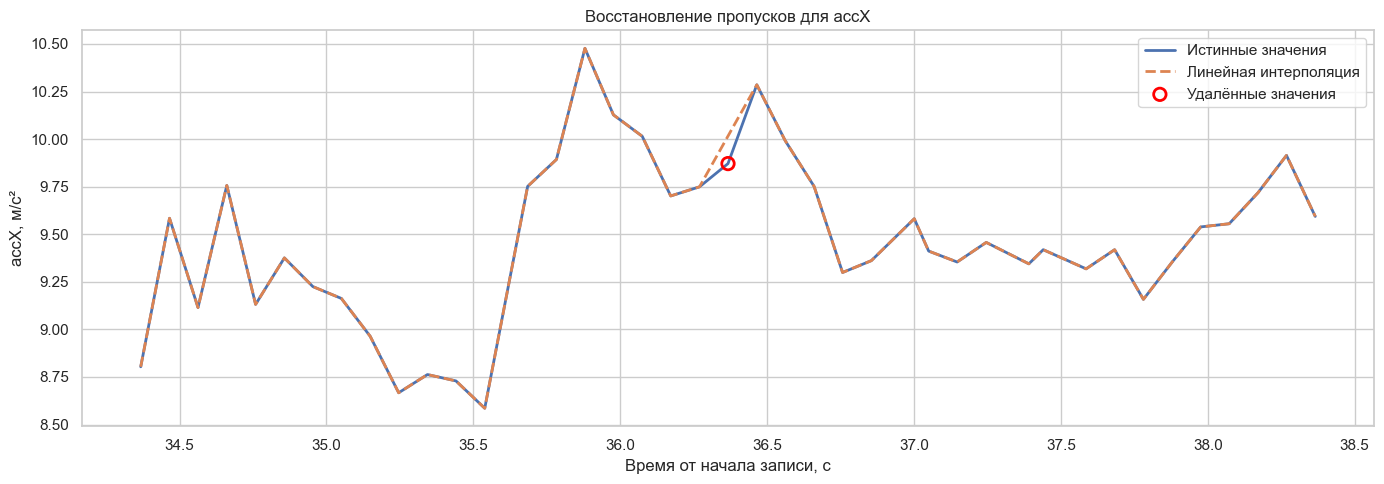

In [77]:
# Выберем accX и участок вокруг одного из искусственных пропусков
col = "accX"

missing_positions = np.where(missing_mask[col].to_numpy())[0]

# Первый пропуск, отстоящий от начала записи не менее чем на 20 наблюдений
center = missing_positions[missing_positions >= 20][0]

plot_index = df.index[center - 20: center + 21]

# Время в секундах от начала записи
t_sec = (df["time"] - df["time"].iloc[0]) / 1e9

removed = missing_mask.loc[plot_index, col]

plt.figure(figsize=(14, 5))

plt.plot(t_sec[plot_index], df.loc[plot_index, col], label="Истинные значения", linewidth=2)
plt.plot(t_sec[plot_index], df_interpolated.loc[plot_index, col],
         label="Линейная интерполяция", linestyle="--", linewidth=2)
plt.scatter(t_sec[plot_index][removed], df.loc[plot_index, col][removed],
            s=80, facecolors="none", edgecolors="red", linewidths=2, label="Удалённые значения", zorder=3)

plt.title(f"Восстановление пропусков для {col}")
plt.xlabel("Время от начала записи, с")
plt.ylabel(f"{col}, м/с²")
plt.legend()
plt.tight_layout()
plt.show()

### 5.9. Влияние длины блока пропусков

Случайные одиночные пропуски являются относительно простым случаем для восстановления временного ряда. В реальных данных потеря измерений может происходить блоками: например, из-за кратковременного сбоя датчика или передачи данных (в записи есть 429 интервалов длиннее 0.2 с).

Поэтому дополнительно исследуем влияние длины непрерывного блока пропусков: 1, 5, 10, 30, 50 и 100 последовательных наблюдений (0.1–10 с). Результат для одного блока сильно зависит от того, что происходило с манипулятором в этот момент, поэтому для каждой длины блок размещается в **200 случайных местах** записи, а ошибка усредняется. Блоки удаляются одновременно во всех сенсорных признаках, восстанавливаются методом forward fill и линейной интерполяцией по времени, ошибка нормируется на стандартное отклонение признака (MAE / σ) и усредняется по признакам.

Метод,Forward fill,Линейная интерполяция
Длина блока,,
1,0.1651,0.1079
5,0.2816,0.1380
10,0.3866,0.2082
30,0.6403,0.4659
50,0.7270,0.5930
100,0.7612,0.6622


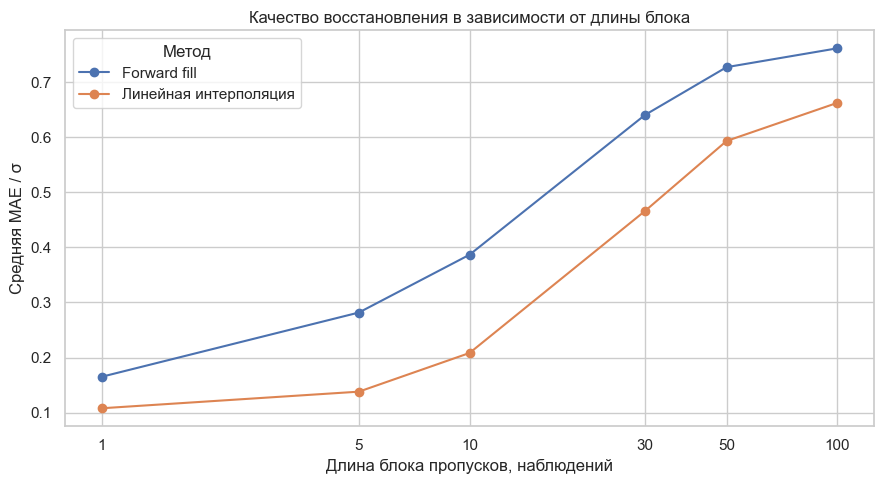

In [78]:
BLOCK_LENGTHS = [1, 5, 10, 30, 50, 100]
BLOCK_REPETITIONS = 200

block_rng = np.random.default_rng(RANDOM_STATE)

values = df[sensor_columns].to_numpy()
times = (df["time"] - df["time"].iloc[0]).to_numpy(dtype=float) / 1e9
stds = df[sensor_columns].std().to_numpy()

block_results = []

for block_length in BLOCK_LENGTHS:
    for _ in range(BLOCK_REPETITIONS):

        # Случайное положение блока (с запасом от краёв записи)
        start = block_rng.integers(1_000, len(df) - 1_000 - block_length)
        end = start + block_length

        true_block = values[start:end]

        # Forward fill: последнее известное значение перед блоком
        ffill_block = np.repeat(values[start - 1][None, :], block_length, axis=0)

        # Линейная интерполяция по времени между значениями до и после блока
        w = ((times[start:end] - times[start - 1]) / (times[end] - times[start - 1]))[:, None]
        interp_block = values[start - 1] + w * (values[end] - values[start - 1])

        for method_name, predicted in [("Forward fill", ffill_block), ("Линейная интерполяция", interp_block)]:
            block_results.append({
                "Длина блока": block_length,
                "Метод": method_name,
                "MAE / σ": np.mean(np.abs(true_block - predicted).mean(axis=0) / stds)
            })

block_results = (
    pd.DataFrame(block_results)
    .groupby(["Длина блока", "Метод"])["MAE / σ"]
    .mean()
    .unstack()
)

display(block_results.round(4))

ax = block_results.plot(marker="o", figsize=(9, 5))
ax.set_xscale("log")
ax.set_xticks(BLOCK_LENGTHS)
ax.set_xticklabels(BLOCK_LENGTHS)
ax.set_xlabel("Длина блока пропусков, наблюдений")
ax.set_ylabel("Средняя MAE / σ")
ax.set_title("Качество восстановления в зависимости от длины блока")
plt.tight_layout()
plt.show()

С ростом длины блока ошибка обоих методов быстро растёт: для линейной интерполяции средняя MAE / σ увеличивается с 0.11 (одиночный пропуск) до 0.21 при блоке из 10 наблюдений (1 с) и до 0.66 при блоке из 100 наблюдений (10 с). Для сравнения, заполнение средним даёт MAE / σ ≈ 0.65, т.е. на блоках длиной в несколько секунд интерполяция уже почти не лучше грубого заполнения средним: за это время манипулятор успевает совершить движение, которое по двум крайним точкам не восстановить.

Линейная интерполяция лучше forward fill при любой длине блока, но её преимущество уменьшается (0.11 против 0.17 для одиночных пропусков, 0.66 против 0.76 для блока из 100 наблюдений).

### Вывод

Для проверки методов заполнения пропусков в исходном датасете были искусственно созданы пропуски в 1% сенсорных измерений каждого признака. Исходные значения сохранены, что позволило непосредственно сравнить восстановленные значения с истинными по MAE и RMSE. Поскольку признаки измеряются в разных единицах, для сводного сравнения ошибка нормировалась на стандартное отклонение признака (MAE / σ).

1. **Одиночные случайные пропуски.** Линейная интерполяция по времени дала наименьшую ошибку для всех девяти признаков (средняя MAE / σ = 0.099), forward fill — 0.157, заполнение медианой и средним — 0.59 и 0.65. Заполнение средним и медианой игнорирует временную структуру и фактически заменяет пропуск «типичным» значением всей записи.
2. **Многомерный метод KNN** (sklearn `KNNImputer`, $k=5$, стандартизованные признаки) восстанавливает значение по остальным датчикам той же строки. На подвыборке из 10 000 строк его средняя MAE / σ = 0.127 против 0.097 у интерполяции на тех же пропусках. KNN оказался лучше интерполяции для `accX` и `accZ` (ускорение тесно связано с ориентацией, которую задают магнитометр и остальные оси), но заметно хуже для гироскопа и магнитометра: угловая скорость в конкретный момент плохо определяется остальными показаниями.
3. **Блоки пропусков.** Качество интерполяции быстро падает с длиной блока: при блоке из 100 наблюдений (10 с) MAE / σ = 0.66 — почти как при заполнении средним.

Таким образом, для одиночных пропусков в IMU-данных лучше всего использовать временную интерполяцию; для длинных разрывов ни один из рассмотренных одномерных методов не восстанавливает сигнал удовлетворительно, и имеет смысл комбинировать временную информацию с многомерной (например, KNN или модели, учитывающие и время, и другие датчики).

---
## 6. Проверка нормальности распределений

На данном этапе исследуем, насколько распределения сенсорных признаков согласуются с нормальным законом.

Для этого используем три группы методов:

1. графический анализ:
   - графики квантилей (Q-Q plots);
   - метод огибающих;

2. статистические критерии нормальности:
   - критерий Колмогорова–Смирнова в модификации Лиллиефорса;
   - критерий Шапиро–Уилка;
   - критерий Шапиро–Франсия;
   - критерий Андерсона–Дарлинга;
   - критерий Крамера–фон Мизеса;

3. исследование влияния объёма выборки на результаты критериев.

Для всех критериев проверяются гипотезы

$$
H_0: X \sim N(\mu,\sigma^2),
$$

$$
H_1: X \not\sim N(\mu,\sigma^2).
$$

При уровне значимости

$$
\alpha=0.05
$$

если $p < \alpha$, нулевая гипотеза о нормальности отвергается.

Важно учитывать, что статистический критерий не доказывает нормальность при $p \geq \alpha$: в этом случае лишь отсутствуют основания отвергнуть $H_0$.

Кроме того, при очень больших объёмах выборки критерии нормальности становятся чрезвычайно чувствительными к небольшим отклонениям от нормального распределения. Поэтому для датасета, содержащего сотни тысяч наблюдений, результаты необходимо интерпретировать совместно с графиками и характеристиками формы распределения.

### Применимость используемых методов

**Критерий Лиллиефорса** является модификацией критерия Колмогорова–Смирнова для ситуации, когда параметры нормального распределения оцениваются по самой выборке. Это важно для наших данных, поскольку математическое ожидание и стандартное отклонение заранее неизвестны.

**Критерий Шапиро–Уилка** обладает высокой мощностью для небольших и умеренных выборок. В используемой реализации `scipy.stats.shapiro` статистика рассчитывается и для больших выборок, однако для $n>5000$ точность $p$-value ограничена. Поэтому в работе будем использовать выборки не более 5000 наблюдений.

**Критерий Шапиро–Франсия** основан на квадрате корреляции между упорядоченными наблюдениями и ожидаемыми нормальными квантилями. В реализации с приближением Ройстона он применяется для выборок от 5 до 5000 наблюдений. Поэтому, как и для Шапиро–Уилка, ограничим максимальный объём выборки 5000 наблюдениями.

**Критерий Андерсона–Дарлинга** относится к критериям согласия и особенно чувствителен к отклонениям в хвостах распределения. Для нормального распределения функция `scipy.stats.anderson` возвращает статистику и критические значения для нескольких уровней значимости. Поэтому решение принимается сравнением статистики с соответствующим критическим значением.

**Критерий Крамера–фон Мизеса** оценивает суммарное расхождение эмпирической функции распределения с теоретической. В отличие от критерия Андерсона–Дарлинга он не придаёт настолько сильного дополнительного веса хвостам.

Для критериев Лиллиефорса и Крамера–фон Мизеса параметры нормального распределения оцениваются по соответствующей выборке.

Таким образом, применение критериев будет проводиться не только на всей доступной выборке, но и на выборках различных размеров. Это позволит отделить реальные особенности распределения от эффекта чрезмерной статистической мощности на больших $n$.

In [79]:
from scipy import stats
from scipy.stats import norm
from statsmodels.stats.diagnostic import lilliefors

ALPHA = 0.05
NORMALITY_RANDOM_STATE = 42

# Объёмы выборок
SAMPLE_SIZES = [50, 100, 500, 1000, 5000]

# Число повторений для каждого n и каждого признака
NORMALITY_REPETITIONS = 200

# Число bootstrap-выборок для калибровки CVM
CVM_BOOTSTRAP = 1000

rng = np.random.default_rng(
    NORMALITY_RANDOM_STATE
)

print(
    "Объёмы выборок:",
    SAMPLE_SIZES
)

print(
    "Число повторений:",
    NORMALITY_REPETITIONS
)

Объёмы выборок: [50, 100, 500, 1000, 5000]
Число повторений: 200


In [80]:
import numpy as np
from scipy.stats import norm


def shapiro_francia_test(x):
    """
    Критерий Шапиро–Франсия для проверки нормальности.

    Возвращает:
        W  — статистику критерия
        p  — приближённое p-value
    """
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]

    n = len(x)

    if n < 5:
        raise ValueError("Для критерия Шапиро–Франсия нужно не менее 5 наблюдений.")

    if n > 5000:
        raise ValueError(
            "Для используемой аппроксимации рекомендуется n <= 5000."
        )

    if np.ptp(x) == 0:
        raise ValueError("Критерий не определён для постоянной выборки")

    # Сортируем выборку
    x_sorted = np.sort(x)

    # Теоретические квантили стандартного нормального распределения
    p = (np.arange(1, n + 1) - 3 / 8) / (n + 1 / 4)
    m = norm.ppf(p)

    # Статистика Шапиро–Франсия
    W = np.corrcoef(x_sorted, m)[0, 1] ** 2

    # Приближённое p-value
    u = np.log(n)
    v = np.log(u)

    mu = -1.2725 + 1.0521 * (v - u)
    sigma = 1.0308 - 0.26758 * (v + 2 / u)

    z = (np.log(max(1 - W, np.finfo(float).eps)) - mu) / sigma
    p_value = norm.sf(z)

    return W, p_value

In [81]:
def cvm_statistic_standardized(x):
    """
    Статистика Крамера–фон Мизеса после
    стандартизации выборки по её собственным
    среднему и стандартному отклонению.
    """
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]

    mu = np.mean(x)
    sigma = np.std(x, ddof=1)

    if sigma == 0:
        return np.nan

    z = np.sort((x - mu) / sigma)

    n = len(z)

    i = np.arange(1, n + 1)

    F = norm.cdf(z)

    W2 = (
        1 / (12 * n)
        + np.sum(
            (
                F - (2 * i - 1) / (2 * n)
            ) ** 2
        )
    )

    return W2

In [82]:
cvm_bootstrap_null = {}

for n in SAMPLE_SIZES:

    bootstrap_stats = np.empty(
        CVM_BOOTSTRAP
    )

    for i in range(CVM_BOOTSTRAP):

        sample = rng.standard_normal(n)

        bootstrap_stats[i] = (
            cvm_statistic_standardized(sample)
        )

    cvm_bootstrap_null[n] = np.sort(
        bootstrap_stats
    )

print(
    "Bootstrap-калибровка CVM выполнена "
    "для размеров:",
    SAMPLE_SIZES
)

Bootstrap-калибровка CVM выполнена для размеров: [50, 100, 500, 1000, 5000]


In [83]:
def normality_tests(x, cvm_null=None):
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]

    n = len(x)

    # 1. Лиллиефорс
    lillie_stat, lillie_p = lilliefors(
        x,
        dist="norm",
        pvalmethod="table"
    )

    # 2. Шапиро–Уилк
    shapiro_stat, shapiro_p = stats.shapiro(x)

    # 3. Шапиро–Франсия
    sf_stat, sf_p = shapiro_francia_test(x)

    # 4. Андерсон–Дарлинг
    ad_result = stats.anderson(
        x,
        dist="norm"
    )

    alpha_idx = np.argmin(
        np.abs(
            ad_result.significance_level - 5.0
        )
    )

    ad_critical = (
        ad_result.critical_values[
            alpha_idx
        ]
    )

    # 5. Крамер–фон Мизес
    cvm_stat = cvm_statistic_standardized(x)

    if cvm_null is not None:
        # Bootstrap p-value.
        # +1 — стандартная поправка для конечного
        # числа bootstrap-репликаций.
        p_cvm = (
            np.sum(cvm_null >= cvm_stat) + 1
        ) / (len(cvm_null) + 1)
    else:
        p_cvm = np.nan

    return {
        "Lilliefors_stat": lillie_stat,
        "Lilliefors_p": lillie_p,

        "Shapiro_W": shapiro_stat,
        "Shapiro_p": shapiro_p,

        "Shapiro_Francia_W": sf_stat,
        "Shapiro_Francia_p": sf_p,

        "Anderson_stat": ad_result.statistic,
        "Anderson_critical_5%": ad_critical,

        "Anderson_normal_at_0.05": (
            ad_result.statistic < ad_critical
        ),

        "Cramer_von_Mises_stat": cvm_stat,
        "Cramer_von_Mises_p": p_cvm
    }

In [84]:
all_normality_results = []

for n in SAMPLE_SIZES:

    print(f"Обрабатывается n = {n}")

    for col in sensor_columns:

        x = df[col].dropna().to_numpy()

        for repetition in range(
            NORMALITY_REPETITIONS
        ):

            sample = rng.choice(
                x,
                size=n,
                replace=False
            )

            result = normality_tests(
                sample,
                cvm_null=cvm_bootstrap_null[n]
            )

            result["feature"] = col
            result["n"] = n
            result["repetition"] = repetition

            all_normality_results.append(
                result
            )

all_normality_results = pd.DataFrame(
    all_normality_results
)

print(
    "Всего результатов:",
    len(all_normality_results)
)

Обрабатывается n = 50


Обрабатывается n = 100


Обрабатывается n = 500


Обрабатывается n = 1000


Обрабатывается n = 5000


Всего результатов: 9000


In [85]:
rejection_rates = (
    all_normality_results
    .groupby(["feature", "n"])
    .agg(
        Lilliefors=(
            "Lilliefors_p",
            lambda x: np.mean(x < ALPHA)
        ),

        Shapiro_Wilk=(
            "Shapiro_p",
            lambda x: np.mean(x < ALPHA)
        ),

        Shapiro_Francia=(
            "Shapiro_Francia_p",
            lambda x: np.mean(x < ALPHA)
        ),

        Anderson_Darling=(
            "Anderson_normal_at_0.05",
            lambda x: np.mean(~x)
        ),

        Cramer_von_Mises=(
            "Cramer_von_Mises_p",
            lambda x: np.mean(x < ALPHA)
        )
    )
    .reset_index()
)

display(
    rejection_rates.round(3)
)

,feature,n,Lilliefors,Shapiro_Wilk,Shapiro_Francia,Anderson_Darling,Cramer_von_Mises
0,accX,50,1.000,1.000,1.000,1.000,1.000
1,accX,100,1.000,1.000,1.000,1.000,1.000
2,accX,500,1.000,1.000,1.000,1.000,1.000
3,accX,1000,1.000,1.000,1.000,1.000,1.000
4,accX,5000,1.000,1.000,1.000,1.000,1.000
5,accY,50,1.000,1.000,1.000,1.000,1.000
6,accY,100,1.000,1.000,1.000,1.000,1.000
7,accY,500,1.000,1.000,1.000,1.000,1.000
8,accY,1000,1.000,1.000,1.000,1.000,1.000
9,accY,5000,1.000,1.000,1.000,1.000,1.000


### Влияние объёма выборки на результаты критериев

Для каждого признака построим зависимость доли отвергнутых гипотез о нормальности от объёма выборки. Доля рассчитана по 200 случайным подвыборкам каждого размера.

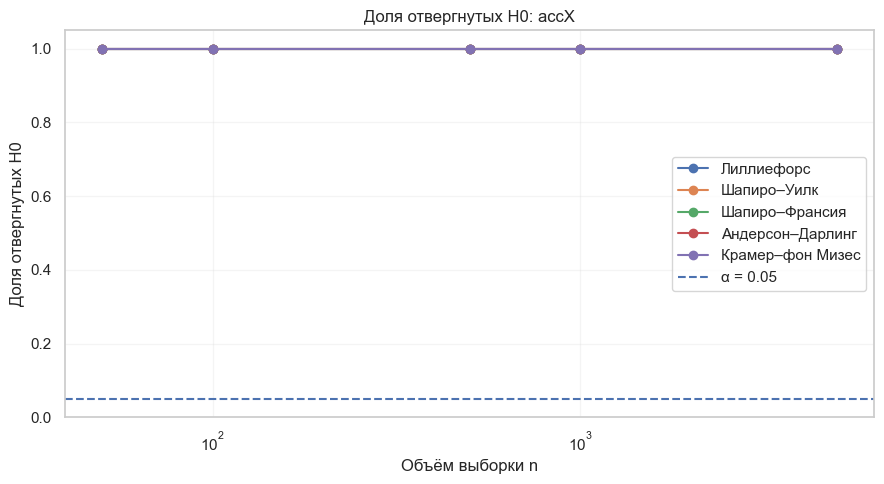

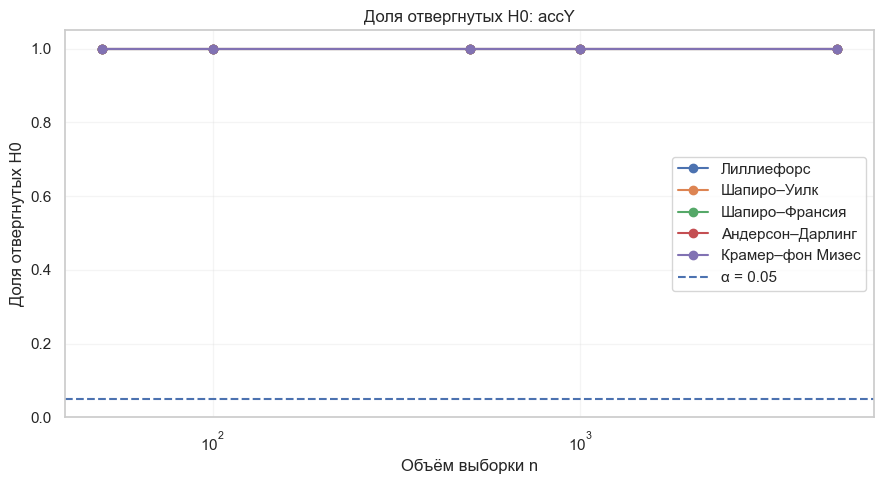

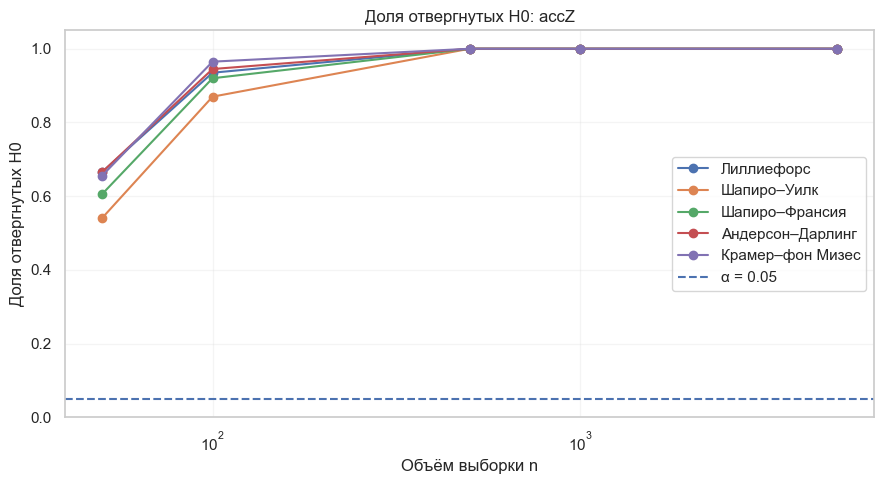

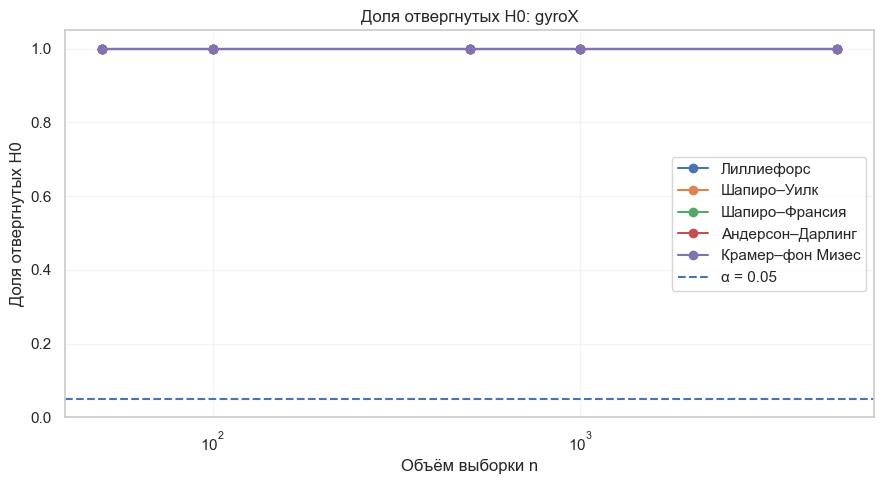

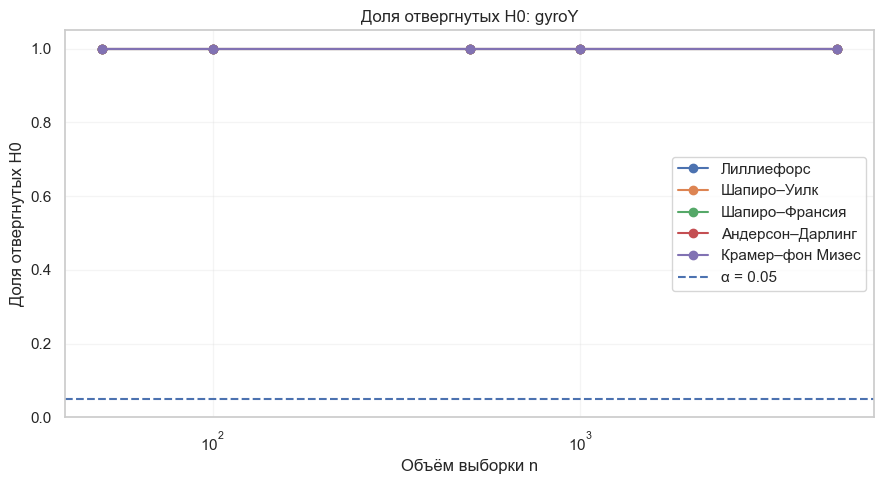

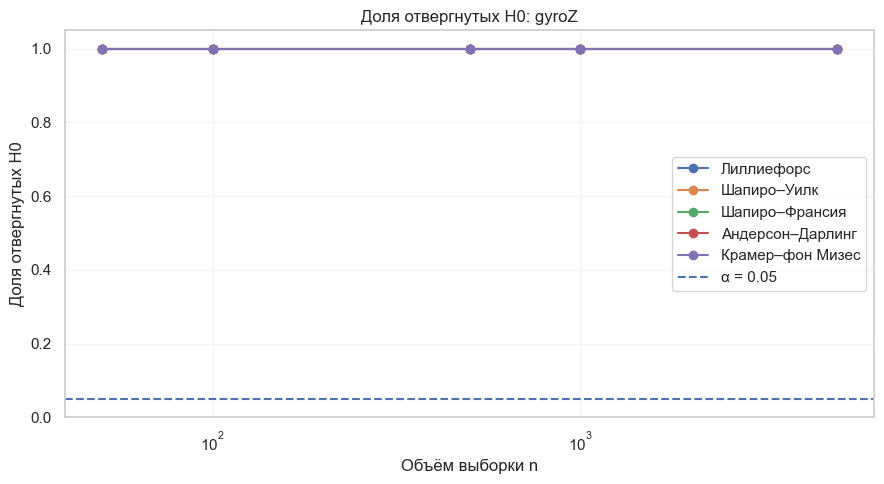

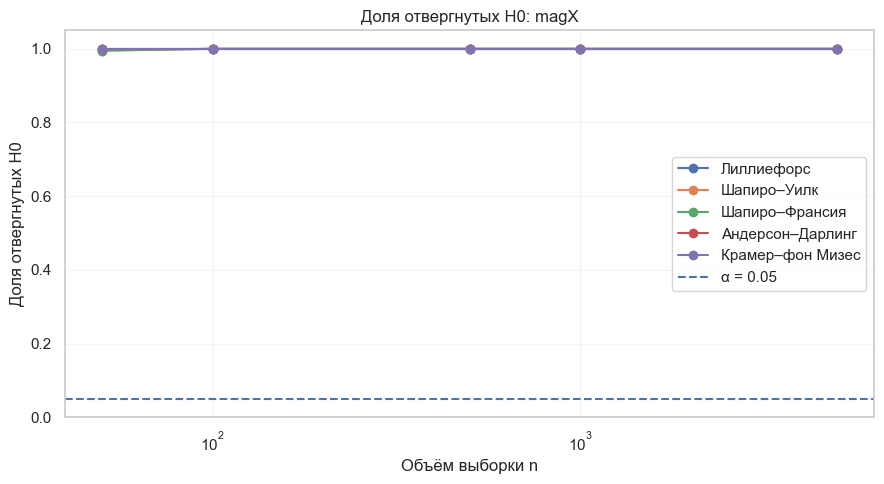

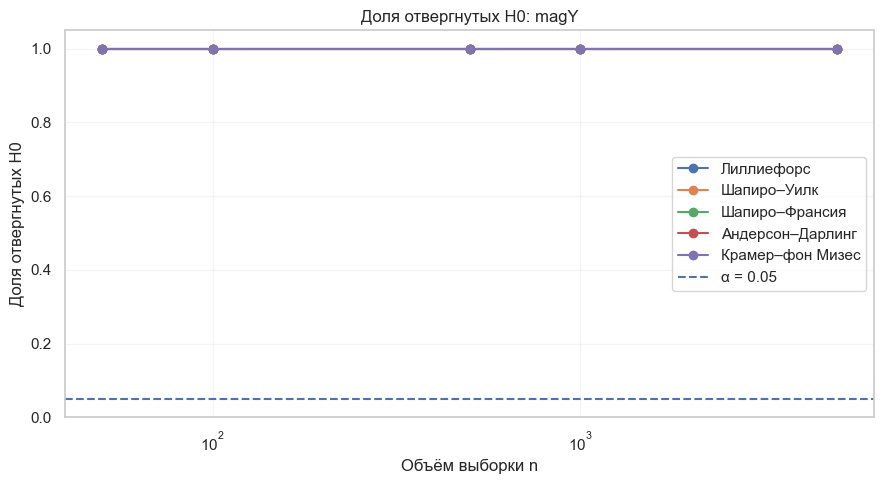

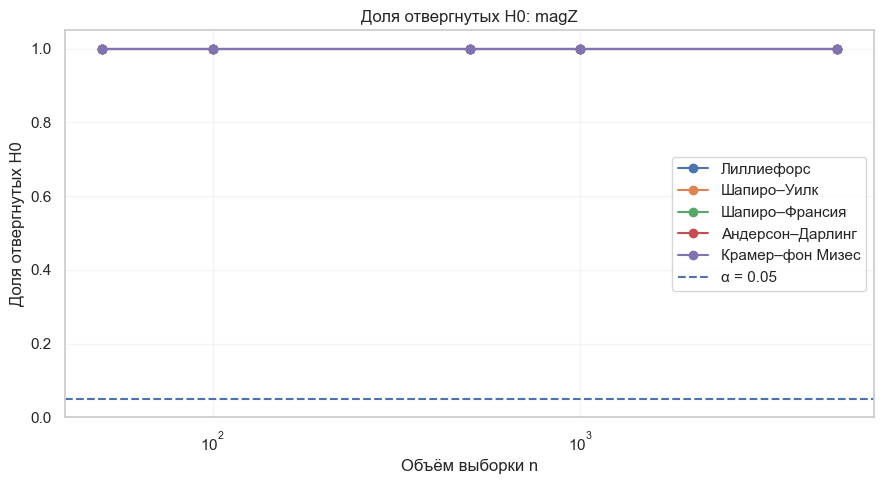

In [86]:
criteria = {
    "Lilliefors": "Лиллиефорс",
    "Shapiro_Wilk": "Шапиро–Уилк",
    "Shapiro_Francia": "Шапиро–Франсия",
    "Anderson_Darling": "Андерсон–Дарлинг",
    "Cramer_von_Mises": "Крамер–фон Мизес"
}

for col in sensor_columns:

    subset = rejection_rates[
        rejection_rates["feature"] == col
    ]

    fig, ax = plt.subplots(
        figsize=(9, 5)
    )

    for criterion, label in criteria.items():

        ax.plot(
            subset["n"],
            subset[criterion],
            marker="o",
            label=label
        )

    ax.axhline(
        0.05,
        linestyle="--",
        label="α = 0.05"
    )

    ax.set_xscale("log")

    ax.set_ylim(0, 1.05)

    ax.set_title(
        f"Доля отвергнутых H0: {col}"
    )

    ax.set_xlabel(
        "Объём выборки n"
    )

    ax.set_ylabel(
        "Доля отвергнутых H0"
    )

    ax.legend()

    ax.grid(
        alpha=0.2
    )

    plt.tight_layout()
    plt.show()

### Вывод

Q-Q графики с поточечной 95%-ной нормальной огибающей показывают, что для всех признаков от 80% (`accZ`) до 96% (`magY`) точек стандартизованной выборки лежат за пределами огибающей. Для гироскопа и магнитометра видны «полки» и скачки, соответствующие режимам покоя и движения; для `accZ` отклонение умеренное (S-образный изгиб: острый пик и тяжёлые хвосты).

Каждый из пяти критериев применялся к 200 случайным подвыборкам для каждого $n$; итоговая характеристика — доля подвыборок, в которых $H_0$ отвергается при $\alpha=0.05$. Для критерия Крамера–фон Мизеса p-value вычислялось по моделированию (параметрический бутстреп), поскольку параметры нормального распределения оцениваются по той же выборке и табличные p-значения в этом случае завышены.

- Для восьми признаков из девяти все критерии отвергают нормальность практически в 100% подвыборок уже при $n=50$: отклонения от нормальности настолько велики, что их обнаруживает даже малая выборка.
- Единственный признак с умеренным отклонением — `accZ`. При $n=50$ доля отвержений составляет 0.54 (Шапиро–Уилк), 0.61 (Шапиро–Франсия), 0.66 (Крамер–фон Мизес) и 0.67 (Лиллиефорс, Андерсон–Дарлинг); при $n=100$ — 0.87–0.97; при $n\ge500$ — 1.00 для всех критериев. На этом признаке хорошо видно влияние объёма выборки на мощность критериев.
- Для `accZ` критерии Андерсона–Дарлинга и Лиллиефорса дали большую долю отвержений, чем Шапиро–Уилк; это не универсальное сравнение мощности: отклонение связано в основном с хвостами и островершинностью, к которым критерий Андерсона–Дарлинга особенно чувствителен.

При этом $p<0.05$ означает статистически значимое отклонение, но не характеризует его величину. В данном случае отклонения большие (они видны на графиках и обнаруживаются уже при $n=50$), поэтому речь идёт не об эффекте избыточной мощности на больших выборках, а о действительно ненормальных распределениях — смесях режимов работы манипулятора. Для сравнения: на стационарном участке (п. 4.5.1) нормальность `accZ` не отвергается.

---
# Общие выводы

В работе был проведён комплексный статистический анализ временного ряда измерений IMU, содержащего 874 937 наблюдений. Данные представляют собой длительную запись работы одного модуля с частотой около 10 Гц и включают показания акселерометра, гироскопа и магнитометра. Временные метки возрастают, однако интервалы между измерениями не являются строго постоянными, что необходимо учитывать при анализе временной структуры данных.

На первом этапе было установлено, что в исходном наборе отсутствуют явные пропуски и полные дубликаты, однако обнаружено одно подозрительное наблюдение: в первой строке показания магнитометра одновременно равны нулю. Кроме того, анализ временных интервалов показал наличие увеличенных интервалов между измерениями, которые не представлены в данных в виде `NaN`. Сенсорные признаки также являются квантованными, а для гироскопа характерно большое количество точных нулей, соответствующих состоянию покоя манипулятора.

Исследование распределений с помощью гистограмм и ядерных оценок плотности показало, что сенсорные данные существенно отличаются от простых одномодальных нормальных распределений. Наблюдаются асимметрия, несколько мод, тяжёлые хвосты и выраженные пики, особенно характерные для гироскопа. Причём для некоторых признаков стандартные правила выбора ширины окна KDE приводят к чрезмерному сглаживанию. Подбор ширины окна по данным позволяет лучше сохранить локальную структуру распределений. При этом для гироскопа непрерывная KDE не может полностью воспроизвести выраженный пик в нуле, поскольку значительная часть наблюдений имеет одно и то же точное значение. Поэтому распределение таких признаков целесообразно рассматривать как сочетание дискретной и непрерывной составляющих.

Визуальный анализ показал наличие выраженной зависимости между сенсорными признаками. Условные распределения и двумерные диаграммы рассеяния выявили нелинейные взаимосвязи и различные области концентрации наблюдений. Одновременно данные явно разделяются на два основных режима работы манипулятора: состояние покоя и движение. В покое показания гироскопа сосредоточены около нуля, а значения акселерометра и магнитометра находятся в относительно узкой области. При движении разброс сенсорных показателей значительно возрастает. Эта особенность имеет принципиальное значение для дальнейшего анализа, поскольку объединение различных режимов в одну выборку приводит к сложной, многомодальной структуре распределений.

Анализ потенциальных выбросов показал, что формальное определение выброса существенно зависит от выбранного метода. Метод IQR выделяет очень большую долю наблюдений, особенно для гироскопа и `accY`, однако эти наблюдения в основном соответствуют обычному режиму движения манипулятора, а не ошибкам измерения. Z-оценки, напротив, могут маскировать экстремальные значения в широких и многомодальных распределениях. Критерий Граббса и обобщённый ESD также требуют выполнения предпосылки нормальности и поэтому ограниченно применимы ко всей записи.

Показательный пример — значение `accZ = 1.908`, которое критерий Граббса определил как статистически экстремальное. Анализ временного окружения показал, что оно возникло во время быстрого поворота манипулятора и не выделяется среди соседних наблюдений. Это согласуется с реальным динамическим измерением, но не доказывает отсутствие ошибки датчика. На стационарном участке, где предпосылки критерия выполняются лучше, Граббс и ESD выбросов не обнаружили. Это показывает, что для временных данных IMU определять аномалии только относительно глобального распределения некорректно: необходимо учитывать текущий режим работы и соседние во времени наблюдения.

Многомерные методы Isolation Forest и LOF также выявили разные группы аномальных наблюдений. Это связано с тем, что Isolation Forest преимущественно реагирует на глобальную экстремальность, а LOF — на локальную плотность. Поэтому результаты этих методов практически не совпадают. В частности, Isolation Forest преимущественно выделяет наблюдения, соответствующие быстрым движениям, тогда как LOF способен обнаруживать редкие точки внутри отдельных локальных режимов. Единственное подозрительное наблюдение в строке 0 было обнаружено несколькими методами, но не Isolation Forest. Таким образом, автоматические алгоритмы аномалий нельзя рассматривать как универсальный способ отделения ошибок измерения от реальных физических состояний системы.

Отдельно была исследована задача восстановления пропущенных значений. Поскольку в исходных данных явных `NaN` нет, в сенсорные признаки искусственно внесли 1% пропусков, сохранив исходные значения в качестве эталона. Для одиночных пропусков наиболее точной оказалась линейная интерполяция по времени (средняя нормированная ошибка MAE / σ = 0.099 против 0.157 у forward fill и 0.59–0.65 у медианы и среднего). Многомерный метод KNN (MAE / σ = 0.127) выигрывает у интерполяции для `accX` и `accZ`, но проигрывает для гироскопа и магнитометра. При блочных пропусках качество интерполяции быстро падает: для блока из 100 наблюдений (10 с) ошибка почти равна ошибке заполнения средним.

Проверка нормальности проводилась с помощью Q-Q-графиков, нормальной огибающей и пяти статистических критериев: Лиллиефорса, Шапиро–Уилка, Шапиро–Франсия, Андерсона–Дарлинга и Крамера–фон Мизеса (с бутстреп-калибровкой p-value). Для восьми признаков из девяти все критерии отвергают нормальность практически в 100% из 200 подвыборок уже при $n=50$, а 80–96% точек Q-Q графика лежат вне огибающей. Только для `accZ` видно влияние объёма выборки: доля отвержений растёт с 0.54–0.67 при $n=50$ до 1.00 при $n\ge500$. Отклонения от нормальности здесь велики и обусловлены смесью режимов работы манипулятора, а не избыточной мощностью критериев на больших выборках.

В целом проведённый анализ показывает, что IMU-данные имеют сложную многомерную и временную структуру, которая не может быть адекватно описана только простыми статистическими характеристиками или предположением о нормальности распределений. При анализе выбросов и пропусков важно учитывать временную зависимость и различные режимы работы манипулятора, а результаты статистических критериев следует рассматривать в совокупности с графическим анализом и предметным контекстом измерений.
### Ограничения интерпретации

- Режимы «покой» и «движение» определены эвристическим порогом гироскопа, а не внешней разметкой.
- Нулевая первая строка магнитометра — подозрение на инициализацию, не подтверждённая ошибка.
- Временная зависимость и квантование нарушают стандартную непрерывную i.i.d.-модель критериев нормальности. Повторные случайные подвыборки описывают эту запись; доля отвержений не является вероятностью ошибки датчика или оценкой нормальности генеральной совокупности.
- Q-Q-огибающая поточечная, не одновременная 95%-ная полоса.
- Интерполяция использует будущие значения: эксперимент относится к офлайн-восстановлению, не к прогнозу или обработке в реальном времени. KNN обучается на 10 000 строках, а интерполяция использует полный временной ряд: сравнение идёт на общих пропусках, но при разных доступных контекстах.
- Кросс-валидация KDE исследует маргинальное распределение случайной подвыборки, не качество прогноза на будущих временных отрезках. Пересчёт bandwidth по n⁻¹⁄⁵ — эвристика; добавление шума при деквантовании меняет распределение на малых масштабах.
- Численные выводы исходного практикума относятся к полной записи; таблицы текущего выполнения имеют приоритет над округлёнными числами в тексте.
